# Experiment 5. The geometry of the pair: whose shape does the separating level curve carry

## Why this experiment

The programme asks whether an individual hidden neuron of a trained network works as a **structural
witness** of a topological feature: whether there is a level `c` whose level curve
`{x : f(x) = c}` coincides with the set `A` we are interested in. Experiments 1 and 2 answered "yes"
for a circle with a disk of the opposite class inside it, and measured how this depends
on the architecture.

But that setting has a blind spot, and a fundamental one. The circle and the disk inside it are
**both round and concentric**. The separating level curve lives in the gap between them, and in such a
configuration the hypothesis "the neuron repeats the feature" and the hypothesis "the neuron encircles the interior"
predict one and the same picture. There they cannot be told apart in principle: experiments 1 and 2
measured at a **degenerate point**.

Experiment 5 takes the system out of this point. The object of study here is not the feature but the **pair
(feature, interior)**. We change the shape of each object separately, turn one relative to
the other, shift one relative to the other — and each time ask which of the two the
level curve has followed.

## One idea that the whole notebook tests

Everything that follows serves one statement, and it is worth naming it at once, so that each section reads
as a step towards it:

> **The feature sets the bounds of the possible, and the interior is what is chosen within those bounds.**

Each block tests this statement in its own way and on its own quantity: block A on the shape of
the curve, block B on its direction, block C on what is not geometry at all, block D
on its position. No block on its own proves the statement in full; together they
cover it from four sides.

## Tasks

| | block | what is varied | the answer |
|---|---|---|---|
| **0** | Foundation | — | the detector is the same as in experiments 1–2; each cell has its own floor; the scale of the new descriptor |
| **1** | Instrument | — | how the shape of the curve is measured and with what accuracy |
| **2** | **A.** Shape against shape | feature aspect × interior aspect, 16 cells | the shape of the curve is moved above all by the interior; the curve is rounder than both |
| **3** | **B.** Orientation | the same aspects, the interior turned across; **the feature is bitwise the same** | the direction is set by both objects, but when the axes collide the interior wins |
| **4** | **C.** Density of the description | the same geometry with 200 / 500 / 800 points in the interior | the shape does not follow from geometry alone: the data move it too |
| **5** | **D.** Position | the interior shifted along and across | the curve follows the interior exactly as far as the feature allows |
| **6** | Synthesis | everything together | what follows from this for the programme |
| **7** | Results | — | the final statements and their limits |

**The order is not arbitrary.** Section 0 lays the foundation that all the others refer to, section 1
the instrument. Block A poses the question and proposes three constructions that could describe the answer.
Block B tests them in the hardest way the design allows — by direction, where a miss
cannot be put down to calibration. Block C tests whether geometry is enough at all. Block D removes
the last restriction — concentricity — and shows where the power of the interior ends.

*(In the experiment plan block B is called A⊥, and the letters A, C, D are historical. Here the blocks
are renumbered in order of appearance; the dataset identifiers have not changed.)*

*In the paper this is Experiment 4, Section 10. The notebooks keep the numbering of the research log, so experiment 4 mentioned below is the paper's Experiment 3; experiments 1 and 2 are numbered the same in both.*


## How to read the numbers

Two families of numbers live in the table, and they answer different questions.

**The structural score** `structural_score_normalized_by_diameter` is the detector of experiments 1, 2
and 4 without a single change: the max-symmetrised Chamfer distance from the best component of the
level curve to the **feature**, divided by the diameter of the feature. Smaller is closer.

**The harmonic descriptor** `harmonic_*` is the new instrument of this experiment and
the main one of the four. The criterion answers "did the curve coincide with the target"; the descriptor
answers "**what shape** it is and **whose** shape it is". It is taken apart in full in
**section 1**: what it measures, how the distance between shapes is computed, what its scale
and resolution are, and what it sees on real data. All geometric conclusions of the
experiment rest on it; the structural and homological criteria are needed for
stitching to experiments 1, 2 and 4 and as a check that things work.

Three conventions, inherited from the previous experiments and in force here without exception:

1. **There are two units of observation, and they apply to different questions** — they must not be
   confused, so each figure says which one is used.
   *Extremum over neurons.* A pair (cell, model), valued by its **best** neuron. This is how
   everything related to the structural criterion is computed, and everything that answers the question "was
   **at least one** such neuron found" — that is, the witness fraction and sections 2.1, 2.3, 2.4. The bootstrap
   then resamples models, never neurons.
   *Median over all curves.* The unit is a single described curve, a pair (neuron, rung); a
   cell has about 2,400 of them. This is how everything is computed that answers the question "where does **the family
   as a whole** go" — sections 2.2, 2.5, 2.6 and blocks B, C, D. Not the mean (robustness to tails) and not
   the extremum (the question is different).
2. **Each cell takes its own threshold** — the **1st percentile** of the scores of its own null
   placements. The percentile is chosen strict on purpose: a false positive costs more here than
   a miss — a criterion that fired on a feature the task does not see calls into question
   the very notion of relevance. The 5th percentile is always printed next to it, so that it is visible
   that the conclusion does not depend on the choice. The threshold `τ = 0.1` of experiments 1–2 is normalised by the diameter, and the diameter here changes
   fourfold, so it cannot be inherited (section 0.3).
3. **A witness fraction of 0.01 is the chance level**, not a small effect: the floor is the 1st
   percentile of the nulls. This is the NAME OF A RULE, not a measured error rate: on nulls that
   took no part in setting the threshold, the realised value is two to three times above nominal.


In [1]:
import os
import sys
from pathlib import Path

root = Path.cwd()
while not (root / "src" / "analysis").is_dir():
    assert root != root.parent, "repository root not found"
    root = root.parent
os.chdir(root)
if str(root / "src") not in sys.path:
    sys.path.insert(0, str(root / "src"))

import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import analysis.geometry_sweep as gs
import visualization.geometry_sweep_plots as gp
from experiments.exp5_plan import derived_plan

pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110

ramp = plt.cm.plasma(np.linspace(.05, .8, 5))     # colour of a ladder rung
COL = {1.0: "#2c7a4b", 1.5: "#1f77b4",
       2.5: "#e08214", 4.0: "#d62728"}            # colour of the feature aspect

df     = gs.load_neuron_stats()                 # 320,000 rows: neuron x feature
best   = gs.best_by_model(df)                   # (cell, model, feature) -> best neuron
cells  = gs.cell_table(best)                    # cell -> score, floor, witness fraction
curves = gs.curve_shape_table(df)               # cell -> the level curve's own shape
ladder = gs.ladder_long(df, "value")            # ladder rungs, per neuron
shape  = gs.shape_by_cell(ladder)
mid    = shape[shape.rung == 2]                 # middle rung — symmetric between the objects
pos    = gs.position_table(df)
PLAN   = {c["name"]: c for c in derived_plan()}   # geometry of the cells
CO     = gs.cell_coordinates().set_index("dataset_type")  # offsets, scales

plan = {b: sorted(g.dataset_type) for b, g in cells.groupby("block")}
cells_meta = cells.set_index("dataset_type")            # cell labels for captions
floors = cells_meta["floor"].to_dict()                  # floor of each cell

print(f"rows                 {len(df):,}".replace(",", " "))
print(f"cells                {cells.dataset_type.nunique()}")
print(f"models per cell      {best[best.feature_role=='target'].groupby('dataset_type').size().unique()}")
print(f"nulls in total       {int(cells.n_nulls.sum())}")
print(f"cells per block      { {b: len(v) for b, v in plan.items()} }")


rows                 320 000
cells                56
models per cell      [50]
nulls in total       200
cells per block      {'A': 16, 'A⊥': 9, 'C': 8, 'D': 23}


---
# 0. Foundation

Three things must be established before everything else, because every following section
refers to them: what the data themselves look like, whether the detector reads here the same as it read in
experiment 1, and what the numbers of the new descriptor mean.

## 0.1 What is measured here: all 56 cells

Each cell is a pair of a closed curve (**the feature**, class 0, dark) and a filled region
inside it (**the interior**, class 1, orange). The network learns to separate them; the separating
surface has to lie in the gap between them.

Below, all 56 cells are drawn, block by block. All panels of one block are given in **one frame**, so
that the elongation is visible by eye and comparable between panels. Note two things: the feature
keeps its minor semi-axis (as it elongates, it grows outward), while the interior keeps its major one (as it elongates,
it gets thinner) — so an elongated interior is also a narrower interior.

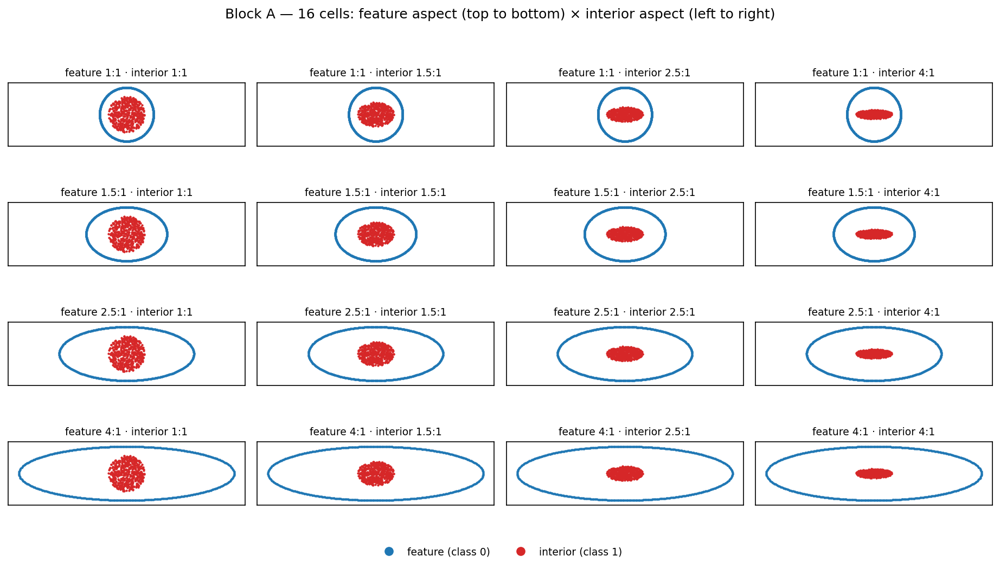

In [2]:
fig = gp.plot_cell_gallery(
    plan["A"],
    [f"feature {r.feature_aspect:g}:1 · interior {r.interior_aspect:g}:1"
     for r in cells_meta.loc[plan["A"]].itertuples()],
    ncols=4,
    suptitle="Block A — 16 cells: feature aspect (top to bottom) × interior aspect (left to right)")
plt.show()

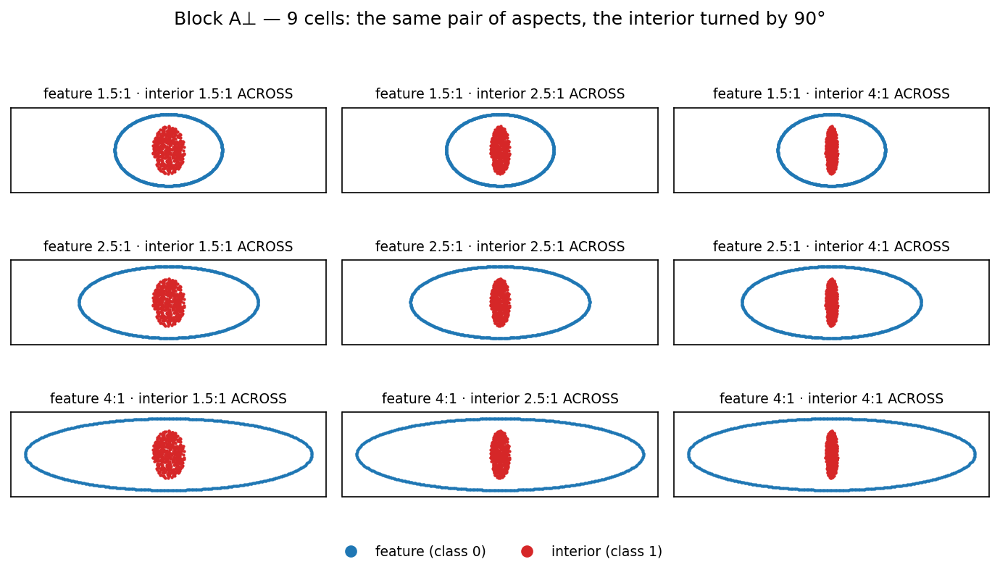

In [3]:
fig = gp.plot_cell_gallery(
    plan["A⊥"],
    [f"feature {r.feature_aspect:g}:1 · interior {r.interior_aspect:g}:1 ACROSS"
     for r in cells_meta.loc[plan["A⊥"]].itertuples()],
    ncols=3,
    suptitle="Block A⊥ — 9 cells: the same pair of aspects, the interior turned by 90°")
plt.show()

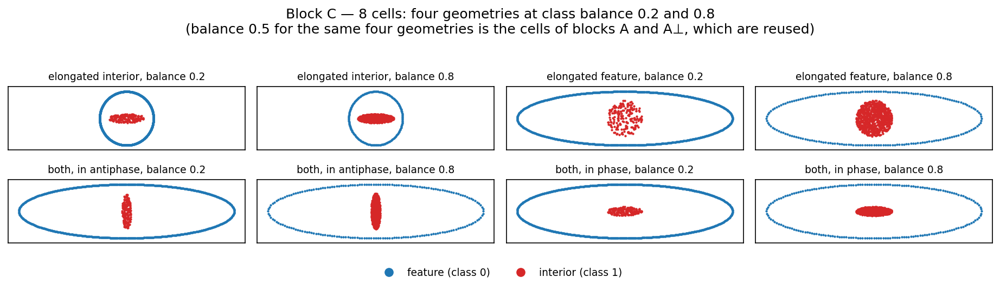

In [4]:
fig = gp.plot_cell_gallery(
    plan["C"],
    [f"{r.label}" for r in cells_meta.loc[plan["C"]].itertuples()],
    ncols=4,
    suptitle="Block C — 8 cells: four geometries at class balance 0.2 and 0.8\n"
             "(balance 0.5 for the same four geometries is the cells of blocks A and A⊥, which are reused)")
plt.show()

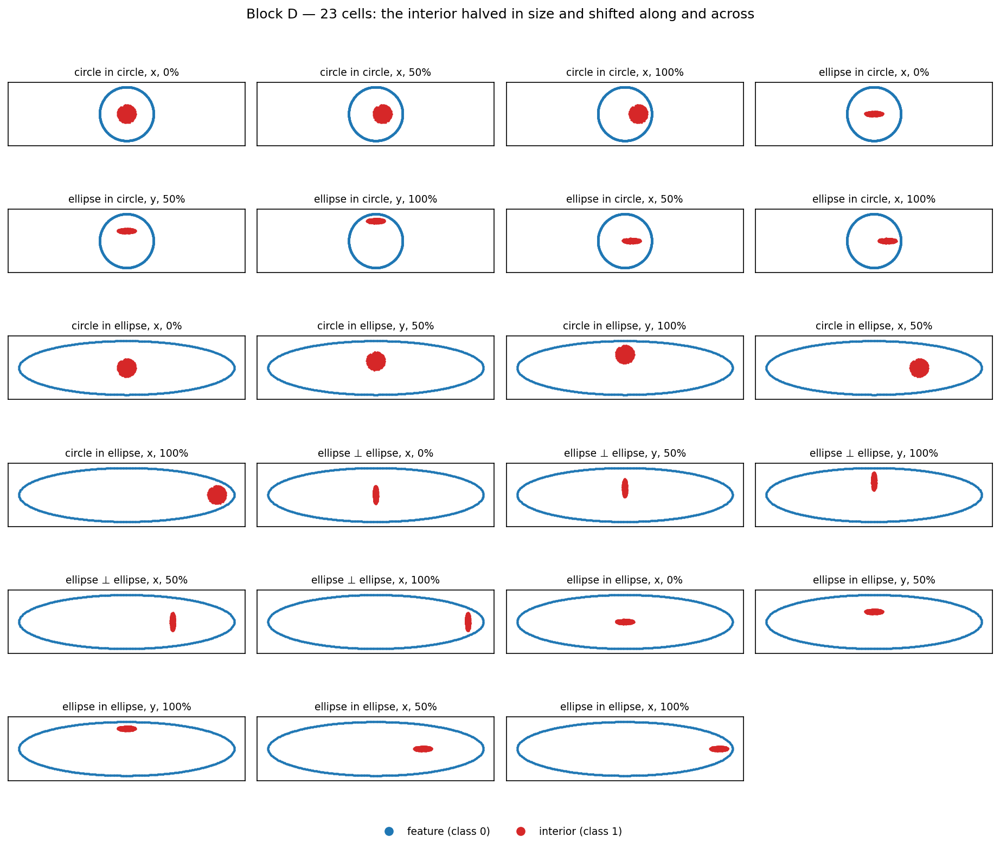

In [5]:
fig = gp.plot_cell_gallery(
    plan["D"],
    [f"{r.label}" for r in cells_meta.loc[plan["D"]].itertuples()],
    ncols=4,
    suptitle="Block D — 23 cells: the interior halved in size and shifted along and across")
plt.show()

**Observations.** The design covers four independent axes, and each cell differs from its neighbour
in exactly one parameter. One can also see what is worth keeping in mind further on:

- in block A, on the diagonal (feature and interior of the same aspect), the two objects are **similar**. There
  the question "whose shape" has no answer by construction, and λ must equal 0.5. This is a control, not
  a result;
- off the diagonal the objects differ in shape, and the further from the diagonal, the more;
- in block B the diagonal stops being degenerate: the same aspect with a turn by 90° gives
  **maximally** different objects;
- in block D the interior is halved — otherwise it would have nowhere to move while staying inside the feature.


## 0.2 Anchor: the detector here is the same

Before reading any drop of the witness fraction as a fact about geometry, one has to make sure that the
detector did not break along the way. The cell "circle in circle" is, up to parameters, the dataset of
experiment 1: a round feature, a round interior, concentric. If the detector is the same, it
must reproduce its numbers.

Below: the cell itself together with its null placements (grey copies of the feature, moved aside —
this is the control), then the distribution of the best-neuron scores of the target against the nulls.

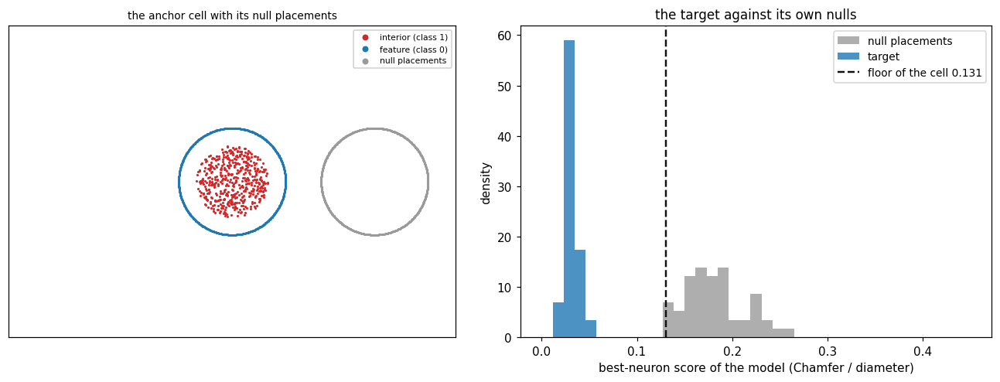

                        experiment 5    experiment 1
median of the best            0.0299          0.0349
witness fraction                1.00            0.98
p_superior                    1.0000          1.0000


In [6]:
ANCHOR = "g5_f010_i010_s100_o+0000+0000_b0500"

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
gp.draw_cell(axes[0], ANCHOR, "the anchor cell with its null placements",
             nulls=True, legend=True, half=gp.cells_extent([ANCHOR], nulls=True))

g = best[best.dataset_type == ANCHOR]
tgt, nul = g[g.feature_role == "target"]["score"], g[g.feature_role != "target"]["score"]
row = cells[cells.dataset_type == ANCHOR].iloc[0]
bins = np.linspace(0, 0.45, 40)
axes[1].hist(nul, bins=bins, color=gp.C_NULL, alpha=.8, density=True, label="null placements")
axes[1].hist(tgt, bins=bins, color=gp.C_FEATURE, alpha=.8, density=True, label="target")
axes[1].axvline(row.floor, color=gp.C_CURVE, ls="--", lw=1.6,
                label=f"floor of the cell {row.floor:.3f}")
axes[1].set_xlabel("best-neuron score of the model (Chamfer / diameter)")
axes[1].set_ylabel("density"); axes[1].legend(fontsize=9)
axes[1].set_title("the target against its own nulls", fontsize=11)
plt.tight_layout(); plt.show()

print(f"{'':22s}{'experiment 5':>14s}{'experiment 1':>16s}")
print(f"{'median of the best':22s}{row.target_median:14.4f}{0.0349:16.4f}")
print(f"{'witness fraction':22s}{row.rate_floor:14.2f}{0.98:16.2f}")
print(f"{'p_superior':22s}{row.p_superior:14.4f}{1.0000:16.4f}")

**Observations.** The median of the best neuron is **0.0299** against 0.0349 in experiment 1, the fraction of models
with a witness is **1.00** against 0.98, `p_superior` = 1.0000 — the distributions of the target and the nulls do not
overlap at all.

**Conclusion.** The detector is in place, and the degenerate point of experiments 1–2 is reproduced inside this
experiment. Everything we will see further on when moving away from it is a fact about geometry, not about
a changed instrument.

## 0.3 The threshold cannot be inherited: each cell has its own floor

The score is normalised by the diameter of the feature. The diameter here runs from 3 (circle) to 12 (ellipse 4:1), and this
means that one and the same value `τ = 0.1` corresponds to a tolerance of 0.3 units for the circle and of 1.2
units for the elongated feature. A threshold that is meaningful in one cell turns out four times softer in another.

The rule frozen in experiment 4 answers this as follows: **the threshold is a percentile of the scores of the
cell's own null placements**, and here the **first** is taken: a false positive costs
more than a miss. A null is a congruent copy of the target itself,
moved to where the network did not solve it; so the floor measures how close to a target of this
shape one can come by chance.

Below is the floor of all 56 cells, sorted, with `τ = 0.1` for comparison. The number of null values
it stands on differs between cells fourfold (50 against 200), and at 50 the first
percentile is almost the minimum of the sample — that is why the fifth is printed next to it.

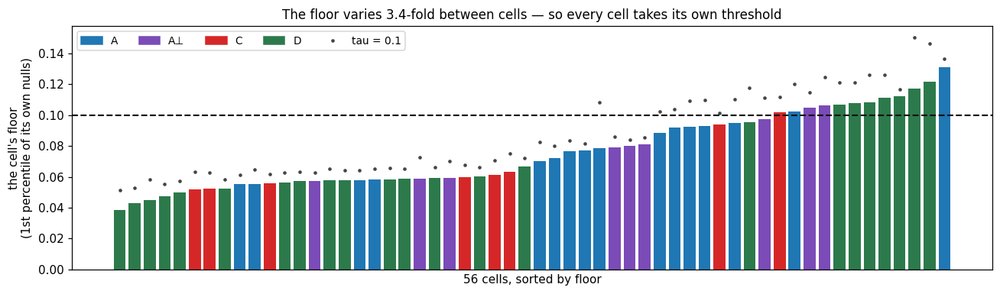

floor:  minimum 0.038   maximum 0.131   ratio 3.4
cells whose own floor is ABOVE tau=0.1: 12 of 56
cells where it is BELOW:                44


In [7]:
fig = gp.plot_floor_bars(cells)
plt.show()

print(f"floor:  minimum {cells.floor.min():.3f}   maximum {cells.floor.max():.3f}   "
      f"ratio {cells.floor.max()/cells.floor.min():.1f}")
print(f"cells whose own floor is ABOVE tau=0.1: {(cells.floor > 0.1).sum()} of {len(cells)}")
print(f"cells where it is BELOW:                {(cells.floor < 0.1).sum()}")

**Observations.** The floor varies from 0.038 to 0.131 — by a factor of 3.4. In 12 cells it is **above** `τ = 0.1`,
that is, there a null passes the threshold of experiments 1–2 and would have been counted as a witness; in 44 it is below.
At the 5th percentile the floor runs 0.052 … 0.150 and is above `τ` already in 21 cells.

**Conclusion.** A single threshold does not exist in this experiment, and this is not a technical detail but
a consequence of the fact that we change the target itself. Further on, the witness fraction is everywhere computed against the
cell's own floor, and `0.01` is read as the chance level — by the definition of the rule,
not as a measured error rate.

---
# 1. Instrument: the harmonic shape descriptor

Three instruments are computed in this experiment. Two of them — the **structural** and the **homological**
criteria — are inherited from experiments 1, 2 and 4 and answer the question "**has the level curve
coincided** with the given target". For topological relevance this is enough, and they are needed here
in exactly two roles: stitching to the previous experiments (the same numbers on the same configuration) and
a check that things work.

But experiment 5 asks something else: **what shape** the level curve turned out to have and **whose** shape it
is. Neither of the two can answer this — they return one number, "far or
close", and the shape is not measured at all. That is why a **third** instrument is introduced here,
the harmonic descriptor, and in this experiment it is the main one: all geometric conclusions rest
on it.

The section is organised as follows: first what the descriptor measures (1.1) and how the distance between shapes is computed
(1.2) — without this the numbers further on are unreadable; then its own accuracy and the scale of the task (1.3),
the derived quantity λ (1.4) and two ways of choosing the levels (1.5). After that, what the instrument sees
on real data: the five rungs of the ladder in full (1.6) and the development of the structure across the layers
of the network (1.7).

## 1.1 What the descriptor measures

A closed curve is described by its **centroid** and its **radial profile** — the distance from the
centroid to the curve as a function of the angle:

$$r(\theta) \;=\; r_0\Bigl(1 + \sum_{k\ge 1} a_k\cos\bigl(k(\theta - \varphi_k)\bigr)\Bigr).$$

The three parts are independent and answer three different questions:

| part | what it is | question |
|---|---|---|
| centroid | where the curve is | **where** |
| `r₀` | mean radius | **how large** |
| `(aₖ, φₖ)` | spectrum of the normalised profile | **what shape** |

`r₀` is taken out of the brackets, so the spectrum **does not depend on size**: circles of radius 1 and 5 have
one and the same zero spectrum. This is what makes the spectrum a measure of shape.

Below is a real level curve of a real neuron, taken apart into these three parts.

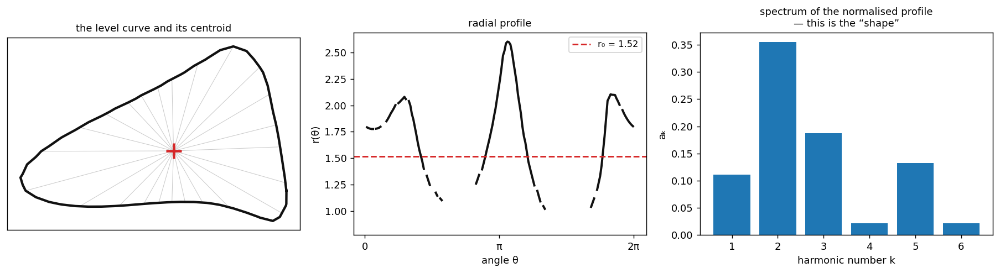

r₀ = 1.519   centroid = (-0.597, -0.312)
aₖ: a1 = 0.111  a2 = 0.355  a3 = 0.187  a4 = 0.021  a5 = 0.132  a6 = 0.022


In [8]:
import warnings
warnings.filterwarnings("ignore")
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

import analysis.geometry_sweep as gs
import visualization.geometry_sweep_plots as gp
from analysis.shape_descriptors import (fourier_descriptor, shape_distance,
                                        radial_profile, SHAPE_ORDER)
from analysis.fields import evaluate_field_on_grid
from analysis.shape_descriptors import level_curves, enclosing_curve, densify

pd.set_option("display.width", 205)
plt.rcParams["figure.dpi"] = 130

ANCHOR = "g5_f010_i010_s100_o+0000+0000_b0500"
ELONG  = "g5_f040_i010_s100_o+0000+0000_b0500"

n = gs.best_neuron_of(best, ELONG, which="median")
L = gs.ladder_curves(ELONG, model_path=n["model_path"],
                     layer_id=n["layer_id"], coord_id=n["coord_id"])
curve = L["curves"][2]
d = fourier_descriptor(curve)
prof = radial_profile(curve)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
c = curve.numpy(); ctr = d["center"].numpy()
axes[0].plot(*np.vstack([c, c[:1]]).T, color=gp.C_CURVE, lw=2.4)
axes[0].plot(*ctr, "+", color=gp.C_INTERIOR, ms=15, mew=2.5)
for a in np.linspace(0, 2*np.pi, 25)[:-1]:
    j = int(np.argmin(np.abs(np.arctan2(*(c - ctr)[:, ::-1].T) % (2*np.pi) - a)))
    axes[0].plot([ctr[0], c[j, 0]], [ctr[1], c[j, 1]], color="#ccc", lw=.6, zorder=0)
axes[0].set_aspect("equal"); axes[0].set_xticks([]); axes[0].set_yticks([])
axes[0].set_title("the level curve and its centroid", fontsize=10)

th, r = prof["theta"].numpy(), prof["r"].numpy()
axes[1].plot(th, r, color=gp.C_CURVE, lw=2.2)
axes[1].axhline(d["r0"], color=gp.C_INTERIOR, ls="--", lw=1.6, label=f"r₀ = {d['r0']:.2f}")
axes[1].set_xlabel("angle θ"); axes[1].set_ylabel("r(θ)")
axes[1].set_xticks([0, np.pi, 2*np.pi], ["0", "π", "2π"])
axes[1].legend(fontsize=9); axes[1].set_title("radial profile", fontsize=10)

ks = list(range(1, SHAPE_ORDER+1))
axes[2].bar(ks, [d["amplitude"][k] for k in ks], color=gp.C_FEATURE)
axes[2].set_xlabel("harmonic number k"); axes[2].set_ylabel("aₖ")
axes[2].set_title("spectrum of the normalised profile\n— this is the “shape”", fontsize=10)
plt.tight_layout(); plt.show()

print(f"r₀ = {d['r0']:.3f}   centroid = ({ctr[0]:+.3f}, {ctr[1]:+.3f})")
print("aₖ: " + "  ".join(f"a{k} = {d['amplitude'][k]:.3f}" for k in ks))

**Observations.** The profile is noticeably non-constant — the shape is not round. But the decomposition shows that
"not round" is arranged in a more complex way than "elongated": besides the second harmonic, **odd** ones are visible —
the first and the third — which an ellipse does not have at all. The first means that the curve is not symmetric
about its centroid, the third that it is slightly triangular.

**Conclusion.** Shape is a vector, not a number. Further on this matters: the distance between shapes is computed
over all harmonics at once.

## 1.2 How the distance between shapes is computed

Each harmonic gives a vector in the plane — amplitude and phase together:

$$u_k \;=\; a_k\bigl(\cos k\varphi_k,\ \sin k\varphi_k\bigr).$$

The distance between shapes is the Euclidean distance between sets of such vectors; by Parseval it
equals the L²-distance between the normalised profiles themselves:

$$d(A, B) \;=\; \sqrt{\tfrac12 \sum_{k=1}^{6} \lVert u_k - v_k\rVert^2}.$$

The phase enters on a par with the amplitude, and this is essential: an ellipse along the x axis and the same ellipse
across it have equal amplitudes and opposite phases, and the distance between them is maximal.
Without the phase, block B would be indistinguishable from block A.

Below, **one specific case** is taken apart — the level curve from 1.1 against its feature — so that one can
see what the number is made of. The shares of the harmonics will be different for another pair of curves; the point of the
example is not the specific percentages but that the contribution does not come from one harmonic.


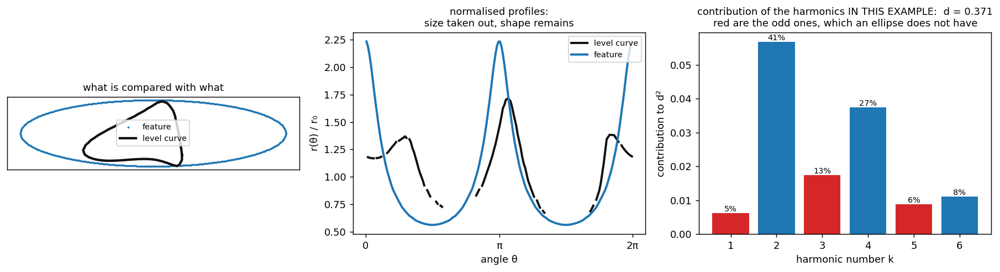

  k   term of d²   share    aₖ curve  aₖ feat.
  1      0.00621    4.5%       0.111     0.000
  2      0.05682   41.2%       0.355     0.633
  3      0.01751   12.7%       0.187     0.000
  4      0.03746   27.2%       0.021     0.290
  5      0.00874    6.3%       0.132     0.000
  6      0.01112    8.1%       0.022     0.145

d = sqrt(0.13787) = 0.3713
if only a₂ were counted: 0.2782


In [9]:
dcur, dfea = fourier_descriptor(curve), fourier_descriptor(L["feature"])
terms = gs.harmonic_terms(dcur, dfea)
total = sum(terms)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
f = L["feature"].numpy()
axes[0].scatter(f[:, 0], f[:, 1], s=1.1, color=gp.C_FEATURE, label="feature")
axes[0].plot(*np.vstack([c, c[:1]]).T, color=gp.C_CURVE, lw=2.4, label="level curve")
axes[0].set_aspect("equal"); axes[0].set_xticks([]); axes[0].set_yticks([])
axes[0].legend(fontsize=8); axes[0].set_title("what is compared with what", fontsize=10)

pf = radial_profile(L["feature"])
axes[1].plot(prof["theta"], prof["r"]/dcur["r0"], color=gp.C_CURVE, lw=2.2, label="level curve")
axes[1].plot(pf["theta"], pf["r"]/dfea["r0"], color=gp.C_FEATURE, lw=2.2, label="feature")
axes[1].set_xticks([0, np.pi, 2*np.pi], ["0", "π", "2π"])
axes[1].set_xlabel("angle θ"); axes[1].set_ylabel("r(θ) / r₀"); axes[1].legend(fontsize=8)
axes[1].set_title("normalised profiles:\nsize taken out, shape remains", fontsize=10)

axes[2].bar(ks, terms, color=[gp.C_FEATURE if k % 2 == 0 else gp.C_INTERIOR for k in ks])
for k, tt in zip(ks, terms):
    axes[2].text(k, tt, f"{100*tt/total:.0f}%", ha="center", va="bottom", fontsize=8)
axes[2].set_xlabel("harmonic number k"); axes[2].set_ylabel("contribution to d²")
axes[2].set_title(f"contribution of the harmonics IN THIS EXAMPLE:  d = {math.sqrt(total):.3f}\n"
                  "red are the odd ones, which an ellipse does not have", fontsize=10)
plt.tight_layout(); plt.show()

print(f"{'k':>3}{'term of d²':>13}{'share':>8}{'aₖ curve':>12}{'aₖ feat.':>10}")
for k, tt in zip(ks, terms):
    print(f"{k:3d}{tt:13.5f}{100*tt/total:7.1f}%{dcur['amplitude'][k]:12.3f}{dfea['amplitude'][k]:10.3f}")
print(f"\nd = sqrt({total:.5f}) = {math.sqrt(total):.4f}")
print(f"if only a₂ were counted: {abs(dcur['amplitude'][2]-dfea['amplitude'][2]):.4f}")

**Observations.** In this example the second harmonic gives 42% of the squared distance, the fourth 29%
(the 4:1 ellipse has `a₄ = 0.29`, it is strongly non-sinusoidal), the odd ones 22%: an ellipse has none of them at all,
while the real level curve does. Counting "by the difference of the second harmonics" would give 0.2755 instead of 0.3724.

**Conclusion.** The shape distance is not "a difference of elongations": it is made up of six terms, and
which of them is the main one depends on the pair of curves. That is why everywhere further on the distance is given
in full; `a₂` is used separately and only where it is converted into an aspect for clarity.

## 1.3 The instrument's own accuracy and the scale of the task

These are **two different things**, and they are easy to confuse.

**The accuracy of the instrument** is how faithfully it describes the curve. The level curve is extracted from a finite
grid, so its spectrum carries a discretisation error. It is measured like this:

1. take a field whose level curves are known **exactly**: `f(x,y) = √((x/a)² + (y/b)²)`, for which
   the level `c` is exactly the ellipse with semi-axes `ca, cb`;
2. compute this field on a grid of the given step `h`;
3. extract the level curve **with the same code** as in the experiment: marching squares → choice of the
   enclosing curve → densification with step `h/2`;
4. compute its descriptor and compare it with the analytic descriptor of the exact ellipse;
5. the difference is the error of the instrument. Varying `h`, we obtain it as a function of `r₀/h` — the number of grid
   steps per mean radius of the curve.

**The scale of the task** is how large the differences are that the experiment asks about at all. It is set by the
design: the grid of aspects 1 / 1.5 / 2.5 / 4, and its smallest step — circle against 1.5:1 — equals
**0.144**. This is **not** the resolution of the instrument and says nothing about how small the changes are that it
can register; it is the step that we chose.

Only their **ratio** has meaning: whether the instrument is fit for the scale the design asks about.

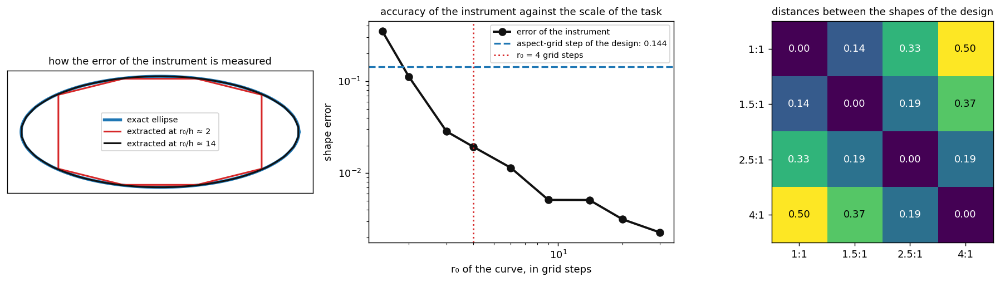

error of the instrument:  r₀/h=1.5: 0.3498   r₀/h=2: 0.1114   r₀/h=3: 0.0284   r₀/h=4: 0.0194   r₀/h=6: 0.0114   r₀/h=9: 0.0051   r₀/h=14: 0.0051   r₀/h=20: 0.0032   r₀/h=30: 0.0023

aspect-grid step of the design: 0.144 (circle against 1.5:1); extreme shapes — 0.503


In [10]:
aspects = (1.0, 1.5, 2.5, 4.0)
th_ = torch.linspace(0, 2*math.pi, 2001)[:-1]
ref = {a: fourier_descriptor(torch.stack([a*torch.cos(th_), torch.sin(th_)], 1)) for a in aspects}

ratios = [1.5, 2, 3, 4, 6, 9, 14, 20, 30]
errs, demo = [], {}
a_e, b_e = 1.0, 1.0/2.5
exact = torch.stack([a_e*torch.cos(th_), b_e*torch.sin(th_)], 1)
for ratio in ratios:
    res = int(round(8*ratio))
    fld = evaluate_field_on_grid(lambda p: torch.sqrt((p[:,0]/a_e)**2 + (p[:,1]/b_e)**2),
                                 [(-4, 4)]*2, res)
    cu = enclosing_curve(level_curves(fld, 1.0), torch.zeros(2))
    if cu is None:
        errs.append(np.nan); continue
    cu = densify(cu, .5*fld.grid_step)
    errs.append(shape_distance(fourier_descriptor(cu), fourier_descriptor(exact)))
    if ratio in (2, 14):
        demo[ratio] = cu.numpy()

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.0))
axes[0].plot(*exact.numpy().T, color=gp.C_FEATURE, lw=3, label="exact ellipse")
for ratio, col in zip((2, 14), [gp.C_INTERIOR, gp.C_CURVE]):
    dd = demo[ratio]
    axes[0].plot(*np.vstack([dd, dd[:1]]).T, lw=1.7, color=col,
                 label=f"extracted at r₀/h ≈ {ratio}")
axes[0].set_aspect("equal"); axes[0].set_xticks([]); axes[0].set_yticks([])
axes[0].legend(fontsize=8); axes[0].set_title("how the error of the instrument is measured", fontsize=10)

axes[1].loglog(ratios, errs, "o-", color=gp.C_CURVE, lw=2.2, ms=7, label="error of the instrument")
axes[1].axhline(0.144, color=gp.C_FEATURE, ls="--", lw=1.8,
                label="aspect-grid step of the design: 0.144")
axes[1].axvline(4, color=gp.C_INTERIOR, ls=":", lw=1.6, label="r₀ = 4 grid steps")
axes[1].set_xlabel("r₀ of the curve, in grid steps"); axes[1].set_ylabel("shape error")
axes[1].legend(fontsize=8); axes[1].set_title("accuracy of the instrument against the scale of the task", fontsize=10)

M = np.array([[shape_distance(ref[x], ref[y]) for y in aspects] for x in aspects])
im = axes[2].imshow(M, cmap="viridis")
axes[2].set_xticks(range(4), [f"{a:g}:1" for a in aspects])
axes[2].set_yticks(range(4), [f"{a:g}:1" for a in aspects])
for i in range(4):
    for j in range(4):
        axes[2].text(j, i, f"{M[i,j]:.2f}", ha="center", va="center", fontsize=10,
                     color="white" if M[i,j] < .35 else "black")
axes[2].set_title("distances between the shapes of the design", fontsize=10)
plt.tight_layout(); plt.show()

print("error of the instrument:  " + "   ".join(f"r₀/h={r}: {e:.4f}" for r, e in zip(ratios, errs) if e == e))
print(f"\naspect-grid step of the design: 0.144 (circle against 1.5:1); extreme shapes — 0.503")

**Observations.** The error of the instrument falls as `1/(r₀/h)`: 0.05 at one and a half grid steps per radius,
**0.010** at four, 0.002 at twenty. The step of the design's aspect grid is 0.144.

**Conclusion.** At `r₀ ≥ 4` grid steps the instrument errs **fourteen times** less than the
smallest difference the design asks about. The condition `r₀ ≥ 4h` holds in the main sections
everywhere except the lower rung of the ladder in some of the cells of block D, and there it is stated separately.

## 1.4 λ: whose shape the curve carries

A distance has no address: 0.37 — far from what? That is why the main quantity of the experiment
is relative:

$$\lambda \;=\; \frac{d_{\text{feat}}}{d_{\text{feat}} + d_{\text{int}}},\qquad
\lambda = 0 \Rightarrow \text{shape of the feature},\qquad
\lambda = 1 \Rightarrow \text{shape of the interior}.$$

λ has one degeneracy: **if the two objects have one shape, the question has no answer** —
the numerator and the denominator differ only by noise, and λ comes out 0.5 for any curve. The threshold here
is set by **the accuracy of the instrument**: as long as `objects_shape` is comparable to 0.01, λ is a ratio of two noises.

Separately from this, the design contains cells where the objects are similar **by construction** — the diagonal
of block A. There `objects_shape` equals zero not approximately but identically, and λ ≡ 0.5 not because
the instrument failed, but because the question is not posed. Such cells are always marked further on and
do not enter the averages.

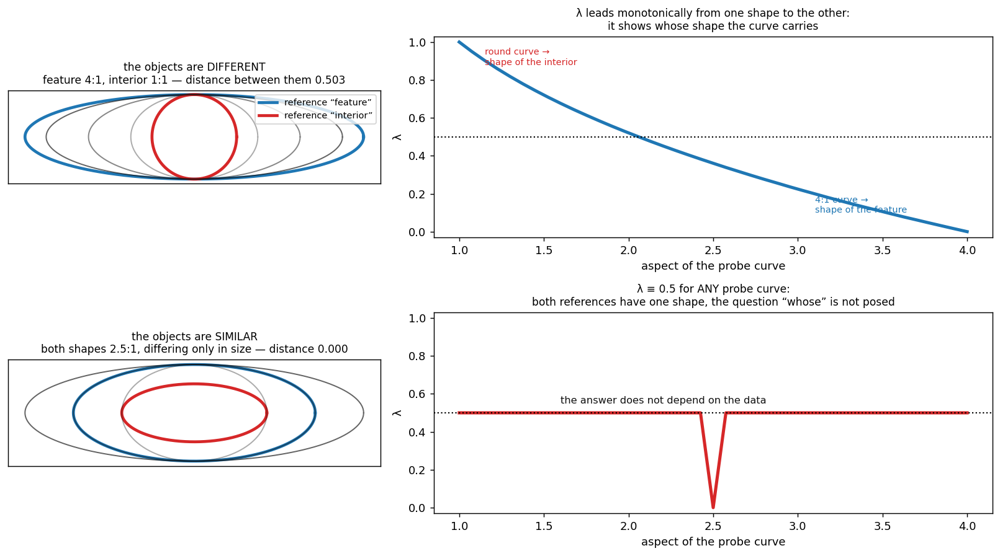

cells where the objects are similar by construction (objects_shape < 0.01): 14 of 56
  their median λ: 0.500  (must be 0.5)
  median λ in the others: 0.569


In [11]:
fea, inte = ref[4.0], ref[1.0]
asps = np.linspace(1.0, 4.0, 41)
# degenerate case: two SIMILAR objects — 2.5:1 ellipses of different size
f2 = fourier_descriptor(torch.stack([2.5*torch.cos(th_), torch.sin(th_)], 1))
i2 = fourier_descriptor(torch.stack([2.5*.6*torch.cos(th_), .6*torch.sin(th_)], 1))
lam_ok, lam_deg = [], []
for asp in asps:
    cu = fourier_descriptor(torch.stack([asp*torch.cos(th_), torch.sin(th_)], 1))
    d1, d2 = shape_distance(cu, fea), shape_distance(cu, inte)
    lam_ok.append(d1/(d1+d2))
    e1, e2 = shape_distance(cu, f2), shape_distance(cu, i2)
    lam_deg.append(e1/(e1+e2) if (e1+e2) > 1e-9 else np.nan)

fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.0),
                         gridspec_kw={"width_ratios": [1, 1.5]})
for row, (fo, io, lam, ttl, sub) in enumerate([
        ((4.0, 1.0), (1.0, 1.0), lam_ok, "the objects are DIFFERENT",
         "feature 4:1, interior 1:1 — distance between them 0.503"),
        ((2.5, 1.0), (2.5*.6, .6), lam_deg, "the objects are SIMILAR",
         "both shapes 2.5:1, differing only in size — distance 0.000")]):
    ax = axes[row][0]
    ax.plot(fo[0]*np.cos(th_.numpy()), fo[1]*np.sin(th_.numpy()),
            color=gp.C_FEATURE, lw=2.6, label="reference “feature”")
    ax.plot(io[0]*np.cos(th_.numpy()), io[1]*np.sin(th_.numpy()),
            color=gp.C_INTERIOR, lw=2.6, label="reference “interior”")
    for a, al in zip((1.5, 2.5, 3.5), (.35, .5, .65)):
        ax.plot(a*np.cos(th_.numpy()), np.sin(th_.numpy()), color=gp.C_CURVE,
                lw=1.1, alpha=al)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{ttl}\n{sub}", fontsize=9.5)
    if row == 0:
        ax.legend(fontsize=8, loc="upper right")
        ax.plot([], [], color=gp.C_CURVE, lw=1.1, label="probe curves")

    ax = axes[row][1]
    ax.plot(asps, lam, lw=2.8, color=gp.C_FEATURE if row == 0 else gp.C_INTERIOR)
    ax.axhline(.5, color="k", ls=":", lw=1.2)
    ax.set_ylim(-.03, 1.03); ax.set_ylabel("λ"); ax.set_xlabel("aspect of the probe curve")
    if row == 0:
        ax.set_title("λ leads monotonically from one shape to the other:\n"
                     "it shows whose shape the curve carries", fontsize=9.5)
        ax.annotate("round curve →\nshape of the interior", (1.15, .88), fontsize=8,
                    color=gp.C_INTERIOR)
        ax.annotate("4:1 curve →\nshape of the feature", (3.1, .10), fontsize=8, color=gp.C_FEATURE)
    else:
        ax.set_title("λ ≡ 0.5 for ANY probe curve:\n"
                     "both references have one shape, the question “whose” is not posed", fontsize=9.5)
        ax.annotate("the answer does not depend on the data", (1.6, .55), fontsize=9, color=gp.C_CURVE)
plt.tight_layout(); plt.show()

lv = gs.ladder_long(df, "value")
sh = gs.shape_by_cell(lv); midd = sh[sh.rung == 2]
deg = midd[midd.objects_shape < 0.01]
print(f"cells where the objects are similar by construction (objects_shape < 0.01): "
      f"{len(deg)} of {midd.dataset_type.nunique()}")
print(f"  their median λ: {deg.lam.median():.3f}  (must be 0.5)")
print(f"  median λ in the others: {midd[midd.objects_shape >= 0.01].lam.median():.3f}")

**Observations.** When the objects differ, λ leads monotonically from 1 to 0 as the probe
curve passes from the shape of the interior to the shape of the feature. When the objects are similar, λ equals 0.5 for any
curve. In the computed data there are exactly as many degenerate cells as the geometry predicts, and
their median λ is indeed 0.500.

**Conclusion.** λ is read only together with the `objects_shape` of its cell, and the degenerate cells —
the diagonal of block A — serve as a check that things work, not as a result.

## 1.5 Two ways of choosing the levels

A neuron has not one level curve but a family — one for each value of `c`. The level cannot be chosen
by the criterion: if one takes the one closest to the feature, the answer "the curve resembles the feature"
comes out by construction. Rules symmetric between the two objects are needed, and there are two of them — on the two
sides of one and the same map `level ↦ curve`.

**By the field value (codomain).** Five values, spread evenly between the mean value of the
field **on the boundary of the interior** and its mean value **on the feature**. Both anchors are means of the field over the
points of an object, so the rule knows nothing about shape or size: it knows only that there
are two objects.

**By radius (domain).** Five target radii, spread evenly between the `r₀` of the interior and the
`r₀` of the feature. The word "inversion" hides an algorithm here, so it is written out (this is `spatial_ladder`,
and the server run computed it the same way):

1. **probing** — 13 probe levels, evenly on the same interval of values as for the first
   ladder. These curves themselves go nowhere; they are needed only to learn the relation between level and radius
   for the given neuron;
2. on each probe the closed contour enclosing the **centroid of the interior** is taken, and its `r₀`
   is computed around **its own** centroid — otherwise the offset would mix into the size;
3. the resulting table "level → `r₀`" is checked for **monotonicity** (the flag is returned together
   with the ladder; it is monotone for 52% of neurons);
4. for each target radius the level is found by linear interpolation in this table.

The target radii **are not adjusted** to what the neuron reaches: an unreachable radius is returned
as a gap. Adjusting would keep all five rungs filled at the cost of the common frame for the sake of which
the construction is made.

Both rules give a **common frame**, just in different spaces: for the first, "rung 3" means
one and the same fraction of the travelled range of **field values** for any neuron, for the second, one and the
same place **in space**. Both allow neurons to be compared with each other; the only question is
along which coordinate to align them.

The motivation in favour of the codomain — and it is exactly a motivation, not a rigorous argument. Equal steps in value
lay the level curves **more densely where the field is steeper**: where `f` changes fast, neighbouring levels are close
in space too. Steepness is the place of the "fold" of the field, the zone of transition from one class to the other,
that is, the region the neuron responds to. The value ladder itself concentrates the sample
there; the radius ladder spreads it evenly over space regardless of where
something happens in the field.

The price of the codomain is unevenness in space; the price of the domain is that the map `c ↦ r₀`
must be monotone to be inverted, and this holds only for 52% of neurons.

**Further on, in sections 2–D, the value ladder is analysed**, and the radius ladder serves as a
robustness check where it is filled. The reason is not principled but practical:
by value a rung always exists, and there is no point in losing half of the neurons to the requirement of monotonicity.

Below, both ladders are built **for one and the same neuron**, so that the difference is seen and not just
stated. Under the curves is **the field of the neuron itself**: without it a curve looks like a figure from nowhere, and with
it one can see whether it lies on the fold of the field or in the middle of a plateau. The background colour is the rank of the value, not the
value itself: `tanh` saturates, and with a uniform scale almost the whole frame is painted one tone,
while all the geometry sits in a narrow transition zone. The levels of the background are therefore placed at quantiles of the
values in the window — where the colour changes fast, the field is steep.

The third panel is that very map `c ↦ r₀`, taken over 61 probe levels (the ladder itself has
13 probes; here there are more, so that the curve is smooth): it shows at once both how the two
ladders work and why the second one sometimes has no rung.

**On the colour scale — and why the background is almost single-toned in places.** For this neuron, in the window shown,
**84% of grid nodes have |f| > 0.9**, and 53% have |f| > 0.99: `tanh` is saturated, and almost the whole frame
is taken up by two plateaus, between which lies a narrow fold. Only **16.5%** of the nodes fall inside the range of the
ladder. So the single tone on wide cells is a property of the neuron itself, not of a common
palette: the palette is chosen **for each neuron separately**, from the values inside the window
shown.

The colour levels are placed **at quantiles** of these values. This makes visible both the fold and the weak
relief on the plateaus — the thin lines at the edges of the frame are real level curves of the same field, it is just that
there it is almost constant. The price is that colour reads as the rank of the value, not as the value itself; the
values themselves are carried by the five highlighted curves, which are labelled with the levels of the ladder.

The third panel is that very map `c ↦ r₀`, taken over 61 probe levels (the ladder itself has
13 probes; here there are more, so that the curve is smooth): it shows at once both how the two
ladders work and why the second one sometimes has no rung.

**On the colour scale — it is not chosen by eye.** For this neuron, in the window shown, **84% of grid
nodes have |f| > 0.9**, and 53% have |f| > 0.99: `tanh` is saturated, and almost the whole frame is taken up by two plateaus,
between which lies a narrow fold. Only **16.5%** of the nodes fall inside the range of the ladder.
That is why the colour is tied to **the range of the ladder itself**: the whole palette goes to the fold, and both plateaus
are painted in the extreme colours. A rank scale (by quantiles of the values) does exactly the opposite — it gives
most of the colours to the plateaus, where nothing happens, and draws a web of false lines there. So
the single tone on wide cells is a property of the neuron, not of the palette: the palette is chosen **for
each neuron separately**.


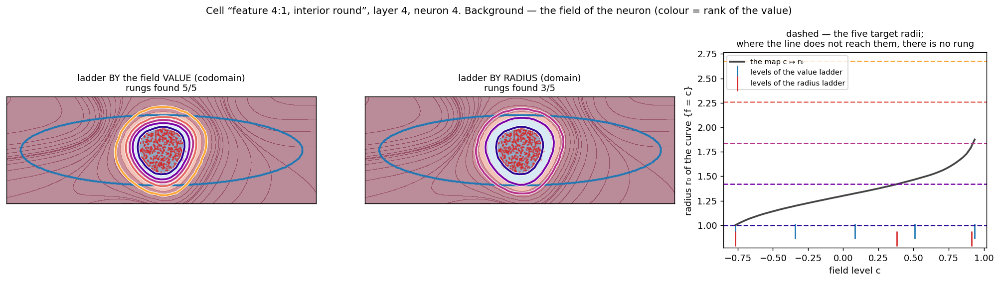

ladder BY the field VALUE (codomain)       radii [1.0, 1.2, 1.33, 1.47, 1.88]
ladder BY RADIUS (domain)                  radii [1.0, 1.42, 1.81, None, None]
target radii of the radius ladder          [1.0, 1.42, 1.84, 2.26, 2.68]
grid nodes in the window                   1180; |f| > 0.9 at 87%, inside the ladder range 13%
reachable radii of this neuron             [1.00 … 1.88]  (over 61 probe levels)


In [12]:
from analysis.shape_descriptors import spatial_ladder, level_ladder

# The neuron was found by search: its two ladders diverge the most
# (radii 0.78…1.88 against 1.00…2.68), so the difference is seen, not implied.
demo = {"cell": "g5_f040_i010_s100_o+0000+0000_b0500", "layer": 4, "coord": 4,
        "model_index": 1}

rec = PLAN[demo["cell"]]
X, y, A_pts = gs.dataset_points(demo["cell"])[:3]
centre = torch.tensor(rec["interior"]["offset"], dtype=torch.float32)
bnd = gs._interior_boundary(rec["interior"])          # anchor of the ladder — the boundary, not the cloud
fld, _, _ = gs.neuron_field(demo["cell"], model_index=demo["model_index"],
                            layer_id=demo["layer"], coord_id=demo["coord"])
step = .5*float(fld.grid_step)

r0i, r0f = fourier_descriptor(bnd)["r0"], fourier_descriptor(A_pts)["r0"]
lev_v = level_ladder(fld, A_pts, bnd, n_steps=5)
sp = spatial_ladder(fld, centre, r0i, r0f, (float(lev_v[0]), float(lev_v[-1])),
                    n_steps=5, curve_step=step)
targets = np.linspace(r0i, r0f, 5)                     # where the radius ladder aims

def curves_at(levels):
    out = []
    for c in levels:
        if c != c:
            out.append(None); continue
        cu = enclosing_curve(level_curves(fld, float(c)), centre)
        out.append(None if cu is None else densify(cu, step))
    return out

hx, hy = gp.cells_extent([demo["cell"]])
_all = [c for c in curves_at(lev_v) + curves_at(sp["levels"]) if c is not None]
hy = max(hy, max(float(c[:, 1].abs().max()) for c in _all)) * 1.18   # curves entirely in the frame
vrange = (float(lev_v[0]), float(lev_v[-1]))                         # colour scale = the ladder
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4),
                         gridspec_kw={"width_ratios": [1, 1, .85]})
radii = {}
for ax, (levels, ttl) in zip(axes[:2], [(lev_v, "ladder BY the field VALUE (codomain)"),
                                        (sp["levels"], "ladder BY RADIUS (domain)")]):
    gp.field_background(ax, fld, window=(hx, hy), alpha=.45, levels=21)
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=1.3, c=gp.C_INTERIOR, alpha=.65, zorder=1)
    ax.scatter(A_pts[:, 0], A_pts[:, 1], s=1.5, c=gp.C_FEATURE, zorder=2)
    rr = []
    for j, cu in enumerate(curves_at(levels)):
        if cu is None:
            rr.append(np.nan); continue
        gp.draw_curve(ax, cu.numpy(), ramp[j], lw=2.1, zorder=3+j)
        rr.append(fourier_descriptor(cu)["r0"])
    radii[ttl] = rr
    got = sum(r == r for r in rr)
    ax.set_xlim(-hx, hx); ax.set_ylim(-hy, hy)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{ttl}\nrungs found {got}/5", fontsize=10)

probe = torch.linspace(float(lev_v[0]), float(lev_v[-1]), 61)
prof = []
for c in probe:
    cu = enclosing_curve(level_curves(fld, float(c)), centre)
    prof.append((float(c), np.nan if cu is None
                 else fourier_descriptor(densify(cu, step))["r0"]))
axes[2].plot([p[0] for p in prof], [p[1] for p in prof], lw=2.0, c="#444",
             label="the map c ↦ r₀")
for j, tr in enumerate(targets):
    axes[2].axhline(tr, color=ramp[j], ls="--", lw=1.4)
axes[2].scatter([float(v) for v in lev_v], [r0i-.06]*5, marker="|", s=260,
                c=gp.C_FEATURE, label="levels of the value ladder")
axes[2].scatter([float(v) for v in sp["levels"] if v == v],
                [r0i-.14]*int(sum(v == v for v in sp["levels"])), marker="|", s=260,
                c=gp.C_INTERIOR, label="levels of the radius ladder")
axes[2].set_xlabel("field level c"); axes[2].set_ylabel("radius r₀ of the curve {f = c}")
axes[2].legend(fontsize=8, loc="upper left")
axes[2].set_title("dashed — the five target radii;\n"
                  "where the line does not reach them, there is no rung", fontsize=10)
fig.suptitle(f"Cell “feature 4:1, interior round”, layer {demo['layer']}, "
             f"neuron {demo['coord']}. Background — the field of the neuron (colour = rank of the value)",
             fontsize=11)
plt.tight_layout(); plt.show()

for ttl, rr in radii.items():
    print(f"{ttl:42s} radii {[round(x,2) if x==x else None for x in rr]}")
print(f"{'target radii of the radius ladder':42s} "
      f"{[round(float(t),2) for t in targets]}")
ins = (np.abs(fld.points_nd.numpy()[..., 0]) <= hx) & (np.abs(fld.points_nd.numpy()[..., 1]) <= hy)
vw = fld.values_nd.numpy()[ins]
print(f"{'grid nodes in the window':42s} {vw.size}; |f| > 0.9 at {(np.abs(vw) > .9).mean():.0%}, "
      f"inside the ladder range {((vw >= vrange[0]) & (vw <= vrange[1])).mean():.0%}")
reach = [p[1] for p in prof if p[1] == p[1]]
print(f"{'reachable radii of this neuron':42s} "
      f"[{min(reach):.2f} … {max(reach):.2f}]  (over 61 probe levels)")


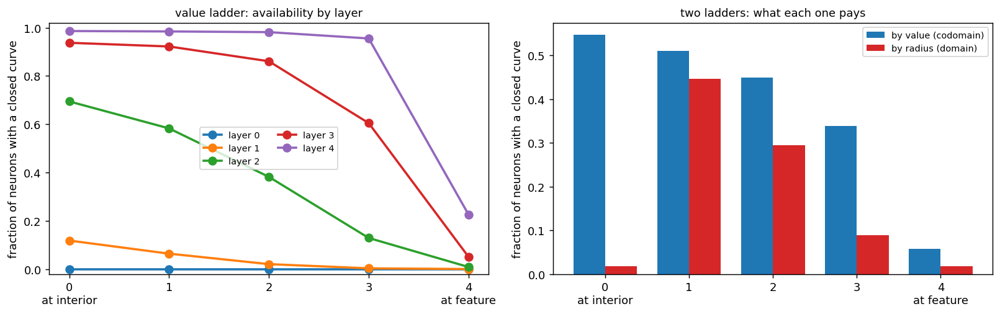

availability of the rungs (all layers):
      by value  by radius
rung                     
0        0.547      0.019
1        0.511      0.447
2        0.449      0.295
3        0.339      0.088
4        0.057      0.017



the map level -> radius is monotone for 52% of neurons


In [13]:
lr = gs.ladder_long(df, "radial")
av_v = lv.assign(present=lambda d: d.dfeat.notna()).pivot_table(
    index="layer_id", columns="rung", values="present", aggfunc="mean")
per_rung = pd.DataFrame({
    "by value": lv.assign(e=lambda d: d.dfeat.notna()).groupby("rung").e.mean(),
    "by radius":  lr.assign(e=lambda d: d.dfeat.notna()).groupby("rung").e.mean()})

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0))
for layer in sorted(av_v.index):
    axes[0].plot(av_v.columns, av_v.loc[layer], "o-", lw=2, ms=7, label=f"layer {layer}")
axes[0].set_xticks(range(5), ["0\nat interior", "1", "2", "3", "4\nat feature"])
axes[0].set_ylabel("fraction of neurons with a closed curve"); axes[0].set_ylim(-.02, 1.02)
axes[0].legend(fontsize=8, ncol=2)
axes[0].set_title("value ladder: availability by layer", fontsize=10)

w = .38; x = np.arange(5)
axes[1].bar(x - w/2, per_rung["by value"], w, color=gp.C_FEATURE, label="by value (codomain)")
axes[1].bar(x + w/2, per_rung["by radius"], w, color=gp.C_INTERIOR, label="by radius (domain)")
axes[1].set_xticks(x, ["0\nat interior", "1", "2", "3", "4\nat feature"])
axes[1].set_ylabel("fraction of neurons with a closed curve"); axes[1].legend(fontsize=8)
axes[1].set_title("two ladders: what each one pays", fontsize=10)
plt.tight_layout(); plt.show()

print("availability of the rungs (all layers):")
print(per_rung.round(3).to_string())
t = df[df.feature_role == "target"]
print(f"\nthe map level -> radius is monotone for {t.harmonic_monotone.mean():.0%} of neurons")

**Observations.**

- **The two ladders put the curves in different places.** For the neuron shown, the value ladder gives
  radii 1.00 · 1.20 · 1.33 · 1.47 · 1.88, while the radius ladder aims at 1.00 · 1.42 · 1.84 ·
  2.26 · 2.68 and finds only the first three.
- **The right panel says why.** The map `c ↦ r₀` of this neuron runs up against 1.88: its family simply has no curve
  of radius 2.26. The instrument returns a gap rather than substituting the nearest
  existing one — and this is the right behaviour, otherwise "rung 4" would mean different things
  for different neurons.
- **Gaps in the two ladders mean different things.** In the radius ladder a gap means "no such radius
  exists". In the value ladder the level always exists, and a gap means that the
  contour on it is **not closed around the interior**: it either falls apart into pieces or runs into
  the edge of the computation window and breaks off. A check on this same neuron: on rung 4 there are two contours,
  one is closed, one touches the edge of the window.
- **Availability of the rungs (block A, layers > 0).** By value: 0.68 · 0.64 · 0.59 · 0.48 · **0.10**.
  By radius: 0.04 · 0.64 · 0.50 · 0.19 · 0.05 — its inner rung is almost empty for the same
  reason for which the outer one is empty for the neuron shown: the radius `r₀` of the interior lies below
  what the family reaches.
- **The outer rung melts away together with the elongation of the feature**: 0.164 · 0.130 · 0.052 · **0.042** along the series
  1 : 1.5 : 2.5 : 4. The inner one meanwhile does not melt at all (0.64 · 0.68 · 0.71 · 0.69). So
  the conclusions about elongated cells rest on rungs 0–3, and this must be kept in mind: where the
  feature is elongated, the outermost curve most often simply does not exist.
- **And this does not hide the effect.** A direct check on the 1558 neurons of block A that have **both**
  extreme rungs: the shape distance to the feature on the inner rung is 0.099, on the outer 0.129, and only
  for 21% is the outer rung closer to the feature. That is, the missing outer rungs do not
  hide a regime "further out the curve becomes the feature"; where both rungs exist, the inner one is closer to
  the feature.

**Conclusion.** One has to look at **all rungs at once** — this is the very content of the quantity: how the shape
behaves along the family. A single rung is chosen only where exactly one number per
cell is needed; then the **middle** rung of the value ladder is taken — it is symmetric between the two
objects and available for 89–99% of the neurons of the deep layers.


## 1.6 What the instrument sees: five rungs on real data

Everything so far is the mechanism. Now what it was built for: what the ladder of levels looks like for a
typical neuron in four different cells. The colour goes from rung 0 (at the interior) to rung 4
(at the feature). Each panel has **its own** scale: what should be compared is the structure within a panel, not the sizes
between panels.

There is one thing to look at: **whether the shape of the curves changes along the ladder**. If the field had a level
carrying the shape of the feature, the outer rungs would approach the blue curve not only in size but also in
outline.

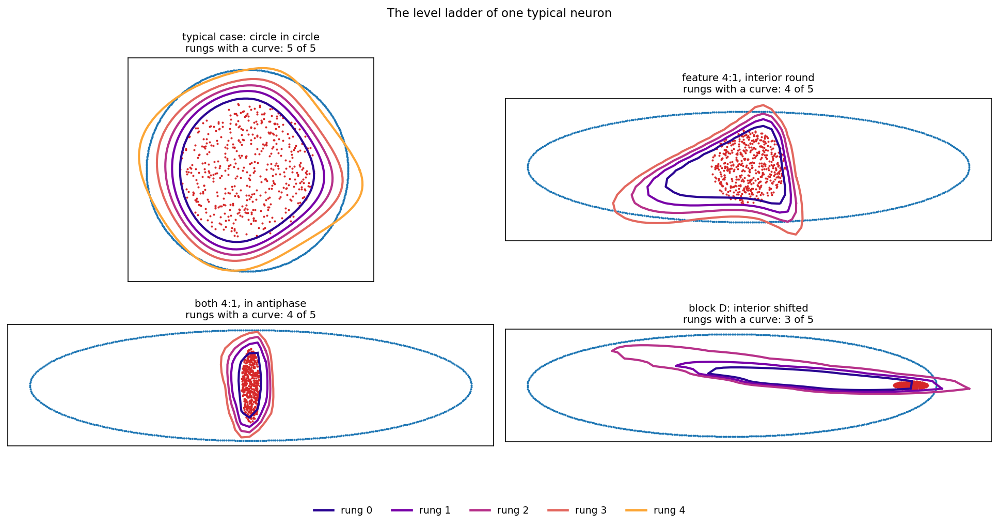

In [14]:
CASES = [(ANCHOR, "typical case: circle in circle"),
         (ELONG, "feature 4:1, interior round"),
         ("g5_f040_i040T_s100_o+0000+0000_b0500", "both 4:1, in antiphase"),
         ("g5_f040_i040_s050_o+0525+0000_b0500", "block D: interior shifted")]
ramp = plt.cm.plasma(np.linspace(.05, .8, 5))

fig, axes = plt.subplots(2, 2, figsize=(13, 6.6), dpi=150)
for ax, (name, title) in zip(axes.flat, CASES):
    nn = gs.best_neuron_of(best, name, which="median")
    LL = gs.ladder_curves(name, model_path=nn["model_path"],
                          layer_id=nn["layer_id"], coord_id=nn["coord_id"])
    X, y, A, _ = gs.dataset_points(name)
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=.9, c=gp.C_INTERIOR, zorder=1)
    ax.scatter(A[:, 0], A[:, 1], s=.9, c=gp.C_FEATURE, zorder=2)
    got = 0
    for j, cu in enumerate(LL["curves"]):
        if cu is None:
            continue
        got += 1
        cc = cu.numpy()
        ax.plot(*np.vstack([cc, cc[:1]]).T, color=ramp[j], lw=2.0, zorder=3)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{title}\nrungs with a curve: {got} of 5", fontsize=9.5)
fig.suptitle("The level ladder of one typical neuron", fontsize=11)
plt.tight_layout()
fig.legend(handles=[plt.Line2D([], [], color=ramp[j], lw=2.2, label=f"rung {j}")
                    for j in range(5)],
           loc="lower center", ncol=5, fontsize=9, frameon=False, bbox_to_anchor=(.5, -.03))
plt.show()

**Observations.**

- **Circle in circle.** Five round nested curves; the outer one almost coincides with the feature. This is the
  picture the criterion was built for, and experiments 1 and 2 saw it.
- **Feature 4:1, interior round.** The curves are compact and noticeably non-round — triangular, if anything — but none
  is elliptical along the feature. The size grows,
  the outline does not change, and no rung approaches the shape of the feature, although the outer one is already
  comparable with it in size.
- **Antiphase.** The curves are elongated **across** the feature, along the interior.
- **Block D.** The curves are elongated along the long axis; there a round curve would not have separated the classes.

**Conclusion.** These are four examples, not a measurement: they show **what exactly** the instrument describes and
what to look at, and they pose the question that is taken apart in blocks A, B, C and D — whether the shape changes
along the ladder and what sets it. No general statement follows from here yet.


## 1.7 How the closed structure is built across the layers

Up to now the neurons were considered all mixed together. But for a neuron of the **first** hidden layer the shape is
predetermined: it is `tanh(w·x + b)`, its level curves are straight lines, and they cannot close around the interior
for any weights. So the closed structure has to arise with depth.

Below are four quantities by layer. The first three concern the curve of the **middle rung** of the value ladder:
the fraction of neurons that have it at all; its mean radius `r₀`; the miss of its centroid past the centre of the
interior. The fourth is `coverage`, the completeness of the angular profile, and it is not about the network here but about the
instrument: it should be looked at not by layer but by the number of points on the curve.

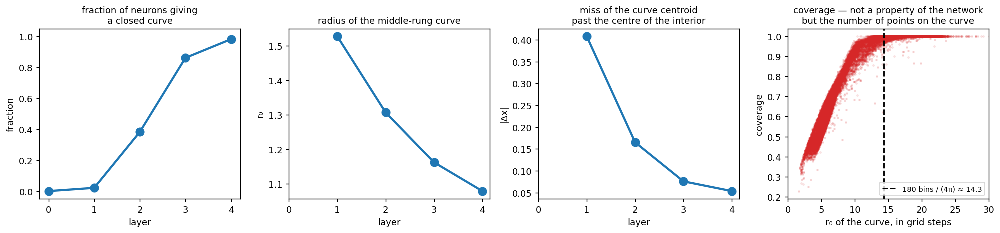

          fraction     r0  displacement
layer_id                               
0            0.000    NaN           NaN
1            0.021  1.527         0.408
2            0.382  1.306         0.165
3            0.861  1.162         0.076
4            0.982  1.078         0.054

Spearman coverage vs r₀/h: +0.974
Spearman coverage vs r₀ in length units: -0.011



median d_feat (honest distance over 6 harmonics) by layer and feature aspect,
in brackets — the number of neurons:
  layer 1: 1:1 → 0.122 (n=20)   1.5:1 → 0.115 (n=30)   2.5:1 → 0.304 (n=22)   4:1 → 0.431 (n=17)
  layer 2: 1:1 → 0.112 (n=385)   1.5:1 → 0.106 (n=479)   2.5:1 → 0.236 (n=487)   4:1 → 0.440 (n=408)
  layer 3: 1:1 → 0.108 (n=859)   1.5:1 → 0.100 (n=915)   2.5:1 → 0.245 (n=928)   4:1 → 0.442 (n=869)
  layer 4: 1:1 → 0.110 (n=988)   1.5:1 → 0.102 (n=988)   2.5:1 → 0.245 (n=990)   4:1 → 0.446 (n=992)


In [15]:
t = df[df.feature_role == "target"].copy()
t["r0_steps"] = t.harmonic_r0_mid / t.grid_step
by = t.groupby("layer_id").agg(
    fraction=("harmonic_a2_mid", lambda s: s.notna().mean()),
    r0=("harmonic_r0_mid", "median"),
    displacement=("harmonic_offset_x", lambda s: s.abs().median()))

fig, axes = plt.subplots(1, 4, figsize=(15.5, 3.7))
for ax, (col, ttl, ylab) in zip(axes[:3], [
        ("fraction", "fraction of neurons giving\na closed curve", "fraction"),
        ("r0", "radius of the middle-rung curve", "r₀"),
        ("displacement", "miss of the curve centroid\npast the centre of the interior", "|Δx|")]):
    ax.plot(by.index, by[col], "o-", lw=2.4, ms=9, color=gp.C_FEATURE)
    ax.set_xlabel("layer"); ax.set_ylabel(ylab); ax.set_xticks(by.index); ax.set_title(ttl, fontsize=10)
axes[0].set_ylim(-.05, 1.05)

tc = t.dropna(subset=["harmonic_coverage_mid"])
axes[3].scatter(tc.r0_steps, tc.harmonic_coverage_mid, s=3, alpha=.12, color=gp.C_INTERIOR)
axes[3].axvline(180/(4*np.pi), color="k", ls="--", lw=1.6,
                label="180 bins / (4π) ≈ 14.3")
axes[3].set_xlabel("r₀ of the curve, in grid steps"); axes[3].set_ylabel("coverage")
axes[3].set_xlim(0, 30); axes[3].legend(fontsize=8)
axes[3].set_title("coverage — not a property of the network\nbut the number of points on the curve", fontsize=10)
plt.tight_layout(); plt.show()

print(by.round(3).to_string())
print(f"\nSpearman coverage vs r₀/h: "
      f"{tc[['harmonic_coverage_mid','r0_steps']].corr(method='spearman').iloc[0,1]:+.3f}")
print(f"Spearman coverage vs r₀ in length units: "
      f"{tc[['harmonic_coverage_mid','harmonic_r0_mid']].corr(method='spearman').iloc[0,1]:+.3f}")

shl = gs.shape_by_cell(lv)
A_ = shl[(shl.block == "A") & (shl.rung == 2)]
lay = lv[(lv.block == "A") & (lv.rung == 2) & lv.dfeat.notna()]
print("\nmedian d_feat (honest distance over 6 harmonics) by layer and feature aspect,")
print("in brackets — the number of neurons:")
piv = lay.pivot_table(index="layer_id", columns="feature_aspect", values="dfeat", aggfunc="median")
cnt = lay.pivot_table(index="layer_id", columns="feature_aspect", values="dfeat", aggfunc="size")
for l in piv.index:
    print(f"  layer {l}: " + "   ".join(
        f"{a:g}:1 → {piv.loc[l, a]:.3f} (n={int(cnt.loc[l, a])})"
        for a in piv.columns if piv.loc[l, a] == piv.loc[l, a]))

**Observations.**

- **Layer 0 gives not a single closed curve** — exactly 0.000 of 14,000. This is not statistics but a
  theorem: the level curves of `tanh(w·x + b)` are straight lines. The instrument confirms it and thereby itself
  passes a check.
- Further on the fraction grows **0.02 → 0.38 → 0.86 → 0.98**: the closed structure is assembled with depth and
  by the last hidden layer it is present for almost every neuron.
- At the same time the curve **settles into place**: the radius falls 1.53 → 1.08, the miss of the centroid past the
  centre of the interior **0.41 → 0.05**, eightfold.
- **`coverage` turned out to be a quantity about the instrument, not about the network.** Its correlation with `r₀/h` is
  **+0.97**, and with `r₀` in length units **−0.01**. The profile is split into 180 angular bins, the curve
  is densified with step `h/2`, so it carries about `4π·r₀/h` points; at `r₀/h ≥ 14` there are enough of them for
  all bins and `coverage` comes out exactly 1. The fall "by layer" is entirely explained by the fact that the
  deep layers have a smaller `r₀` at the same grid step. Further on `coverage` is used only as a
  flag of the quality of the profile.
- The distance to the feature `d_feat` changes little across layers and does not approach zero on any layer.

**Conclusion.** Depth builds **enclosure and centring**. What it does with the shape — this section is not
enough to say: the numbers above are averaged over different cells, and `d_feat` depends on
what the feature itself is like. Shape is taken apart in blocks A and B, where the cells are not mixed.


### Is the shape of the curve dictated by the layer number

The level curves in the pictures above show "corners" — places where the curve runs almost straight and then
turns sharply. A hypothesis worth checking directly: is the **number of corners** related to
the layer number — say, the third harmonic to the third layer, the fourth to the fourth. The check
is free: the amplitudes `a₁…a₆` of the middle rung are in the results table.

Below are three panels. On the left, the median amplitude of each harmonic by layer: how pronounced each
"angularity" is at all. In the middle, the fraction of neurons whose **largest** harmonic
is exactly `k`: which of them is the main one for an individual curve, not on average. On the right, `a₃` and `a₄` by
layer and by the elongation of the feature: if the corners are dictated by the layer, the lines for different layers should diverge, and along
the elongation they should not.


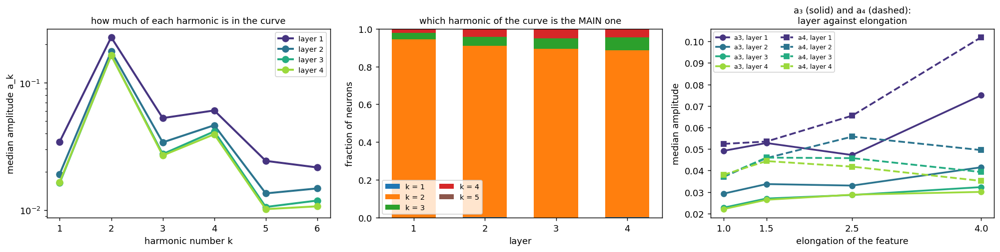

median amplitudes by layer:
              a1      a2      a3      a4      a5      a6
layer_id                                                
1         0.0345  0.2281  0.0530  0.0608  0.0244  0.0217
2         0.0192  0.1766  0.0341  0.0465  0.0136  0.0148
3         0.0164  0.1648  0.0276  0.0416  0.0106  0.0119
4         0.0166  0.1646  0.0269  0.0395  0.0102  0.0107

fraction of neurons whose main harmonic = k:
kmax          1      2      3      4      5
layer_id                                   
1         0.000  0.944  0.034  0.022  0.000
2         0.002  0.908  0.047  0.043  0.000
3         0.001  0.893  0.055  0.050  0.001
4         0.002  0.884  0.069  0.044  0.001


In [16]:
tA = df[(df.feature_role == "target") & (df.block == "A") & (df.layer_id > 0)].copy()
tA = tA.dropna(subset=["harmonic_a2_mid"])
AK = [f"harmonic_a{k}_mid" for k in range(1, 7)]
med = tA.groupby("layer_id")[AK].median()
tA["kmax"] = np.argmax(tA[AK].values, axis=1) + 1
share = pd.crosstab(tA.layer_id, tA.kmax, normalize="index")

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.0))
lay_col = plt.cm.viridis(np.linspace(.15, .85, len(med)))
for c, l in zip(lay_col, med.index):
    axes[0].plot(range(1, 7), med.loc[l], "o-", lw=2.2, ms=7, color=c, label=f"layer {l}")
axes[0].set_xlabel("harmonic number k"); axes[0].set_ylabel("median amplitude a_k")
axes[0].set_yscale("log"); axes[0].legend(fontsize=8)
axes[0].set_title("how much of each harmonic is in the curve", fontsize=10)

bottom = np.zeros(len(share))
kcol = plt.cm.tab10(np.linspace(0, .5, share.shape[1]))
for c, k in zip(kcol, share.columns):
    axes[1].bar(share.index, share[k], .62, bottom=bottom, color=c, label=f"k = {k}")
    bottom += share[k].values
axes[1].set_xlabel("layer"); axes[1].set_ylabel("fraction of neurons")
axes[1].set_xticks(share.index); axes[1].legend(fontsize=8, ncol=2)
axes[1].set_title("which harmonic of the curve is the MAIN one", fontsize=10)

for k, ls, mk in ((3, "-", "o"), (4, "--", "s")):
    piv = tA.pivot_table(index="feature_aspect", columns="layer_id",
                         values=f"harmonic_a{k}_mid", aggfunc="median")
    for c, l in zip(lay_col, piv.columns):
        axes[2].plot(piv.index, piv[l], ls, marker=mk, lw=2.0, ms=6, color=c,
                     label=f"a{k}, layer {l}")
axes[2].set_xlabel("elongation of the feature"); axes[2].set_ylabel("median amplitude")
axes[2].set_xticks([1, 1.5, 2.5, 4]); axes[2].legend(fontsize=7, ncol=2)
axes[2].set_title("a₃ (solid) and a₄ (dashed):\nlayer against elongation", fontsize=10)
plt.tight_layout(); plt.show()

print("median amplitudes by layer:")
print(med.rename(columns=lambda s: s.replace("harmonic_", "").replace("_mid", ""))
      .round(4).to_string())
print("\nfraction of neurons whose main harmonic = k:")
print(share.round(3).to_string())


**Observations.**

- **The layer number does not dictate the corners.** The main harmonic is the second (elongation) for **88–94%**
  of neurons on **every** layer. The fractions of `k = 3` and `k = 4` grow with depth very weakly (0.034 → 0.069
  and 0.022 → 0.044) and nowhere form a peak at "their own" layer.
- **Depth does not add corners but removes them.** Along the series of layers 1 → 4 the median amplitudes fall
  monotonically, and the more so the higher the harmonic: `a₃` 0.053 → 0.027, `a₄` 0.061 → 0.040,
  `a₅` 0.024 → 0.010, `a₆` 0.022 → 0.011. The elongation meanwhile falls much more weakly:
  `a₂` 0.228 → 0.165. That is, with depth the curve **rounds off**, keeping its elongation.
- **What moves `a₄` is the elongation of the feature, and only on the first layer.** On layer 1, with a 4:1 feature,
  `a₄ = 0.102` against 0.052 for the round one; by layer 4 this dependence disappears and even changes sign
  (0.038 against 0.035). `a₃` behaves the same way, only more weakly.

**How to read this.** The curve of a neuron of the first hidden layer is a composition of five linear
functions (the width of the network = 5), so its level curve resembles a polygon, and its high harmonics
are large by construction. Deeper there are more compositions, and the corners are smoothed out. This is an **interpretation**, not
a result: it can be checked only on the width axis, which this experiment does not have — the whole
grid is trained at `w5 d5`. The width axis exists in experiment 2, and that is where this question should be asked.


---

## 1.8 Summary of section 1

1. Shape is **a vector of six harmonics with phases**, not a number; the distance is made up of all
   six, and which of them is the main one depends on the pair of curves (1.2).
2. The instrument's own accuracy is **0.010 at `r₀ ≥ 4` grid steps**, and this must be distinguished from the step
   of the design's aspect grid (0.144), which we chose. The ratio of one to the other is fourteen
   (1.3).
3. The main quantity is **λ**; it degenerates where the shapes of the objects coincide, and such cells
   (the diagonal of block A) serve as a control, not as a result (1.4).
4. The levels are chosen by two rules, symmetric between the two objects: **by the field value** and
   **by radius**. One has to look at all rungs at once; a single one is taken only when one number per
   cell is needed (1.5).
5. What the ladder looks like on data is shown on four examples; they pose the question for blocks
   A–D but by themselves prove nothing (1.6).
6. **Depth builds enclosure and centring**: the fraction of closed curves 0 → 0.98, the miss of the centroid
   0.41 → 0.05. Nothing can be said about shape from these data — the cells are mixed (1.7).
7. **The layer number does not dictate the shape**: the main harmonic is the second for 88–94% of neurons on every
   layer, and depth does not add the high harmonics but removes them — `a₃` 0.053 → 0.027,
   `a₄` 0.061 → 0.040 from layer 1 to layer 4 (1.7).
8. **`coverage` is a quantity about the instrument**, not about the network: its correlation with `r₀/h` is 0.97, with `r₀` in
   length units it is zero (1.7).


---
# 2. Block A. Shape against shape

## Setting

Sixteen cells: the aspect of the **feature** (1 / 1.5 / 2.5 / 4) against the aspect of the **interior** (the same
four). The objects are concentric, the size of the interior and the number of points do not change — only
the shape of the two objects varies, independently of each other.

**The main hypothesis of the programme** after experiments 1 and 2 is this: a relevant topological
feature is set **jointly** — by the feature itself and by the set of the opposite class
inside it. Experiments 1 and 2 could not test it: there both objects are round and concentric,
and "the shape is set by the feature" and "the shape is set by the interior" predict one and the same thing. Block A is
the first configuration where the two contributions are separated and can be measured apart.

Hence three particular hypotheses about the shape of the level curve:

| | hypothesis | prediction |
|---|---|---|
| **a** | the shape is set by the **feature** | the aspect of the curve grows together with the aspect of the feature |
| **b** | the shape is set by the **interior** | the aspect of the curve grows together with the aspect of the interior |
| **c** | the shape is **its own** and hardly depends on the objects | the aspect of the curve hardly changes across the grid |

The diagonal is a control: there the objects are similar, `objects_shape = 0`, and (a) and (b) are indistinguishable by
construction (1.4). Everything said about λ and about the distances to the objects refers to the fifteen
off-diagonal cells.

## Protocol: how all the numbers of this section are computed

Averaging is the place where it is easiest to cheat without noticing, so there is one rule for the whole section,
and it coincides with the one frozen for the structural criterion:

> **for a pair (cell, model) the EXTREMUM over neurons is taken, then the distribution
> over the 50 models is shown.** No averaging over neurons and no averaging over cells.

The extremum is the minimum of the shape distance: "has **at least one** neuron been found whose level curve carries
this shape". This is exactly the same question that the structural criterion asks ("has at least one
neuron been found whose level curve coincided with the target"), and that is why the numbers of the two instruments are comparable. Where
not a selection but the distribution of shapes itself is shown (2.2, 2.5), **all** curves are drawn without any
selection — and this is stated at each figure.

**The data of the section are one table.** The run saved the full spectrum only for the middle rung, while
sections 2.2–2.6 need it on every rung, so the ladder was recomputed anew for **all** neurons
of layers 1–4 of all fifty models of all fifty-six cells: 50 × 20 × 5 rungs per cell.
This is not a second measurement but the same computation: the field window, the anchors of the ladder, the contour extraction and the
descriptor are taken from `analysis.shape_descriptors`, which the server computed with, and the agreement with its
columns `r₀`, `d_feat`, `d_int` has been checked — the discrepancy is 7·10⁻⁷. The table is built once
(`analysis.harmonic_ladder.build`) and lies next to the results of the run.

Layer 0 is not in it: its level curves are straight lines, and there is no closed curve there by theorem (1.7).

**On the threshold 0.144.** The shape distance is read literally: `d = 0.10` means that two curves
diverge in root mean square by 10% of their radius (this is Parseval's equality, 1.2). The threshold
0.144 is the distance between a circle and a 1.5:1 ellipse, that is, the smallest difference of shapes that the
design must resolve. It is **named, not tuned**, but it is still a convention, so everywhere
a fraction is computed by it, the distribution of the distances itself is shown alongside.

Below are all sixteen datasets, so that it is clear further on what we are talking about.

## Map of the section

The section is large, so here is what is settled where — one line per subsection.

| | question | answer in one line |
|---|---|---|
| **2.1** | what it looks like at all | the curves of all sixteen cells against the background of the neuron's field |
| **2.2.1** | does the elongation change along the ladder | no; it is moved by the interior, not by the feature |
| **2.2.2** | how the distribution is arranged | a dense mass at 1–2 plus a right group weighing up to 34% |
| **2.2.3** | **what can describe it** | three constructions; the best is the equilibrium potential of the pair, but none gives both halves of the effect |
| **2.3.1** | what an individual network is capable of | the most elongated neuron of a model against a typical one |
| **2.3.2** | the right group — a population or junk | a population: four independent checks |
| **2.3.3** | what is special about networks that give elongated curves | nothing, except that they place the curves closer |
| **2.4** | whose shape the curve carries | nobody's in full; it is closest to a circle |
| **2.5** | where it is elongated | along the common axis of the objects; the order is set by the interior |
| **2.6** | does the shape change along the family | hardly, and independently of the difference of the objects |
| **2.7** | what the structural and homological criteria say | the same break; the homological one loses specificity |
| **2.8** | summary | |


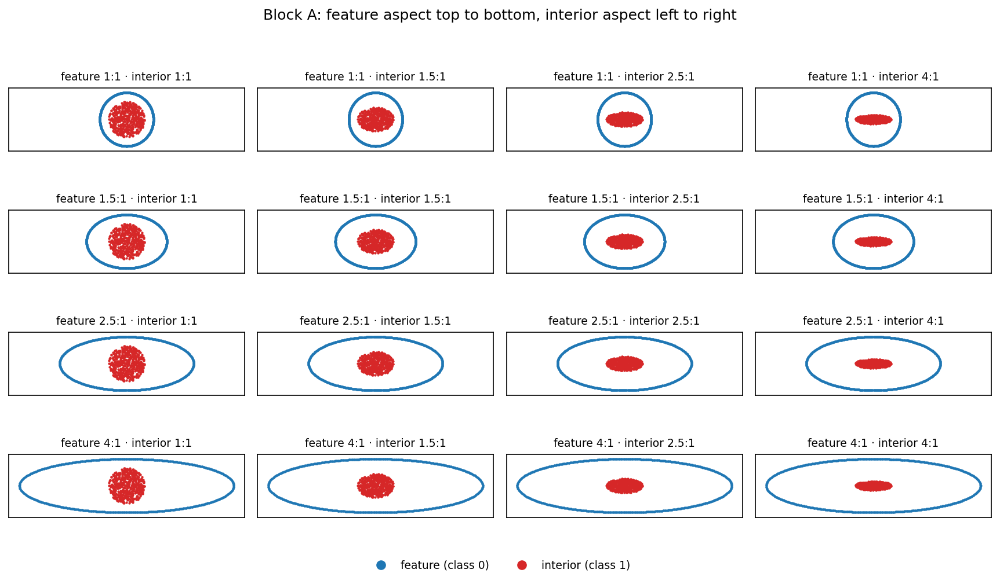

In [17]:
gp.plot_cell_gallery(
    plan_A := sorted(cells[cells.block == "A"].dataset_type),
    [f"feature {r.feature_aspect:g}:1 · interior {r.interior_aspect:g}:1"
     for r in cells_meta.loc[plan_A].itertuples()],
    ncols=4, panel=2.9,
    suptitle="Block A: feature aspect top to bottom, interior aspect left to right")
plt.show()

## 2.1 First, look: the curves of all sixteen cells

Before computing anything, one has to see the object. Below are all sixteen cells of block A, in
each one neuron of one model, and for it **all five rungs** of the value ladder.

Three decisions, each of which changes the picture and is therefore named explicitly.

**Which model.** The median one for the cell: of the fifty models, the one is taken whose best neuron gives the
median structural score. Not the best — otherwise sixteen panels would show sixteen
lucky cases.

**Which neuron.** Two grids, two rules. In the first, the **best by structural score** neuron of this
model: the curve that came closest to the feature, that is, the best the model is capable of. In the
second, the **median by score** among the neurons with a closed curve: an ordinary neuron of the same model.
The second rule is important in its own right: if both grids turn out alike, then the neurons within a model
are interchangeable, and "the best neuron" is not a special find but a typical representative.

**The background is the field of the neuron**, as in 1.5: the colour is the rank of the value, and where the colour changes fast, the field
is steep. The frame is common **within a row** (a row has one and the same feature, so the sizes are comparable), but
differs between rows: the 4:1 feature is four times longer than the round one, and a frame common to the whole grid would make
the top row unreadable.


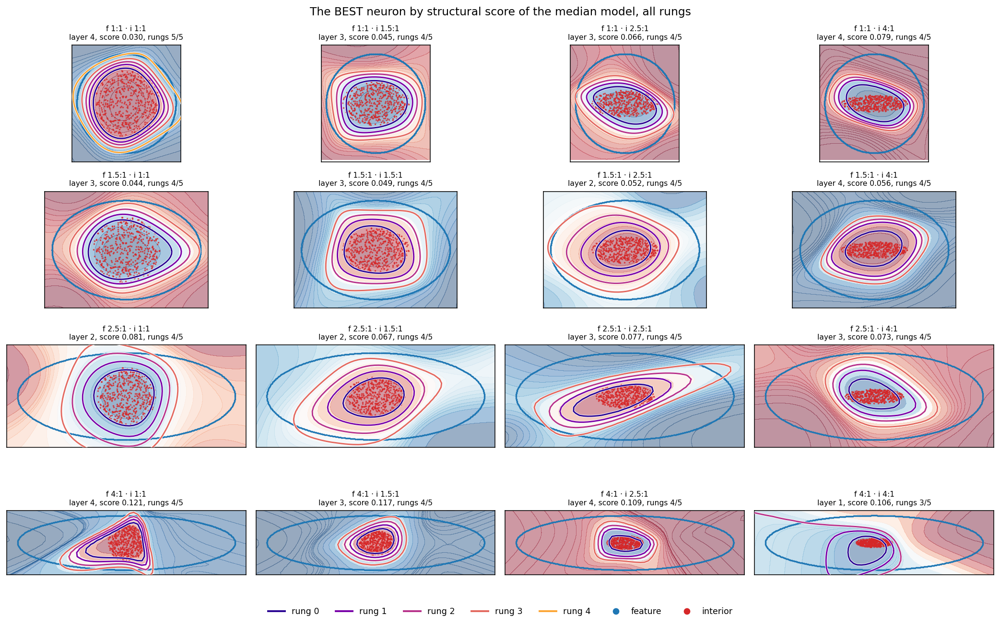

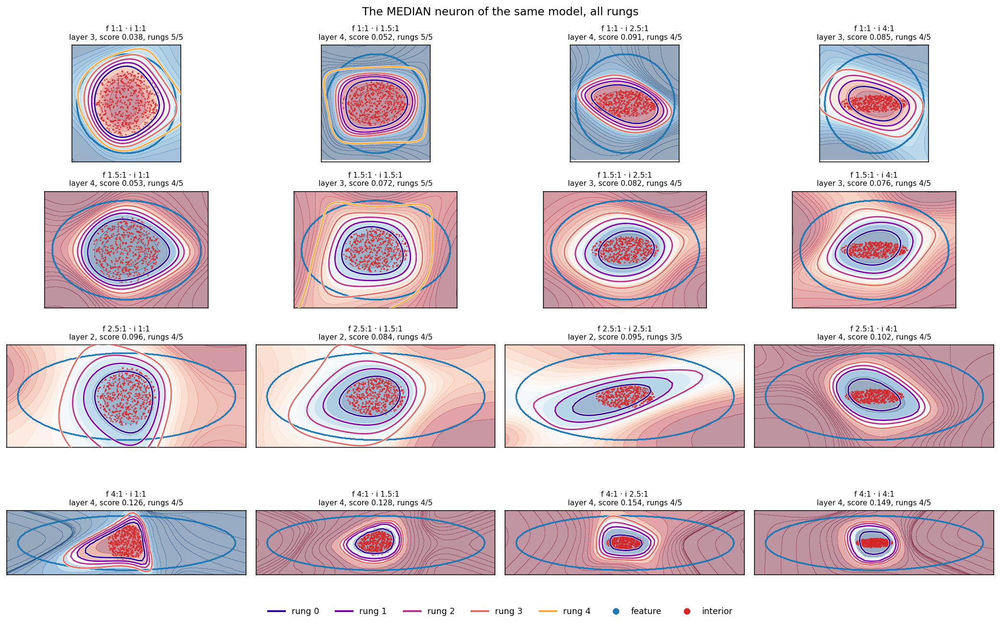

best against median neuron of ONE AND THE SAME model:
                         cell  same_neuron  score_best  score_median  d_between_curves
feature 1.0:1, interior 1.0:1        False       0.030         0.038             0.016
feature 1.0:1, interior 1.5:1        False       0.045         0.052             0.006
feature 1.0:1, interior 2.5:1        False       0.066         0.091             0.030
feature 1.0:1, interior 4.0:1        False       0.079         0.085             0.009
feature 1.5:1, interior 1.0:1        False       0.044         0.053             0.026
feature 1.5:1, interior 1.5:1        False       0.049         0.072             0.023
feature 1.5:1, interior 2.5:1        False       0.052         0.082             0.022
feature 1.5:1, interior 4.0:1        False       0.056         0.076             0.017
feature 2.5:1, interior 1.0:1        False       0.081         0.096             0.063
feature 2.5:1, interior 1.5:1        False       0.067         0.084        

In [18]:
from analysis.shape_descriptors import fourier_descriptor, shape_distance

tgt_all = df[(df.feature_role == "target") & (df.block == "A")]

def typical_model(name):
    # the model whose best neuron gives the median score of the cell
    g = best[(best.dataset_type == name) & (best.feature_role == "target")]
    order = g["score"].sort_values()
    return g.loc[order.index[len(order)//2]]

def neuron_of(name, mrow, which):
    g = tgt_all[(tgt_all.dataset_type == name) & (tgt_all.model_path == mrow.model_path)
                & (tgt_all.layer_id > 0)]
    if which == "best":
        r = g.loc[g.structural_score_normalized_by_diameter.idxmin()]
    else:
        gg = g[g.harmonic_n_closed > 0].sort_values("structural_score_normalized_by_diameter")
        r = gg.iloc[len(gg)//2]
    return int(r.layer_id), int(r.coord_id), float(r.structural_score_normalized_by_diameter)

# one pass: fields are computed once per neuron, the pictures are drawn from what is ready
panels, cmp_rows = {}, []
for name in plan_A:
    mrow = typical_model(name)
    for which in ("best", "typical"):
        layer, coord, sc = neuron_of(name, mrow, which)
        LL = gs.ladder_curves(name, model_path=mrow.model_path, layer_id=layer,
                              coord_id=coord)
        panels[(name, which)] = dict(layer=layer, coord=coord, score=sc, LL=LL)
    b, t = panels[(name, "best")], panels[(name, "typical")]
    cb, ct = b["LL"]["curves"][2], t["LL"]["curves"][2]
    cmp_rows.append(dict(
        cell=cells_meta.loc[name, "label"],
        same_neuron=(b["layer"], b["coord"]) == (t["layer"], t["coord"]),
        score_best=b["score"], score_median=t["score"],
        d_between_curves=(np.nan if cb is None or ct is None else
                         shape_distance(fourier_descriptor(cb), fourier_descriptor(ct)))))

def draw_ladder_grid(which, title):
    fig, axes = plt.subplots(4, 4, figsize=(15, 9.2), dpi=140)
    for row in range(4):
        names = plan_A[4*row:4*row+4]
        hx, hy = gp.cells_extent(names)                # common frame within a row
        for ax, name in zip(axes[row], names):
            meta, P = cells_meta.loc[name], panels[(name, which)]
            X, y, A = gs.dataset_points(name)[:3]
            gp.field_background(ax, P["LL"]["field"], window=(hx, hy),
                                alpha=.42, levels=17)
            ax.scatter(X[y == 1, 0], X[y == 1, 1], s=.7, c=gp.C_INTERIOR,
                       alpha=.7, zorder=1)
            ax.scatter(A[:, 0], A[:, 1], s=.7, c=gp.C_FEATURE, zorder=2)
            got = 0
            for j, cu in enumerate(P["LL"]["curves"]):
                if cu is None:
                    continue
                got += 1
                gp.draw_curve(ax, cu.numpy(), ramp[j], lw=1.5, zorder=3+j, halo=1.0)
            ax.set_xlim(-hx, hx); ax.set_ylim(-hy, hy)
            ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
            ax.set_title(f"f {meta.feature_aspect:g}:1 · i {meta.interior_aspect:g}:1"
                         f"\nlayer {P['layer']}, score {P['score']:.3f}, rungs {got}/5",
                         fontsize=8)
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    fig.legend(handles=[plt.Line2D([], [], color=ramp[j], lw=2, label=f"rung {j}")
                        for j in range(5)]
               + [plt.Line2D([], [], marker="o", ls="", color=gp.C_FEATURE, label="feature"),
                  plt.Line2D([], [], marker="o", ls="", color=gp.C_INTERIOR,
                             label="interior")],
               loc="lower center", ncol=7, fontsize=9, frameon=False,
               bbox_to_anchor=(.5, -.02))
    plt.show()

draw_ladder_grid("best", "The BEST neuron by structural score of the median model, all rungs")
draw_ladder_grid("typical", "The MEDIAN neuron of the same model, all rungs")

cmp = pd.DataFrame(cmp_rows)
print("best against median neuron of ONE AND THE SAME model:")
print(cmp.round(3).to_string(index=False))
print(f"\nsame neuron: {int(cmp.same_neuron.sum())} cells of {len(cmp)}")
print(f"median difference of scores: {(cmp.score_median - cmp.score_best).median():.3f}")
print(f"median SHAPE distance between their middle curves: "
      f"{cmp.d_between_curves.median():.3f} "
      f"(design step 0.144, accuracy of the instrument ~0.01)")


**Observations.**

- **Top row: the feature is round in all four cells, but the curves are not.** In the left cell both
  objects are round, the curve is round, the outer rungs lie right on the feature: this is that very degenerate
  configuration of experiments 1 and 2, where one cannot tell from the picture whose shape the curve repeats.
  But further right along the row **the feature does not change**, while the curves become more and more elliptical
  following the interior — and in the right cell they are already noticeably elongated with a round feature. The degeneracy
  is lifted exactly here, and it is the interior that lifts it.
- **Bottom row: the feature is 4:1, and no curve follows it.** All five rungs remain
  compact and stay with the interior; between the curve and the ends of the feature there remains an empty space
  several radii long. The field there is not flat — the fold is visible — it just
  goes around the feature.
- **The best and the median neuron are different neurons, but almost one curve.** They coincide in none
  of the 16 cells, the difference of the scores is 0.017 in median, and the SHAPE distance between their middle curves is
  **0.025** in median, six times less than the design step 0.144. That is, "the best neuron" here is not a
  unique find but a representative: within a model the neurons are almost interchangeable. There is one exception,
  and it makes sense — the cell "both 4:1", where `d = 0.245`: there the models really do not agree
  on what to draw.
- **The outer rung is most often absent** — in 14 cells of 16, 4 of 5 rungs are shown. This was
  measured in 1.5 and is simply visible here.

**Conclusion (preliminary, before counting).** The picture poses the question rather than answering it: it looks as if the
curve stays with the interior and does not stretch after the elongated feature. But sixteen panels are
sixteen neurons out of 20,000, and any of them could have been chosen luckily. Further on the same thing
is measured over all neurons of all models.


## 2.2 Elongation: all neurons

Picture 2.1 showed sixteen neurons. Now the same over **all** neurons of all
fifty models of each cell — layers 1–4, all five rungs of the ladder **by value**.
Layer 0 is excluded not selectively: its level curves are straight lines, a closed curve never occurs there by
theorem (1.7), and including it would mean diluting the sample with gaps known in advance.

This is a recomputation, not a second table: the field, the ladder, the contour and the descriptor are the same as the
server run computed, and the agreement with its columns has been checked to the seventh digit. The run kept the full
spectrum only for the middle rung; here it is available on every rung; everything else is the same.

**The quantity.** The elongation of the curve, recomputed from the second harmonic by the formula
`(1 + a₂)/(1 − a₂)` — the same ratio of axes by which the objects themselves are described, so the curve and the
objects can be put on one scale. The conversion is exact for an ellipse and approximate for anything else
(1.3), and the shape in the full sense remains the vector of six harmonics — it will appear in 2.4 and 2.6.

The section is split into three parts: **by rung** (does the elongation change along the family),
**by distribution** (do the neurons have regimes) and **by the geometry of the gap** (is the
elongation not forced by the configuration itself, regardless of the network).


### 2.2.1 By rung of the ladder

One panel per cell, five strata in each — one per rung. The dashed line is the elongation of the feature, the dotted one that of the interior, the black bar is the median of the rung. There are about 2,500 points in a panel, so they are small and semi-transparent; the shape of the cloud and the median can be read, a single point cannot, and should not.


curves: 39 718 | neurons: 10 905 | models per cell: [50]
elongation above 4.5: 0.54% of curves; maximum 14.0
at the upper edge of the scale (a₂ larger than any ellipse has): 0.12%


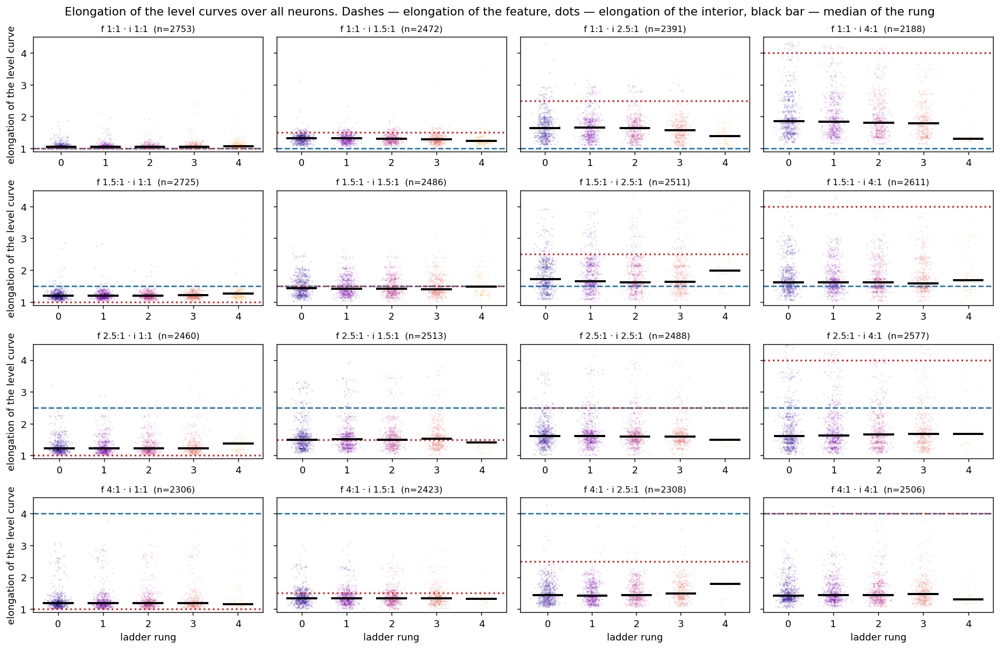

In [19]:
hl = gs.load_harmonic_ladder("value")                  # the full spectrum on every rung
sub = hl[(hl.block == "A") & (hl.layer_id > 0)].copy()
print(f"curves: {len(sub):,}".replace(",", " "),
      f"| neurons: {sub.groupby(['dataset_type','model_index','layer_id','coord_id']).ngroups:,}"
      .replace(",", " "),
      f"| models per cell: {sub.groupby('dataset_type').model_index.nunique().unique()}")

YTOP = 4.5                       # above — the tail, its fraction is printed below
print(f"elongation above {YTOP}: {(sub.aspect > YTOP).mean():.2%} of curves; "
      f"maximum {sub.aspect.max():.1f}")
print(f"at the upper edge of the scale (a₂ larger than any ellipse has): "
      f"{(sub.a2 > 0.9).mean():.2%}")

fig, axes = plt.subplots(4, 4, figsize=(14.5, 9.5), sharey=True)
rng = np.random.default_rng(0)
for ax, name in zip(axes.flat, plan_A):
    meta = cells_meta.loc[name]
    g = sub[sub.dataset_type == name]
    for j in range(5):
        v = g[g.rung == j]["aspect"]
        if not len(v):
            continue
        ax.scatter(rng.normal(j, .10, len(v)), v, s=3, alpha=.12, color=ramp[j],
                   linewidths=0)
        ax.plot([j-.32, j+.32], [v.median()]*2, color="k", lw=2.2, zorder=5)
    ax.axhline(meta.feature_aspect, color=gp.C_FEATURE, ls="--", lw=1.5)
    ax.axhline(meta.interior_aspect, color=gp.C_INTERIOR, ls=":", lw=1.8)
    ax.set_xticks(range(5)); ax.set_ylim(.9, YTOP)
    ax.set_title(f"f {meta.feature_aspect:g}:1 · i {meta.interior_aspect:g}:1  "
                 f"(n={len(g)})", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("ladder rung")
for ax in axes[:, 0]:
    ax.set_ylabel("elongation of the level curve")
fig.suptitle("Elongation of the level curves over all neurons. Dashes — elongation of the feature, "
             "dots — elongation of the interior, black bar — median of the rung", fontsize=12)
plt.tight_layout(); plt.show()


**Observations.**

- **The curve is noticeably rounder than both objects.** The median elongation across cells lies between
  **1.05 and 1.85**, while the objects cover the series 1 : 1.5 : 2.5 : 4. In no cell does the median
  come close to 4 or even to 2.5.
- **It is moved by the interior, not by the feature.** The marginal effect (the median of a cell, averaged over the
  other axis): the elongation of the **interior** leads the curve 1.17 → 1.39 → 1.58 → 1.63 —
  monotonically, range **0.46**; the elongation of the **feature** gives 1.45 → 1.48 → 1.49 → 1.35 — range
  **0.14**, and the series is not monotone, the last value is below the first. Three times smaller in magnitude and without
  order.
- **This is visible without numbers too.** In the top row (the feature is round) the median grows from left to right together
  with the interior; in the bottom row (the feature is 4:1) it stands still, while the dashed line of the aspect of the feature
  runs far above and is never reached.
- **Along the ladder the median hardly changes** — on rungs 0–3 the spread is within 0.05.
  Rung 4 sometimes drops out of the series in the table (for example 1.79 → 1.30), but this is **not a change
  of shape**: the outer rung exists for only 10% of neurons (1.5), and it is a different subsample, not a different
  shape. A direct check of the same question is in 2.6, on the neurons that have both extreme rungs.
- **An important caveat about the feature axis.** Elongating the feature at an unchanged interior, we change not
  only its shape: its area grows fourfold from 1:1 to 4:1, while the interior stays the same. That
  is, along this axis the **relative size** of the objects changes at the same time, and with it how much
  room is left for the curve. So the observed drop in elongation along the feature axis cannot be
  attributed to its shape: it is equally compatible with "more freedom — rounder". These two
  explanations cannot be separated on our grid, and Section 10.7 of the paper shows why: all
  dimensionless measures of freedom are coupled with the elongation of the interior at +0.68…+0.79, because the
  design elongates the interior at a fixed major semi-axis.
- **The spread within a cell is large and structured**: every panel shows a dense cloud at 1–2 and
  separate points noticeably higher. Whether this is a tail or a second group is decided in 2.2.2.


### 2.2.2 The distribution by cell: how it is arranged

The strata show the median, and the question about the **shape of the distribution** is not settled by the median. Below are the same
curves as distributions — all rungs together, one panel per cell.

**What is claimed here and what is not.** What is claimed is the observable: the distribution
has a dense main mass and **a separate group on the right**, whose weight varies strongly between
cells. It is not claimed that this is a "second mode" in the statistical sense, and here is why.

I did compute a formal test for the number of modes (Silverman's test of the critical bandwidth, with a smoothed
bootstrap) — its `p` stands on the panels in small print. But it answers **not the question
we are asking**. Two cases show this cleanly. In the basic cell "circle in circle" there are **exactly zero** curves with an
elongation above 2, yet the test rejects unimodality: the fold sits right at
one and has nothing to do with the right group. Conversely, in the cell with the largest right group
(weight 34%) the test **does not reject** unimodality: the distribution there is smooth. That is, "how many
folds the density has" and "is there a second population of neurons" are different questions, and the first does not answer
the second.

That is why a direct quantity is used further on — **the weight of the right group**, the fraction of curves with an elongation
above 2 — and the question "population or junk" is decided not by the shape of the histogram but by the behaviour of these
curves: whether they cluster by network, whether they stay with one neuron, whether they point the same way. That is
the business of 2.3.


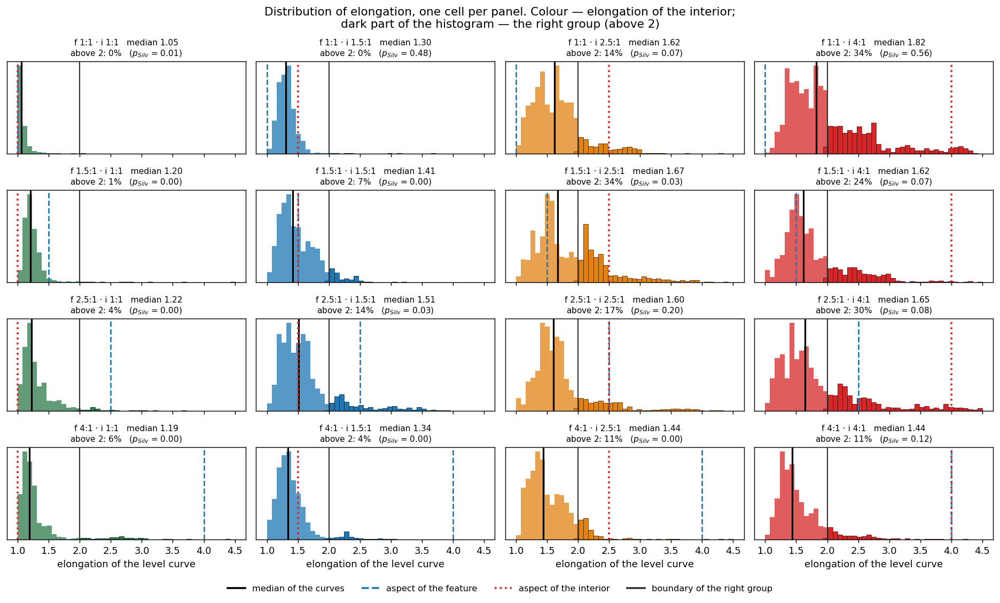

weight of the right group: from 0.2% to 34.2%; grows with the elongation of the INTERIOR (3% → 6% → 19% → 25%) and hardly depends on the feature (12% → 17% → 16% → 8%)
median of the right group itself: 2.13–2.86 across cells — it does NOT follow the interior (otherwise at 4:1 it would stand at 4)
the Silverman test rejects unimodality in 9 cells of 16, but not in those where the group is largest: it answers a different question (see the text above)


In [20]:
one = sub[sub.rung == 2]                      # one value per neuron
sil = {name: gs.modality(one[one.dataset_type == name].a2.values, n_boot=200)["p_unimodal"]
       for name in plan_A}

fig, axes = plt.subplots(4, 4, figsize=(14.5, 8.6), sharex=True)
bins = np.linspace(1, 4.5, 46)
for ax, name in zip(axes.flat, plan_A):
    meta = cells_meta.loc[name]
    v = sub[sub.dataset_type == name].aspect
    ax.hist(v, bins=bins, color=COL[meta.interior_aspect], alpha=.75)
    ax.hist(v[v > 2], bins=bins, color=COL[meta.interior_aspect], alpha=1.0,
            edgecolor="k", linewidth=.3)
    ax.axvline(2, color="#333", lw=1.2, ls="-")
    ax.axvline(float(v.median()), color="k", lw=1.8)
    ax.axvline(meta.feature_aspect, color=gp.C_FEATURE, ls="--", lw=1.5)
    ax.axvline(meta.interior_aspect, color=gp.C_INTERIOR, ls=":", lw=2.0)
    ax.set_yticks([])
    ax.set_title(f"f {meta.feature_aspect:g}:1 · i {meta.interior_aspect:g}:1   "
                 f"median {v.median():.2f}\nabove 2: {float((v > 2).mean()):.0%}"
                 f"   ($p_{{Silv}}$ = {sil[name]:.2f})", fontsize=8.5)
for ax in axes[-1]:
    ax.set_xlabel("elongation of the level curve")
fig.legend(handles=[plt.Line2D([], [], color="k", lw=2, label="median of the curves"),
                    plt.Line2D([], [], color=gp.C_FEATURE, lw=2, ls="--", label="aspect of the feature"),
                    plt.Line2D([], [], color=gp.C_INTERIOR, lw=2, ls=":", label="aspect of the interior"),
                    plt.Line2D([], [], color="#333", lw=2, label="boundary of the right group")],
           loc="lower center", ncol=4, fontsize=9, frameon=False, bbox_to_anchor=(.5, -.015))
fig.suptitle("Distribution of elongation, one cell per panel. Colour — elongation of the interior;\n"
             "dark part of the histogram — the right group (above 2)", fontsize=12)
plt.tight_layout(rect=[0, .02, 1, 1]); plt.show()

w = sub.assign(hi=lambda d: d.aspect > 2).groupby(
    ["feature_aspect", "interior_aspect"]).hi.mean().unstack()
print(f"weight of the right group: from {w.values.min():.1%} to {w.values.max():.1%}; "
      f"grows with the elongation of the INTERIOR ({' → '.join(f'{x:.0%}' for x in w.mean(axis=0))}) "
      f"and hardly depends on the feature ({' → '.join(f'{x:.0%}' for x in w.mean(axis=1))})")
tail_med = sub[sub.aspect > 2].groupby("dataset_type").aspect.median()
print(f"median of the right group itself: {tail_med.min():.2f}–{tail_med.max():.2f} across cells — "
      f"it does NOT follow the interior (otherwise at 4:1 it would stand at 4)")
print(f"the Silverman test rejects unimodality in "
      f"{sum(p < .05 for p in sil.values())} cells of {len(sil)}, but not in those where the group "
      f"is largest: it answers a different question (see the text above)")


**Observations.**

- **The right group is visible by eye almost everywhere, and its weight is computed directly.** It goes from 0% with both
  objects round to **34%** with a 4:1 interior and a round feature.
- **The weight grows with the elongation of the interior and hardly depends on the feature** — exactly like the median
  from 2.2.1, that is, it is the same effect, only seen in another part of the distribution.
- **The group does not copy the interior.** Its own median stays at **2.1–2.9 in all
  sixteen cells**: were it a copy, at a 4:1 interior it would stand at 4. So these are not
  "neurons that repeated the interior" but something with its own scale.
- **The formal test misses.** It rejects unimodality in 9 cells of 16, but among them is the basic
  "circle in circle", where there is no right group at all — and it does not reject in the cell where the group
  is largest. As an instrument for our question it is unfit, and I do not rely on it.


### 2.2.3 Three approaches to describing the observable

Sections 2.2.1 and 2.2.2 reported **the observed behaviour**: the curve is rounder than both objects, its
elongation grows with the elongation of the interior and reacts to the feature in different ways — it adds when the
interior is round and subtracts when it is elongated.

What follows are **models**, that is, geometric constructions that reproduce this behaviour or
do not. **None of them is a statement about a cause.** There is no ablation in the experiment,
we do not observe the mechanism of training, and all that can be said is how precisely one or another
construction, computed from the geometry of the pair alone, coincides with what was measured. The word "explains"
means only this further on.

The comparison rule is one for all models, and it is strict: **the prediction is computed from the "annulus"** —
the interior, the feature and the space between them — and **uses not a single number measured on
the curves**. Earlier I tuned the parameter of a model to the observed mean radius `r₀`; this gave
overly good numbers, because the model peeked at the scale of what it is supposed to predict.
Below everything is recomputed without this: for the dilation `δ` is taken as a fraction of the minimal gap, for the
harmonic potential the level is fixed, both constants are one for the whole grid.

The measure of quality is **the mean absolute error** in elongation, and it has to be read on the scale of
the measurements themselves. A baseline "always name the median over the grid" cannot exist here, and this matters:
what is predicted is not a single neuron but a **population quantity of the cell** — the median over all its
curves — so a constant fitted to the same sixteen answers is not a null model but an
oracle. The scale is set by three measured quantities: the predicted number is itself known to within
about **±0.09** (the half-width of the bootstrap over the fifty networks of a cell; across cells 0.01–0.18), across the grid
it spans **0.77**, and the two effects separated by the design are worth **0.46** (interior) and
**0.14** (feature). A construction that errs by more does not resolve the corresponding effect.

**One caveat that has to be kept in mind all the way.** The axis "elongation of the feature" is not a pure
shape axis: elongating the feature at a fixed minor semi-axis, we increase its area fourfold and
thereby give the curve more room. So everything attributed below to "the shape of the feature" may
turn out to be an effect of **relative size**. The models that distinguish these two readings are indistinguishable on our
grid, and this is a limitation of the design, not of the analysis.

**One premise without which the discussion is meaningless.** A round level curve separates the classes in
**all 56 cells of the experiment**: a disk containing the interior and lying inside the feature exists
everywhere, and in block A it is even concentric — the interior keeps the major semi-axis 1.00, the feature the minor one
1.50, so any circle of radius from 1.00 to 1.50 will do, with the same margin 0.50 in each
of the sixteen cells. So **the geometry nowhere forces elongation**, and everything we measure
is not a necessity but what the network does when it has a choice.

Three parts: what did not work, dilation, harmonic potential.


#### (a) Ideas that did not work

Four constructions, and all four are related: each takes the shape of the curve as some **compromise
between the shapes of the two boundaries**.

**The midline of the gap.** A curve running exactly midway between the objects in each direction.
The most natural guess: since the curve has to separate, let it keep as far as possible from both
walls.

**The maximum-gap curve.** The same, but the distance is honestly Euclidean, not radial: the
set of points equidistant from the interior and from the feature. This is what anyone from
machine learning would propose — the maximum-margin boundary.

**The uniform measure on all admissible curves.** Not one curve but an average: consider all
smooth closed curves that fit into the gap (`r_in ≤ r ≤ r_out`, the first six harmonics), and
take a typical one. The idea is that there is no need to look for a mechanism — the observed curve is simply "ordinary".

**A fitted mixture of shapes.** Not geometry but regression: `a₂(curve) = w₁·a₂(interior) +
w₂·a₂(feature)`, the coefficients fitted to the data.

Below it is shown **what each of them proposes** — on one cell, where they diverge the most.


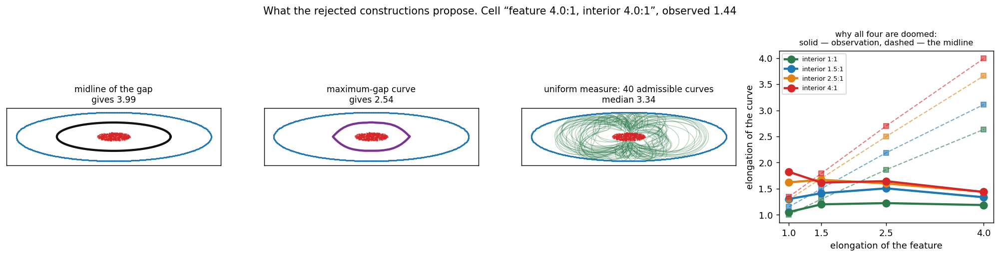

In [21]:
from scipy.stats import spearmanr
import analysis.shape_models as sm
SM = pd.read_csv("analysis/results/experiments/exp5_geometry/shape_models.csv")
MA_obs = SM[SM.block == "A"].sort_values(["feature_aspect", "interior_aspect"])
SM33 = SM[SM.block.isin(["A", "A⊥", "C"])]
SHOW = plan_A[15]                                   # f 4:1 · i 4:1
ang, r_in, r_out, centre = sm.annulus_radial(SHOW)
X, y, A = gs.dataset_points(SHOW)[:3]
hx, hy = gp.cells_extent([SHOW])

fig, axes = plt.subplots(1, 4, figsize=(15.5, 4.0))
def frame(ax, title):
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=.7, c=gp.C_INTERIOR, alpha=.5, zorder=1)
    ax.scatter(A[:, 0], A[:, 1], s=.7, c=gp.C_FEATURE, zorder=2)
    ax.set_xlim(-hx, hx); ax.set_ylim(-hy, hy); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=9.5)

def draw_radial(ax, r, **kw):
    p = centre + np.stack([r*np.cos(ang), r*np.sin(ang)], 1)
    ax.plot(*np.vstack([p, p[:1]]).T, **kw)

mid_line = .5*(r_in + r_out)          # not 'mid': that is the name of the global table of shapes
frame(axes[0], f"midline of the gap\ngives {sm.aspect_of_radial(mid_line, ang, centre):.2f}")
draw_radial(axes[0], mid_line, color="#111", lw=2.4)

xs, ys, Feq, c0 = sm.equidistant_curve(SHOW)
cu = sm.enclosing_level_curve(xs, ys, Feq, 0.0, c0)
aeq = float(gs.a2_to_aspect(np.array([fourier_descriptor(
    torch.tensor(cu, dtype=torch.float32))["amplitude"][2]]))[0])
frame(axes[1], f"maximum-gap curve\ngives {aeq:.2f}")
axes[1].plot(*np.vstack([cu, cu[:1]]).T, color="#7b3294", lw=2.4)

_, S, _ = sm.sample_annulus_curves(SHOW, n=40, seed=1)
frame(axes[2], "uniform measure: 40 admissible curves\n"
      f"median {np.median([sm.aspect_of_radial(r, ang, centre) for r in S]):.2f}")
for r in S:
    draw_radial(axes[2], r, color="#2c7a4b", lw=.7, alpha=.35)

for ia, g in MA_obs.groupby("interior_aspect"):
    g = g.sort_values("feature_aspect")
    axes[3].plot(g.feature_aspect, g.observed, "o-", color=COL[ia], lw=2.4, ms=8,
                 label=f"interior {ia:g}:1")
    axes[3].plot(g.feature_aspect, g.midline, "s--", color=COL[ia], lw=1.2, ms=5, alpha=.6)
axes[3].set_xticks([1, 1.5, 2.5, 4]); axes[3].set_xlabel("elongation of the feature")
axes[3].set_ylabel("elongation of the curve"); axes[3].legend(fontsize=7)
axes[3].set_title("why all four are doomed:\nsolid — observation, dashed — the midline",
                  fontsize=9)
fig.suptitle(f"What the rejected constructions propose. Cell “{cells_meta.loc[SHOW, 'label']}”, "
             f"observed {float(MA_obs[MA_obs.dataset_type == SHOW].observed.iloc[0]):.2f}",
             fontsize=11.5)
plt.tight_layout(); plt.show()


**What is wrong with them — in one argument, before any numbers.** All four are monotone in the shape of each
of the boundaries: elongate the feature, and the prediction elongates, at any interior. But the observed
dependence on the feature **changes sign** — with a round interior it grows (1.05 → 1.19), with an
elongated one it falls (1.82 → 1.44). The right panel shows this directly: the dashed lines diverge upwards,
the solid ones downwards. So what is excluded is not a single candidate but **the whole class "compromise between the
shapes of the two boundaries"**.

**Numbers, for the record** (the mean absolute error in elongation; the uncertainty of the predicted
numbers themselves ±0.09, the effects 0.46 and 0.14):

* the midline of the gap — **0.79**, rank correlation +0.11;
* the maximum-gap curve — **0.40**, +0.38 (p = 0.15);
* the uniform measure — **0.65**, +0.24; on top of that it gives 1.11 instead of 1.00 in the cell of two
  concentric circles: random spread is read by the descriptor as elongation;
* a fitted mixture of shapes with two to four parameters — **0.13–0.16**; it works, but this is regression, not
  geometry, and the contribution of the feature enters it with one sign, that is, it does not reproduce the change of sign
  either.

For the uniform measure the negative result turned out to be a **theorem**, not an observation: for any
measure symmetric about the midline, the average over the curves equals this line exactly, and
the average shape cannot be rounder than it (`|c₂|/c₀` is a convex function of the coefficients, then
Jensen). No averaging over the gap gives a curve rounder than the middle, while the observed ones are much
rounder. Details are in Section 10.9 of the paper.


#### (b) Dilation of the interior

The construction: the curve is the set of points at a **constant distance `δ` from the boundary of the interior**.
Not a stretching: to stretch an ellipse by a factor of 1.3 means to multiply both semi-axes, to dilate it by 0.3 means to add
0.3 to each. For a circle this is one and the same, for an ellipse these are different things, and this is exactly why dilation
**rounds**: `(a+δ)/(b+δ) → 1` monotonically in `δ`.

What the construction reproduces: the shape follows the interior (it is the interior that is dilated), but with compression; and
the more room the feature leaves, the larger `δ` and the rounder the result. What it does not reproduce:
a dilated circle is a circle for any `δ`, so with a **round** interior the model has to
give exactly 1.000 in each of the four cells, while 1.05 → 1.19 is observed. The feature enters the
construction only through `δ`, and through its shape not at all.

**Where `δ` comes from — and why the earlier answer was dishonest.** Earlier I tuned `δ` so that the
dilated curve had the same mean radius `r₀` as the observed curves of the cell. But `r₀` is a
quantity taken **from the level curves themselves**, and the level curves are defined at every value of the field;
to take their mean radius, one first has to decide which of them to describe, and this decision already
relies on the data. The model thereby peeks at the scale of what it is supposed to predict.

The honest variant uses **only the annulus**: `δ = K · (minimal width of the gap)`, where `K` is
one constant for the whole grid. The median of the observed fraction over block A gives `K = 0.45`, and after that this
number is not touched. Below are both variants, so that the difference is visible.


In [ ]:
DG = [sm.dilation_from_gap(n, 0.45) for n in plan_A]
MA_obs = MA_obs.assign(dil_geo=[d["aspect"] for d in DG], delta_geo=[d["delta"] for d in DG])

fig, axes = plt.subplots(1, 4, figsize=(15.5, 4.1))
for ax, name in zip(axes[:2], [plan_A[3], plan_A[15]]):
    meta = cells_meta.loc[name]; row = MA_obs[MA_obs.dataset_type == name].iloc[0]
    Xc, yc, Ac = gs.dataset_points(name)[:3]
    hx2, hy2 = gp.cells_extent([name])
    ax.scatter(Xc[yc == 1, 0], Xc[yc == 1, 1], s=.7, c=gp.C_INTERIOR, alpha=.5, zorder=1)
    ax.scatter(Ac[:, 0], Ac[:, 1], s=.7, c=gp.C_FEATURE, zorder=2)
    dl = gs.dilated_interior(sm.objects(name)[0], float(row.delta_geo))
    ax.plot(*np.vstack([dl, dl[:1]]).T, color="#111", lw=2.6, zorder=5)
    ax.set_xlim(-hx2, hx2); ax.set_ylim(-hy2, hy2); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"f {meta.feature_aspect:g}:1 · i {meta.interior_aspect:g}:1\n"
                 f"δ = {row.delta_geo:.2f} → {row.dil_geo:.2f}, observed {row.observed:.2f}",
                 fontsize=9)

lim = [.95, 2.6]
axes[2].plot(lim, lim, ls=":", c="k", lw=1.3)
axes[2].scatter(MA_obs.dil_geo, MA_obs.observed, s=85,
                c=[COL[f] for f in MA_obs.feature_aspect], edgecolor="white", zorder=3)
axes[2].set_xlim(lim); axes[2].set_ylim(1.0, 2.0)
axes[2].set_xlabel("dilation, δ = 0.45 · gap"); axes[2].set_ylabel("observed")
axes[2].set_title(f"Spearman {spearmanr(MA_obs.dil_geo, MA_obs.observed)[0]:+.2f}, "
                  f"error {np.abs(MA_obs.dil_geo - MA_obs.observed).mean():.3f}", fontsize=10)

for ia, g in MA_obs.groupby("interior_aspect"):
    g = g.sort_values("feature_aspect")
    axes[3].plot(g.feature_aspect, g.observed, "o-", color=COL[ia], lw=2.4, ms=8,
                 label=f"interior {ia:g}:1")
    axes[3].plot(g.feature_aspect, g.dil_geo, "s--", color=COL[ia], lw=1.2, ms=5, alpha=.65)
axes[3].set_xticks([1, 1.5, 2.5, 4]); axes[3].set_xlabel("elongation of the feature")
axes[3].set_ylabel("elongation of the curve"); axes[3].legend(fontsize=7)
axes[3].set_title("the model catches the fall along the feature axis,\nthe rise at a round interior — not",
                  fontsize=9)
fig.suptitle("Dilation of the interior, δ taken from the gap and knowing nothing of the curves", fontsize=11.5)
plt.tight_layout(); plt.show()


def cell_uncertainty(names, n_boot=400, seed=0):
    """Half-width of the 95% bootstrap of the median elongation of a cell — resampling NETWORKS.

    This is the accuracy with which the predicted number is known at all, and it
    is against it that the error of a construction must be read. "Always name the
    median over the grid" cannot be a baseline here: what is predicted is not a
    single neuron but a population quantity of the cell, and a constant fitted to
    the same sixteen answers is not a null model but an oracle.
    """
    rng = np.random.default_rng(seed)
    out = []
    for name in names:
        g = hl[(hl.dataset_type == name) & (hl.layer_id > 0)]
        by = {m: v.aspect.to_numpy() for m, v in g.groupby("model_index")}
        keys = list(by)
        b = [np.median(np.concatenate([by[keys[i]]
                                       for i in rng.choice(len(keys), len(keys), True)]))
             for _ in range(n_boot)]
        lo, hi = np.percentile(b, [2.5, 97.5])
        out.append((hi - lo) / 2)
    return np.array(out)


U_A = cell_uncertainty(plan_A)
print(f"SCALE. what is predicted is the median of a cell; it is itself known to within "
      f"±{np.median(U_A):.2f} (across cells {U_A.min():.2f}–{U_A.max():.2f}),")
print(f"       across the grid it spans {MA_obs.observed.max() - MA_obs.observed.min():.2f}, "
      f"effect of the interior 0.46, effect of the feature 0.14")
for col, lab in (("dil_geo", "dilation, δ = 0.45 · gap (the annulus only)"),
                 ("dilation", "dilation, δ fitted to the observed r₀")):
    print(f"  {lab:44s} Spearman {spearmanr(MA_obs[col], MA_obs.observed)[0]:+.3f}  "
          f"error {np.abs(MA_obs[col]-MA_obs.observed).mean():.3f}")
print(f"\non the 33 concentric cells (A, A⊥, C): dilation with fitted δ — "
      f"{np.abs(SM33.dilation-SM33.observed).mean():.3f}")


**Observations.**

- **Dilation catches the direction of the dependences well**: rank correlation +0.87, and the right panel
  shows that it reproduces the drop in elongation along the feature axis (with an elongated interior).
- **But as a prediction of magnitude it does not work.** The mean error **0.238** is twice as far as for
  the potential, more than twice the uncertainty of the numbers themselves and half of the effect of the interior,
  so the weaker effect of the feature (0.14) it does not resolve at all. On the 33 concentric cells
  the picture is the same (0.31–0.37).
- **The systematics of the error are understandable and not random.** With a round interior the model has to give
  exactly 1.000 against the observed 1.05–1.23 — the feature takes no part in the construction. With an elongated one it
  overestimates (2.45 against 1.82). The first is a structural defect, the second a consequence of the fact that for
  dilation the elongation decreases as `1/δ`, too slowly.
- Tuning `δ` to the observed `r₀` hardly changes the numbers (0.242 against 0.238): the matter is not the way of
  calibration but the construction itself.

**Summary of (b).** Dilation is a good **intuition**: one phrase explains "the shape comes from the interior",
"but rounder", and "the more room, the rounder". As a quantitative model it is insufficient.


#### (c) Harmonic potential

A construction from potential theory. Take the two objects as the plates of a capacitor and solve the Dirichlet
problem

$$\Delta u = 0 \ \text{in the gap},\qquad u = 0 \ \text{on the interior},\qquad u = 1 \ \text{on the feature}.$$

The candidate for the level curve of a neuron is a level curve of `u`. No shape parameters: `u`
is determined **by the pair of objects alone**.

Three properties that the previous candidates do not have:

1. **both boundaries take part** — so the effect of the feature can change sign rather than only grow;
2. **asymmetry**: the line at `u = 0.4` is noticeably closer to the interior than to the feature — exactly what
   the theorem from part (a) requires of any working construction;
3. **the right rate of rounding**: in the field of a conductor the `k`-th multipole decays as `r^{−k}`,
   so the elongation (a quadrupole, `1/r²`) disappears twice as fast as the size. For dilation the elongation
   falls only as `1/δ`, which is why it overestimates.

The level is fixed: `u = 0.40`, one constant for the whole grid, nothing is taken from the data.


In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(15.5, 4.3))
for ax, name in zip(axes[:3], [plan_A[0], plan_A[3], plan_A[15]]):
    meta = cells_meta.loc[name]; row = MA_obs[MA_obs.dataset_type == name].iloc[0]
    interior, _, c0 = sm.objects(name)
    xs, ys, F, step = sm.harmonic_potential(name)
    Xg, Yg = np.meshgrid(xs, ys, indexing="ij")
    ax.contourf(Xg, Yg, np.nan_to_num(F, nan=1.0), levels=np.linspace(0, 1, 21),
                cmap="RdBu_r", alpha=.55, zorder=0)
    for lv, c_ in zip((.2, .6, .8), plt.cm.viridis(np.linspace(.15, .8, 3))):
        cu = sm.enclosing_level_curve(xs, ys, F, lv, c0)
        if cu is not None:
            ax.plot(*np.vstack([cu, cu[:1]]).T, color=c_, lw=1.6,
                    label=f"u = {lv:g}" if ax is axes[0] else None)
    cu = sm.enclosing_level_curve(xs, ys, F, 0.40, c0)
    if cu is not None:
        ax.plot(*np.vstack([cu, cu[:1]]).T, color="#111", lw=2.8, zorder=6,
                label="u = 0.40" if ax is axes[0] else None)
    hx2, hy2 = gp.cells_extent([name])
    ax.set_xlim(-hx2, hx2); ax.set_ylim(-hy2, hy2); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"f {meta.feature_aspect:g}:1 · i {meta.interior_aspect:g}:1\n"
                 f"{row.harmonic_fixed:.2f} against {row.observed:.2f}", fontsize=9)
axes[0].legend(fontsize=7, loc="upper right")

for ia, g in MA_obs.groupby("interior_aspect"):
    g = g.sort_values("feature_aspect")
    axes[3].plot(g.feature_aspect, g.observed, "o-", color=COL[ia], lw=2.4, ms=8,
                 label=f"interior {ia:g}:1")
    axes[3].plot(g.feature_aspect, g.harmonic_fixed, "s--", color=COL[ia], lw=1.2, ms=5, alpha=.65)
axes[3].set_xticks([1, 1.5, 2.5, 4]); axes[3].set_xlabel("elongation of the feature")
axes[3].set_ylabel("elongation of the curve"); axes[3].legend(fontsize=7)
axes[3].set_title("the model catches the rise at a round interior,\nthe fall — not", fontsize=9)
fig.suptitle("Equilibrium potential of the pair; background — the potential itself, from 0 at the interior to 1 at the feature",
             fontsize=11.5)
plt.tight_layout(); plt.show()

rows = []
for col, lab in (("midline", "midline"), ("uniform", "uniform measure"),
                 ("dil_geo", "dilation, δ from the gap"),
                 ("harmonic_fixed", "potential, u = 0.40")):
    g = MA_obs.dropna(subset=[col])
    rows.append(dict(model=lab, Spearman=spearmanr(g[col], g.observed)[0],
                     error=float(np.abs(g[col]-g.observed).mean())))
print("block A, everything without a single number from the data:")
print(pd.DataFrame(rows).round(3).to_string(index=False))
g33 = SM33.dropna(subset=["harmonic_fixed"])
print(f"\non the 33 concentric: potential u = 0.40 — error "
      f"{np.abs(g33.harmonic_fixed-g33.observed).mean():.3f}")


**Is it better than dilation — and in what sense.** The statement has to be split, because the two metrics
give different answers, and choosing the convenient one would be dishonest.

* **In accuracy — yes, twofold.** The mean error is **0.119** against 0.238 for dilation on block A. This is
  only slightly more than the uncertainty of the predicted numbers themselves (±0.09) and four times less than the
  effect of the interior — but still of the order of the effect of the feature, that is, the weaker of the two
  dependences the potential does not resolve. On the 33 concentric cells — 0.222 against 0.373.
* **In ordering — no.** Rank correlation +0.78 against +0.87 for dilation: dilation puts the cells
  in the right order better.
* **In reproducing the observations — they complement each other.** Only the potential gives
  the **rise** of elongation along the feature axis with a round interior (1.00 → 1.23 against the observed
  1.05 → 1.19), which is inaccessible to dilation by construction. Only dilation gives a noticeable
  **fall** along the same axis with an elongated interior. **No model gives both halves
  together**, and this is the main open residue.

**What follows from this and what does not.** It follows that the observed shape of the level curve in
concentric configurations is reproduced to within 0.12 by a geometric construction that
has no shape parameters at all. It does not follow that the network computes this construction, that the field of the
neuron is harmonic, that this is the cause. It is about the **agreement** of two quantities, and an
experiment without ablation cannot say more.


#### (d) A ceiling hypothesis: how this could be assembled into one picture

All three parts above are about individual constructions. It is worth spelling out the reading that
unites them, and saying honestly what in it has been tested and what has not.

> **The curves by themselves gravitate towards the shape of a circle.** The shape of the interior can influence them —
> but this influence is not direct: it is the stronger, the less freedom the curve has, that is, the more tightly
> the interior props up the feature. The feature itself meanwhile works not as a source of shape but as a **hard
> ceiling**: as long as it does not get in the way, its shape influences almost nothing; as soon as it starts to
> get in the way, it becomes the main thing.

What of this **is confirmed by measurements**:

* **"Gravitate towards a circle" — yes.** Only about **40%** of the elongation of the interior passes through the curve
  (median 0.41 over the concentric cells, Section 10.7 of the paper), and the
  observed shape always lies between the circle and the shape of the interior — in 27 cells of 27.
* **"It is the interior that influences" — yes, and this is proved by direction.** In block B, where the objects are
  turned relative to each other, the curve runs along the interior in 0.57–0.96 of cases against
  0.02–0.34 along the feature.
* **"The feature is a ceiling, not a source of shape" — yes, and this is the most testable part.** In blocks A, B and
  C a round curve always separates the classes, that is, the ceiling nowhere gets in the way — and the shape of the feature there
  explains practically nothing (the aspect of the midline, which follows both objects, gives
  Spearman +0.12). In the six cells of block D where the concentric circle stops separating,
  that is, where the ceiling starts to get in the way, the curves elongate to **3.54 against 1.60** in the other
  fifty. The ceiling is silent until it is hit, and becomes decisive once it is.

What is **not tested**:

* **"The stronger, the less freedom."** This is the most substantive part of the hypothesis, and on our
  grid it cannot be tested. All dimensionless measures of freedom give a correlation of the right sign
  (−0.40…−0.50), but they are coupled with the elongation of the interior at +0.68…+0.79 — the design elongates the
  interior at a fixed major semi-axis, so freedom and shape change together. With
  elongation controlled for, the link disappears (−0.10…−0.22, p > 0.26). An axis is needed that changes the **size**
  of the interior at an unchanged **shape**; it exists in the plan (`interior_scale`), but it is used
  only in block D and is mixed with the offset there.

**In sum.** The hypothesis agrees with everything that has been measured, and in two of its three parts it is confirmed
directly. Its central link — the dependence of the influence on freedom — remains **untested** rather than
confirmed, and testing it needs a small new series of cells.


#### Where geometry does force: a control from block D

All three parts above are about concentric pairs, where a round solution is available. It is useful to look at
the only place in the experiment where it is **not available**.

If the separating circle is required to be **concentric with the feature**, it stops
fitting in exactly **6 cells of 56** — all in block D, where the interior is shifted along the long
axis. The median elongation of the curves there is **3.54** against **1.60** in the other fifty, and the
ranges do not overlap.

This is not a model but a check of the sensitivity of the measurement: where a round solution really is
unavailable, the curves really do elongate — four times more strongly. So the observed roundness in
the other cells is not an artefact of the instrument. These six cells themselves, however, are not described by any of the
three constructions — the analysis is in block D and in Section 10.9 of the paper.


### Summary of 2.2

**The observed.**

1. The curve is rounder than both objects: the median across cells 1.05–1.85 with objects 1–4.
2. It is moved by the interior (range of the marginal effect 0.46, monotone), not by the feature (0.14,
   non-monotone).
3. The effect of the feature **changes sign**: with a round interior it adds elongation, with an elongated one it
   subtracts. With a caveat: along this axis not only the shape of the feature changes but also the **relative
   size** of the objects (the area of the feature grows fourfold), that is, also the amount of free room. Both
   halves of this point are compatible with the reading "more freedom — rounder", and the readings cannot be separated on
   this grid.
4. The distribution of elongation is not unimodal in 9 cells of 16, and a group above aspect 2
   exists with a weight from 0% to 34%; whether this is a population or junk is decided in 2.3.

**Models that describe this** (all computed from the geometry of the pair alone; the mean absolute
error in elongation, to be read against the ±0.09 uncertainty of the numbers themselves and against the effects 0.46 and
0.14):

| construction | error | what is wrong |
|---|---|---|
| midline of the gap | 0.79 | monotone in both boundaries, does not change sign |
| maximum-gap curve | 0.40 | the same |
| uniform measure on admissible curves | 0.65 | theorem: cannot be rounder than the middle |
| dilation of the interior | 0.24 | twice as far as the potential; with a round interior gives exactly 1 |
| **harmonic potential, u = 0.40** | **0.12** | does not reproduce the fall along the feature axis |

No construction reproduces **both** halves of point 3. None of them is a
statement about a cause: there is no ablation, and everything said is about the agreement of two quantities.


## 2.3 The elongated group: a population or outliers

2.2 shows that above aspect 2 lies a noticeable fraction of curves — up to a third in some cells — and
that a test for modes by itself says nothing about this group. So the question has to be put squarely:
**is this a population or junk?**

The difference is not verbal. If it is a population, the network has two different ways of encircling
the interior, and the conclusion "the curve gravitates towards a round one" describes only the larger of them. If these are
outliers — rare unlucky neurons, noise of the contour extraction, neurons with almost zero amplitude,
for which "elongation" means nothing — then they should simply be filtered out and forgotten.

The section is organised as follows: first we look at the **extreme** neurons of each model, then we test the group
in four independent ways.

### 2.3.1 The most elongated neurons of each model

**Why exactly the maximum per model.** It is the same protocol by which everything else in the
section is computed: the unit of observation is the model, the value is its extreme neuron. It gives ≤ 50 points per
rung instead of 500, that is, each point is a separate network, not one network counted twenty
times. At the same time it is a direct answer to the question of what a model is **capable of**, not "what it usually does".

**What else could have been taken, and why it was not.** The top 5% of all curves of a cell are simply the
tail of the same distribution, cut off by a threshold: it cannot answer whether there is a population there or not, it
is itself the part being asked about. That is why a **different** selection is put alongside for comparison:
the neuron **best by structural score**, that is, the one whose curve the criterion recognised as closest to the
feature. If the elongated neurons are junk, there should be none of them among the best by score.

The histograms show three distributions on one axis: all neurons, the most elongated per model, the best
by score per model. All three are normalised to area, so that they can be compared at different n.


curves in total 39718; most elongated per (model, rung) 3519; best by score per model 798


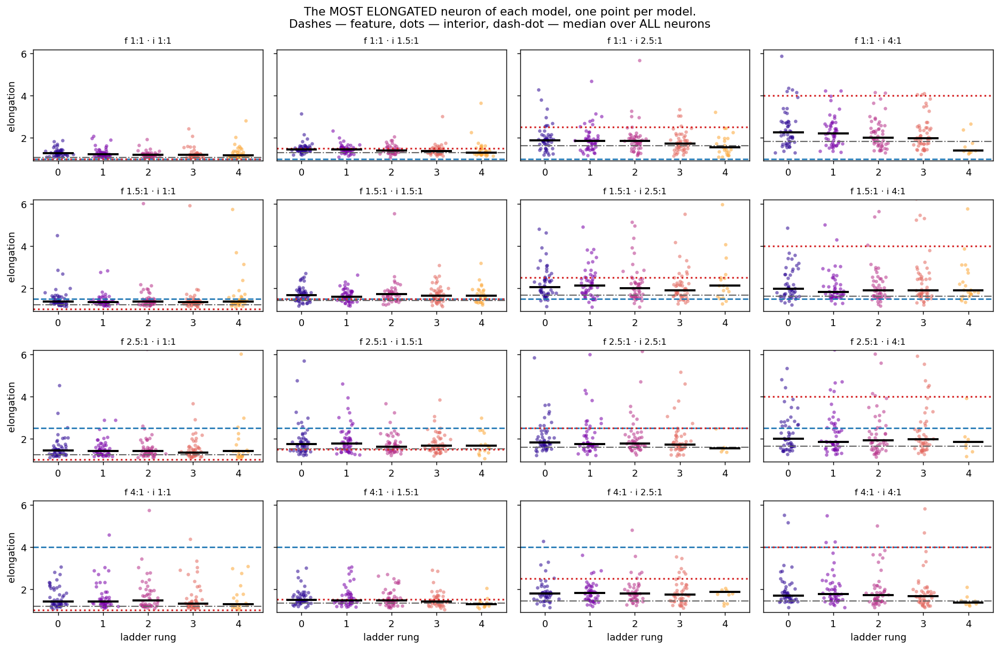

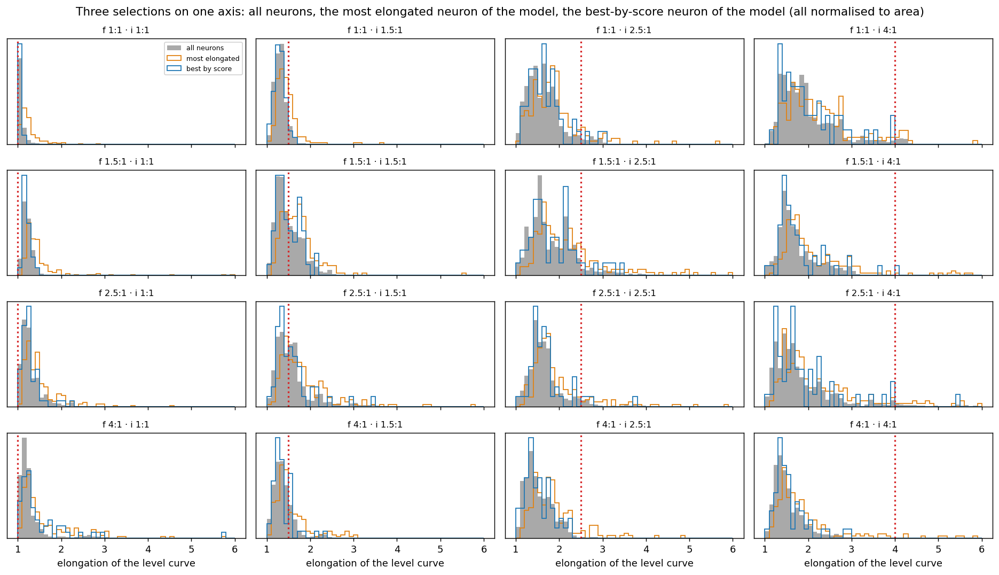


median elongation across cells: all neurons 1.05–1.82; most elongated neuron of the model 1.20–2.09; best-by-score neuron of the model 1.03–1.82
the best by score differs from the typical one by 0.022 — that is, by nothing


In [24]:
imap = gs.model_index_map(plan_A)
tgtA = df[(df.feature_role == "target") & (df.block == "A") & (df.layer_id > 0)].copy()
tgtA["model_path"] = tgtA.model_path.astype(str)
joined = (sub.merge(imap, on=["dataset_type", "model_index"])
             .merge(tgtA[["dataset_type", "model_path", "layer_id", "coord_id", gs.SCORE]]
                    .rename(columns={gs.SCORE: "score"}),
                    on=["dataset_type", "model_path", "layer_id", "coord_id"], how="left"))
top = joined.loc[joined.groupby(["dataset_type", "model_index", "rung"]).aspect.idxmax()]
mid_j = joined[joined.rung == 2].dropna(subset=["score"])
bysc = mid_j.loc[mid_j.groupby(["dataset_type", "model_index"]).score.idxmin()]
print(f"curves in total {len(sub)}; most elongated per (model, rung) {len(top)}; "
      f"best by score per model {len(bysc)}")

fig, axes = plt.subplots(4, 4, figsize=(14.5, 9.5), sharey=True)
rng = np.random.default_rng(3)
for ax, name in zip(axes.flat, plan_A):
    meta = cells_meta.loc[name]
    g = top[top.dataset_type == name]
    allm = sub[sub.dataset_type == name].aspect.median()
    for j in range(5):
        v = g[g.rung == j].aspect
        if not len(v):
            continue
        ax.scatter(rng.normal(j, .10, len(v)), v, s=13, alpha=.55, color=ramp[j], linewidths=0)
        ax.plot([j-.32, j+.32], [v.median()]*2, color="k", lw=2.2, zorder=5)
    ax.axhline(allm, color="#666", lw=1.2, ls="-.")
    ax.axhline(meta.feature_aspect, color=gp.C_FEATURE, ls="--", lw=1.5)
    ax.axhline(meta.interior_aspect, color=gp.C_INTERIOR, ls=":", lw=1.8)
    ax.set_xticks(range(5)); ax.set_ylim(.9, 6.2)
    ax.set_title(f"f {meta.feature_aspect:g}:1 · i {meta.interior_aspect:g}:1", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("ladder rung")
for ax in axes[:, 0]:
    ax.set_ylabel("elongation")
fig.suptitle("The MOST ELONGATED neuron of each model, one point per model.\n"
             "Dashes — feature, dots — interior, dash-dot — median over ALL neurons",
             fontsize=12)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(4, 4, figsize=(14.5, 8.4), sharex=True)
bins = np.linspace(1, 6, 51)
for ax, name in zip(axes.flat, plan_A):
    meta = cells_meta.loc[name]
    ax.hist(sub[sub.dataset_type == name].aspect, bins=bins, color="#9a9a9a",
            density=True, alpha=.85, label="all neurons")
    ax.hist(top[top.dataset_type == name].aspect, bins=bins, density=True,
            histtype="step", lw=2.0, color="#e08214", label="most elongated")
    ax.hist(bysc[bysc.dataset_type == name].aspect, bins=bins, density=True,
            histtype="step", lw=2.0, color=gp.C_FEATURE, label="best by score")
    ax.axvline(meta.interior_aspect, color=gp.C_INTERIOR, ls=":", lw=1.8)
    ax.set_yticks([])
    ax.set_title(f"f {meta.feature_aspect:g}:1 · i {meta.interior_aspect:g}:1", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("elongation of the level curve")
axes[0, 0].legend(fontsize=7)
fig.suptitle("Three selections on one axis: all neurons, the most elongated neuron of the model, "
             "the best-by-score neuron of the model (all normalised to area)", fontsize=12)
plt.tight_layout(); plt.show()

med_all = sub.groupby("dataset_type").aspect.median()
med_top = top.groupby("dataset_type").aspect.median()
med_sc = bysc.groupby("dataset_type").aspect.median()
print(f"\nmedian elongation across cells: all neurons "
      f"{med_all.min():.2f}–{med_all.max():.2f}; most elongated neuron of the model "
      f"{med_top.min():.2f}–{med_top.max():.2f}; best-by-score neuron of the model "
      f"{med_sc.min():.2f}–{med_sc.max():.2f}")
print(f"the best by score differs from the typical one by "
      f"{np.abs(med_sc - med_all).median():.3f} — that is, by nothing")


**Observations.**

- **The extreme neuron of each model is noticeably more elongated than the typical one, but not radically.** The median
  of the most elongated neuron runs **1.20 … 2.09** across cells against **1.05 … 1.85** for all
  neurons: the shift is present everywhere, it is of the order of 0.15–0.30 and grows together with the interior.
- **The top 5% and "the most elongated per model" are different things, and the difference is instructive.**
  The 95th percentile over all curves of a cell runs 1.23 … 3.94, that is, it is systematically higher. This is not a
  contradiction: the percentile cuts the pooled sample of ~2,500 curves and takes its top 125,
  while the second selection takes the median of 250 extrema, one from each pair (model, rung).
  The first answers "what the top of the cell looks like", the second "what an individual network is capable of",
  and the question about a population needs the second: it guarantees one point from each network, whereas the percentile could
  consist entirely of the curves of five lucky models.
- **The best-by-score neuron is indistinguishable in shape from the typical one** — the medians coincide to the
  second digit. This looks suspicious (as if the criterion were blind to shape), and it turns out to be
  just that: 2.3.2 shows that within a cell it is in fact **most sensitive** to shape,
  it just prefers round curves at a round feature and elongated ones at an elongated one, and averaging over the
  grid cancels these two preferences. What really follows from here is that the elongated group is not
  a reject: it is neither selected nor discarded systematically.
- **Almost nobody reaches the shape of an elongated feature.** In the bottom row (the feature is 4:1) the fraction of
  models whose most elongated neuron reaches aspect 4 equals **0.04 · 0.01 · 0.08 ·
  0.07**. In the top row (the feature is a circle) it is, of course, exceeded by all 100%.
- **Careful with the maximum.** The maximum over a cell itself runs into the ceiling of the scale (14:1) in
  nine cells of sixteen: these are curves whose `a₂` is larger than any ellipse has, and
  "the ratio of the axes" is no longer defined for them. That is why what is read here is **the median of the extrema**, not
  the extremum.


### 2.3.2 Four checks

The pictures showed that the group exists. Now four independent ways of telling a population from
junk; each could fail separately.

**1. Do the elongated curves cluster by model.** If this is extraction noise, the elongated curves are
scattered evenly over the models and their number per model behaves binomially. If it is a
property of the network, some models give many of them, others none, and the variance will be larger than
binomial. The measure is **overdispersion**: the observed variance of the number per model divided by
the binomial one at the same fraction. One means like a coin; much more means clustering.

**2. A property of the neuron or of the rung.** A neuron has up to five rungs. If elongation is an
accident of extraction, one rung of five will be elongated. If it is the shape of the family,
all of them will be. The fraction of neurons elongated **on all** of their rungs is computed and compared
with what independent tossing would give at the same overall fraction.

**3. Does the elongation have a direction.** An accidentally elongated curve points anywhere:
the fraction "along" would be about 1/3. A genuine response to the geometry of the pair points along the common axis of the
objects. The elongated group and the moderate one are compared.

**4. Does this group mean anything for the task.** We have no ablation, so "means" here
is the structural score: do the elongated curves come closer to the feature than the others or further, and in which
cells.


1. do elongated curves cluster by model (overdispersion; 1 = as for a coin)
 feature  interior  fraction  models  overdispersion  models_with_none
     1.0       1.0     0.000      50             NaN              1.00
     1.0       1.5     0.002      49            1.01              0.98
     1.0       2.5     0.137      49            7.38              0.71
     1.0       4.0     0.340      48            7.82              0.50
     1.5       1.0     0.005      50            0.96              0.94
     1.5       1.5     0.069      48           10.20              0.81
     1.5       2.5     0.320      50            9.46              0.50
     1.5       4.0     0.241      50            8.91              0.56
     2.5       1.0     0.033      50            6.10              0.86
     2.5       1.5     0.136      49           11.75              0.76
     2.5       2.5     0.176      49           11.57              0.67
     2.5       4.0     0.300      50           10.88              0.54
 


2. property of the neuron or of the rung (neurons with >= 3 rungs: 9377)
   elongated on ALL its rungs:      0.110
   elongated on none:               0.833
   mixed answer:                    0.057
   with independent rungs 'all' would be expected at 0.0003, observed 0.110 — 399 times more

3. does the elongation have a direction
   elongated (aspect > 2)   n =   5198   along 0.961   across 0.007   (chance would give 0.33 and 0.33)
   moderate (1.22–2)        n =  24045   along 0.872   across 0.025   (chance would give 0.33 and 0.33)

4. does the group mean anything for the task: median structural score
                moderate  elongated  difference
feature_aspect                                 
1.0                0.058      0.122       0.064
1.5                0.060      0.086       0.025
2.5                0.095      0.082      -0.013
4.0                0.138      0.102      -0.036


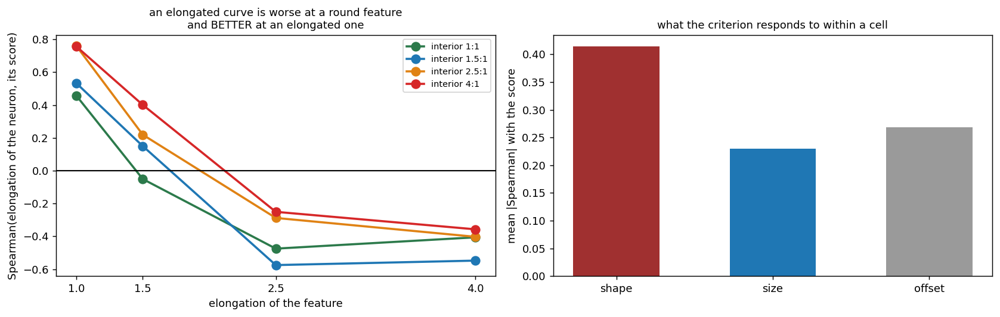

mean |Spearman| of the score: with shape 0.41, with size 0.23, with offset 0.27
sign of the link with shape: positive in 7 cells (round feature), negative in 9 (elongated)

   fraction of elongated:
                among all neurons  among the best by score
feature_aspect                                            
1.0                         0.115                    0.140
1.5                         0.159                    0.171
2.5                         0.164                    0.176
4.0                         0.080                    0.100


In [25]:
from scipy.stats import spearmanr
one = sub[sub.rung == 2].copy(); one["hi"] = one.aspect > 2
rows = []
for name in plan_A:
    g = one[one.dataset_type == name]
    per = g.groupby("model_index").hi.agg(["sum", "size"])
    per = per[per["size"] >= 5]
    p = float(g.hi.mean())
    od = (per["sum"].var(ddof=1) / max((per["size"]*p*(1-p)).mean(), 1e-9)
          if 0 < p < 1 and len(per) >= 10 else np.nan)
    rows.append(dict(feature=cells_meta.loc[name, "feature_aspect"],
                     interior=cells_meta.loc[name, "interior_aspect"],
                     fraction=round(p, 3), models=len(per), overdispersion=round(od, 2)
                     if od == od else np.nan,
                     models_with_none=round(float((per["sum"] == 0).mean()), 2)))
OD = pd.DataFrame(rows)
print("1. do elongated curves cluster by model (overdispersion; 1 = as for a coin)")
print(OD.to_string(index=False))

w = sub.pivot_table(index=["dataset_type", "model_index", "layer_id", "coord_id"],
                    columns="rung", values="aspect")
w = w[w.notna().sum(axis=1) >= 3]
hi = (w > 2); n_have = w.notna().sum(axis=1); frac = hi.sum(axis=1) / n_have
p_hi = float(hi.sum().sum() / n_have.sum())
exp_all = p_hi ** float(n_have.mean())
print(f"\n2. property of the neuron or of the rung (neurons with >= 3 rungs: {len(w)})")
print(f"   elongated on ALL its rungs:      {(frac == 1).mean():.3f}")
print(f"   elongated on none:               {(frac == 0).mean():.3f}")
print(f"   mixed answer:                    {((frac > 0) & (frac < 1)).mean():.3f}")
print(f"   with independent rungs 'all' would be expected at {exp_all:.4f}, "
      f"observed {(frac == 1).mean():.3f} — {(frac == 1).mean()/max(exp_all,1e-9):.0f} times more")

g2 = sub[sub.a2 >= 0.10]
print("\n3. does the elongation have a direction")
for lab, sel in (("elongated (aspect > 2)", g2.aspect > 2), ("moderate (1.22–2)", g2.aspect <= 2)):
    a = g2[sel].angle2.values
    print(f"   {lab:24s} n = {len(a):6d}   along {((a < 30) | (a > 150)).mean():.3f}   "
          f"across {((a > 60) & (a < 120)).mean():.3f}   (chance would give 0.33 and 0.33)")

jm = joined[joined.rung == 2].dropna(subset=["score"]).copy(); jm["hi"] = jm.aspect > 2
print("\n4. does the group mean anything for the task: median structural score")
piv = jm.pivot_table(index="feature_aspect", columns="hi", values="score", aggfunc="median")
piv.columns = ["moderate", "elongated"]
piv["difference"] = piv["elongated"] - piv["moderate"]
print(piv.round(3).to_string())
rho = []
for name, g in jm.groupby("dataset_type"):
    m = cells_meta.loc[name]
    rho.append(dict(dataset_type=name, feature=m.feature_aspect, interior=m.interior_aspect,
                    by_shape=spearmanr(g.aspect, g["score"])[0],
                    by_size=spearmanr(g.r0, g["score"])[0],
                    by_offset=spearmanr(np.hypot(g.cx, g.cy), g["score"])[0]))
rho = pd.DataFrame(rho)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ia, g in rho.groupby("interior"):
    g = g.sort_values("feature")
    axes[0].plot(g.feature, g.by_shape, "o-", color=COL[ia], lw=2.0, ms=8,
                 label=f"interior {ia:g}:1")
axes[0].axhline(0, color="k", lw=1.2)
axes[0].set_xticks([1, 1.5, 2.5, 4]); axes[0].set_xlabel("elongation of the feature")
axes[0].set_ylabel("Spearman(elongation of the neuron, its score)")
axes[0].legend(fontsize=8)
axes[0].set_title("an elongated curve is worse at a round feature\nand BETTER at an elongated one",
                  fontsize=10)
axes[1].bar(range(3), [rho.by_shape.abs().mean(), rho.by_size.abs().mean(),
                       rho.by_offset.abs().mean()],
            color=[gp.C_BAD, gp.C_FEATURE, gp.C_NULL], width=.55)
axes[1].set_xticks(range(3), ["shape", "size", "offset"])
axes[1].set_ylabel("mean |Spearman| with the score")
axes[1].set_title("what the criterion responds to within a cell", fontsize=10)
plt.tight_layout(); plt.show()

print(f"mean |Spearman| of the score: with shape {rho.by_shape.abs().mean():.2f}, "
      f"with size {rho.by_size.abs().mean():.2f}, "
      f"with offset {rho.by_offset.abs().mean():.2f}")
print(f"sign of the link with shape: positive in {int((rho.by_shape > 0).sum())} cells "
      f"(round feature), negative in {int((rho.by_shape < 0).sum())} (elongated)")

share = pd.DataFrame({
    "among all neurons": jm.groupby("feature_aspect").hi.mean(),
    "among the best by score": bysc.assign(hi=lambda d: d.aspect > 2)
                                 .groupby("feature_aspect").hi.mean()})
print("\n   fraction of elongated:")
print(share.round(3).to_string())


**Observations.**

1. **The elongated curves cluster strongly by model.** Where the group has weight, the overdispersion is
   **5–12**: some networks give elongated curves in batches, others none (the fraction of models without a single one
   reaches 0.7 at an overall fraction of 0.14). And in the two cells where there is practically no group
   (fraction 0.002 and 0.005), the overdispersion equals **0.96 and 1.01** — exactly one. This is an internal
   control of the measure itself: it gives one where there is nothing to cluster, and does not where there is.
2. **This is a property of the neuron, not of the rung.** **11.0%** of neurons are elongated on **all** their
   rungs against the **0.03%** expected with independent rungs — **400 times** more.
   Only 5.7% give a mixed answer. A neuron either draws an elongated family in full or does not
   draw one at all.
3. **The elongation has a direction, and in the elongated group it is sharper.** The fraction "along" is
   **0.961** for the elongated against 0.872 for the moderate, across 0.007 against 0.025. Random
   directions would give 0.33. Junk does not behave like this.
4. **The group is meaningful for the task, and the sign of the effect changes exactly where it should.** The median
   structural score of the elongated is **worse** at a round feature (0.122 against 0.058) and **better** at an
   elongated one (0.102 against 0.138 at 4:1). Within a cell the same is seen, and more strongly: the link of the score
   with the **shape** of the neuron is positive (elongated is worse) in 7 cells — all with a round or almost
   round feature — and negative (elongated is better) in 9, where the feature is elongated.

   This, by the way, removes the suspicious statement from 2.3.1 that "the criterion selects neither
   round curves nor elongated ones". It does select, and strongly: **the mean |Spearman| of the score with shape is 0.41**
   against 0.23 with size and 0.27 with offset — shape matters more to the criterion than both. It simply
   prefers **different things in different cells**, and when averaged over the grid the two opposite
   preferences cancel each other, leaving the appearance of indifference. The median over a row does not
   catch this, because within a row an elongated feature both raises the reward for an elongated
   curve and makes such curves rare.

**Conclusion. This is a population, not outliers.** Four independent checks agree: the elongated curves
cluster by network, hold through the whole family of levels of one neuron, are oriented along the common
axis of the objects and behave meaningfully with respect to the task. So the network has **two ways**
of encircling the interior, and the conclusion of section 2.2 should be read as a statement about the **larger** of them:
a typical neuron draws an almost round curve, and a minority a stably elongated one, and this
minority is the more numerous, the more elongated the interior.

**What this check does not give.** It does not say **why** the network has a second way — for that an
ablation is needed, which the programme does not have. And it does not separate "two mechanisms" from "one mechanism with
two stable states": both pictures would give the same statistics.


### 2.3.3 What is special about the networks that draw elongated curves

The overdispersion from check 1 says that the elongated curves **cluster by network**: some models
give them in batches, others none. This in itself raises a question — how do such networks
differ? There are three possible answers, and they can be told apart.

* **They are trained worse.** Then the fraction of elongated curves should grow for models that needed
  more epochs, and fall for those that learned fast.
* **They solve the task worse.** Then it should correlate with the structural score of the model —
  the elongated networks should be those whose best neuron is further from the feature.
* **They place the curves elsewhere.** Then it should correlate with the **size** of the model's curves:
  by the dilation law from 2.2.3 the curve is the rounder, the larger `δ`, and `δ` is seen as `r₀`. A network
  whose level curves are pressed against the interior has to draw more elongated curves — not because
  it is worse, but because that is how the geometry of dilation works.

The unit of observation is the model; the quantity is the fraction of its neurons with elongation above 2 on the middle
rung. The link is computed **within a cell**, so that the geometry of the cell does not substitute itself for the answer.


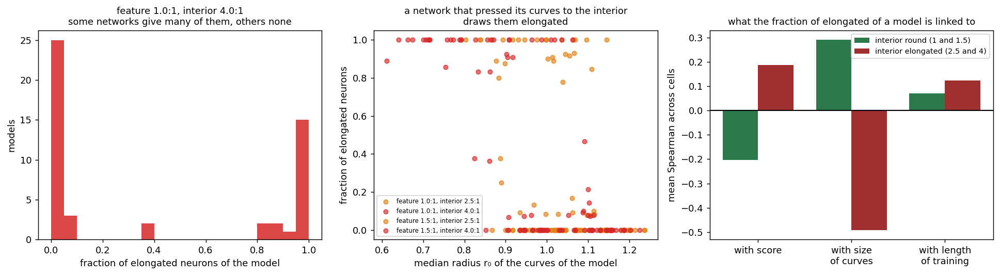

interior round (1 and 1.5): with score -0.20, with size of curves +0.29, with length of training +0.07
interior elongated (2.5 and 4): with score +0.19, with size of curves -0.49, with length of training +0.12
feature round (1 and 1.5): with score +0.37, with size of curves -0.38, with length of training +0.20
feature elongated (2.5 and 4): with score -0.32, with size of curves +0.10, with length of training +0.01

the link with the length of training does not exceed noise in any cell: |rho| from 0.06 to 0.43, median 0.15


In [26]:
per = (jm.groupby(["dataset_type", "model_path"])
         .agg(fraction=("hi", "mean"), best_score=("score", "min"),
              median_r0=("r0", "median"), neurons=("hi", "size")).reset_index())
ep = (df[(df.feature_role == "target") & (df.block == "A")]
      .assign(model_path=lambda d: d.model_path.astype(str))
      .groupby(["dataset_type", "model_path"]).train_stopped_epoch.first().rename("epochs"))
per = per.merge(ep, on=["dataset_type", "model_path"])

rows = []
for name, g in per.groupby("dataset_type"):
    if g.fraction.std() == 0:
        continue
    m = cells_meta.loc[name]
    rows.append(dict(dataset_type=name, feature=m.feature_aspect, interior=m.interior_aspect,
                     with_score=spearmanr(g.fraction, g.best_score)[0],
                     with_size=spearmanr(g.fraction, g.median_r0)[0],
                     with_epochs=spearmanr(g.fraction, g.epochs)[0]))
CR = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
BIG = plan_A[3]                                   # feature round, interior 4:1
g = per[per.dataset_type == BIG]
axes[0].hist(g.fraction, bins=np.linspace(0, 1, 21), color=COL[4.0], alpha=.85)
axes[0].set_xlabel("fraction of elongated neurons of the model"); axes[0].set_ylabel("models")
axes[0].set_title(f"{cells_meta.loc[BIG, 'label']}\nsome networks give many of them, others none",
                  fontsize=10)

for name, gg in per[per.dataset_type.isin(plan_A[2:4] + plan_A[6:8])].groupby("dataset_type"):
    axes[1].scatter(gg.median_r0, gg.fraction, s=22, alpha=.65,
                    color=COL[cells_meta.loc[name, "interior_aspect"]],
                    label=cells_meta.loc[name, "label"])
axes[1].set_xlabel("median radius r₀ of the curves of the model")
axes[1].set_ylabel("fraction of elongated neurons")
axes[1].legend(fontsize=6.5)
axes[1].set_title("a network that pressed its curves to the interior\ndraws them elongated", fontsize=10)

x = np.arange(3); wdt = .38
SPLIT = [("interior round (1 and 1.5)", CR.interior <= 1.5),
         ("interior elongated (2.5 and 4)", CR.interior > 1.5)]
for k, (lab, sel) in enumerate(SPLIT):
    vals = [CR[sel].with_score.mean(), CR[sel].with_size.mean(), CR[sel].with_epochs.mean()]
    axes[2].bar(x + (k - .5)*wdt, vals, wdt, label=lab,
                color=[gp.C_GOOD, gp.C_BAD][k])
axes[2].axhline(0, color="k", lw=1.2)
axes[2].set_xticks(x, ["with score", "with size\nof curves", "with length\nof training"])
axes[2].set_ylabel("mean Spearman across cells"); axes[2].legend(fontsize=8)
axes[2].set_title("what the fraction of elongated of a model is linked to", fontsize=10)
plt.tight_layout(); plt.show()

for lab, sel in SPLIT + [("feature round (1 and 1.5)", CR.feature <= 1.5),
                         ("feature elongated (2.5 and 4)", CR.feature > 1.5)]:
    s = CR[sel]
    print(f"{lab}: with score {s.with_score.mean():+.2f}, with size of curves "
          f"{s.with_size.mean():+.2f}, with length of training {s.with_epochs.mean():+.2f}")
print(f"\nthe link with the length of training does not exceed noise in any cell: "
      f"|rho| from {CR.with_epochs.abs().min():.2f} to {CR.with_epochs.abs().max():.2f}, "
      f"median {CR.with_epochs.abs().median():.2f}")


**Observations.**

- **It is not about training.** The link of the fraction of elongated curves with the number of epochs before stopping does not exceed
  noise: median |ρ| = 0.15, maximum 0.43, the means over the halves of the grid +0.07 and +0.12 — without a
  stable sign. The networks that draw elongated curves are not "undertrained".
- **There is a link with the score, but it is about the target, not about the network.** The sign changes together with the feature:
  at a round feature **+0.37** (more elongated curves — worse score), at an elongated one **−0.32**
  (more elongated — better). This is the same reversal as in check 4 of 2.3.2, and it tells us
  which shape pays off against a given target.
- **The main link is with WHERE the network places the curves, and it differs between the halves of the grid.**
  Where the interior is elongated, the fraction of elongated curves is linked to the median radius of the curves of the
  model **negatively, −0.49** (in individual cells down to −0.85): a network that pressed its level curves against the
  interior draws them elongated; one that let them out draws them round. Where the interior
  is round, the sign is **the opposite, +0.29**, and the largest values are in the cells with an elongated feature.
- **And both signs are predicted by one and the same dilation law** (2.2.3), with no additional
  hypotheses. The dilation of a round interior is a circle for any `δ` — there is nothing to inherit elongation
  from, and the only available source of shape is the feature, which the **larger**
  curves are closer to: hence the plus. The dilation of an elongated interior is the rounder, the larger `δ`: hence
  the minus. The law derived on the medians of sixteen cells also works **within** a cell, between
  models, and in both directions.

**Conclusion.** There is no separate "class of networks that draw ellipses". There is one parameter — at what
distance from the interior the level curves stand — and it changes both from cell to cell and from network
to network within a cell. The elongation is its consequence, not an independent property. This
unites 2.2.3 and 2.3.2 into one statement and removes the question "what is special about these models":
nothing is special, they simply place the curves closer to the interior.


## 2.4 Whose shape the curve carries: the nearest neuron of a model

Elongation is one coordinate of shape. Now the full one: the distance over six harmonics with phases
(1.2) from the level curve to three references.

* to the **feature** — whether the curve repeats the shape of the closed curve that the neuron supposedly witnesses;
* to the **interior** — whether it repeats the shape of the region of the opposite class;
* to the **circle** — that is, simply `|u|/√2`, the length of the shape vector. The third reference here is not
  decoration: if the curve resembles neither of the objects, one needs to know what it does resemble, and
  "round" is the only hypothesis that can be named in advance without peeking at the data.

**Protocol — "does the model have such a neuron".** Each model has 20 neurons on layers 1–4; the one
closest to the reference is taken, and the model is counted once. This is the same protocol by which
experiments 1, 2 and 4 counted witnesses: the unit of observation is the model, the value is its best
neuron. The question is put like this: **does a neuron of such a shape occur in the network**, not "what is the shape
of a typical neuron".

**The threshold 0.144 is a convention, not a measured error.** It is taken as the distance between
a circle and a 1.5:1 ellipse, that is, as the smallest difference of shapes that the design of the experiment
must resolve (1.3). Below both the fractions at this threshold and **the distances themselves** are shown: if the
distributions lie far from 0.144 on both sides, the choice of threshold does not affect anything, and if they
cling to it, it does, and this will be visible.


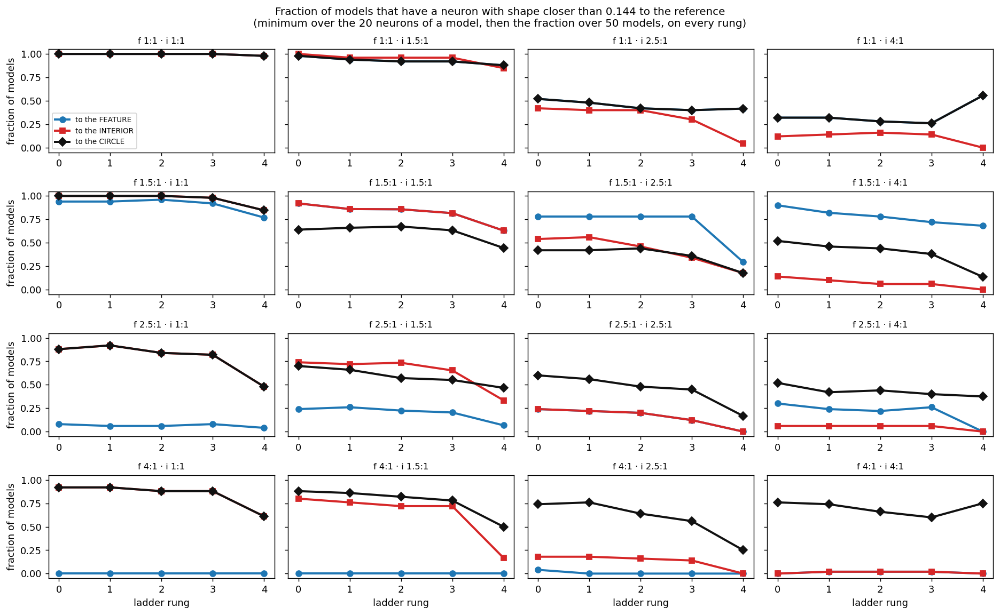

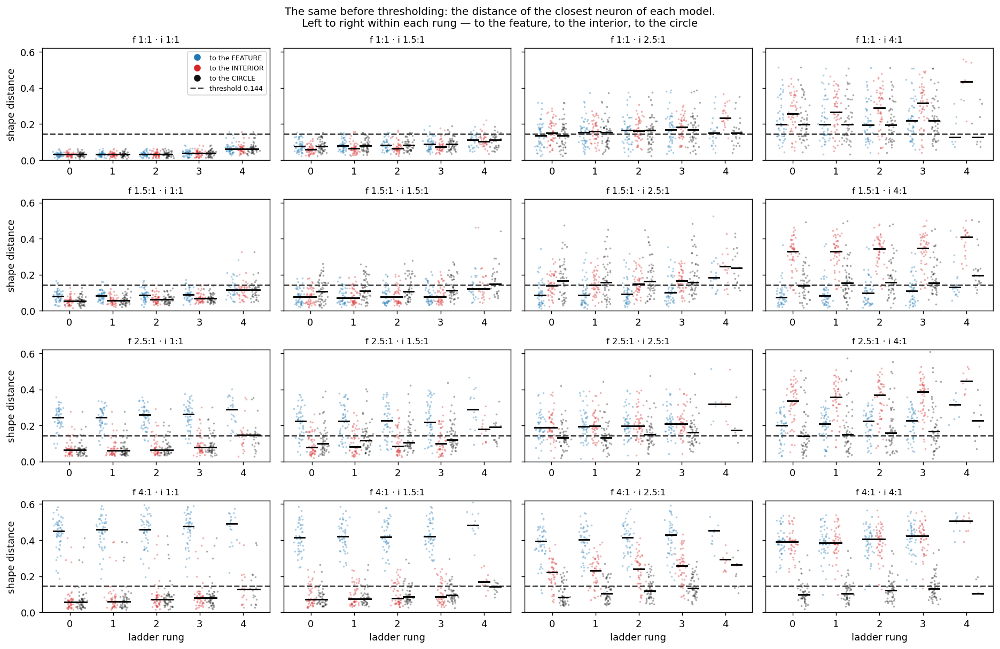

MIDDLE RUNG — fraction of models that have a neuron closer than 0.144:

to the FEATURE:
interior_aspect   1.0   1.5   2.5   4.0
feature_aspect                         
1.0              1.00  0.92  0.42  0.28
1.5              0.96  0.86  0.78  0.78
2.5              0.06  0.22  0.20  0.22
4.0              0.00  0.00  0.00  0.02

to the INTERIOR:
interior_aspect   1.0   1.5   2.5   4.0
feature_aspect                         
1.0              1.00  0.96  0.40  0.16
1.5              1.00  0.86  0.46  0.06
2.5              0.84  0.73  0.20  0.06
4.0              0.88  0.72  0.16  0.02

to the CIRCLE:
interior_aspect   1.0   1.5   2.5   4.0
feature_aspect                         
1.0              1.00  0.92  0.42  0.28
1.5              1.00  0.67  0.44  0.44
2.5              0.84  0.57  0.48  0.44
4.0              0.88  0.82  0.64  0.66

median of the distance itself on the middle rung (not a fraction):

to the FEATURE:
interior_aspect    1.0    1.5    2.5    4.0
feature_aspect               

In [27]:
TH = 0.144
REFS = [("dfeat", "to the FEATURE", gp.C_FEATURE, "o"),
        ("dint", "to the INTERIOR", gp.C_INTERIOR, "s"),
        ("d_circle", "to the CIRCLE", gp.C_CURVE, "D")]

# for each model on each rung — the neuron closest to the reference
per = (sub.groupby(["dataset_type", "feature_aspect", "interior_aspect",
                    "model_index", "rung"])
          .agg(**{c: (c, "min") for c, *_ in REFS},
               neurons=("dfeat", "size")).reset_index())

frac = (per.groupby(["dataset_type", "feature_aspect", "interior_aspect", "rung"])
        .agg(**{c: (c, lambda s: (s < TH).mean()) for c, *_ in REFS},
             models=("dfeat", "size")).reset_index())

fig, axes = plt.subplots(4, 4, figsize=(14.5, 9.0), sharey=True)
for ax, name in zip(axes.flat, plan_A):
    meta = cells_meta.loc[name]
    g = frac[frac.dataset_type == name].sort_values("rung")
    for col, lab, colr, mk in REFS:
        ax.plot(g.rung, g[col], mk + "-", color=colr, lw=2.2, ms=6, label=lab)
    ax.set_ylim(-.05, 1.05); ax.set_xticks(range(5))
    ax.set_title(f"f {meta.feature_aspect:g}:1 · i {meta.interior_aspect:g}:1", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("ladder rung")
for ax in axes[:, 0]:
    ax.set_ylabel("fraction of models")
axes[0, 0].legend(fontsize=7.5)
fig.suptitle(f"Fraction of models that have a neuron with shape closer than {TH} to the reference\n"
             "(minimum over the 20 neurons of a model, then the fraction over 50 models, on every rung)",
             fontsize=11)
plt.tight_layout(); plt.show()

# the same before thresholding: the distances themselves, one point per model
fig, axes = plt.subplots(4, 4, figsize=(14.5, 9.5), sharey=True)
rng = np.random.default_rng(2)
offs = {"dfeat": -.26, "dint": 0.0, "d_circle": .26}
for ax, name in zip(axes.flat, plan_A):
    meta = cells_meta.loc[name]
    g = per[per.dataset_type == name]
    for col, lab, colr, mk in REFS:
        for j in range(5):
            v = g[g.rung == j][col].dropna()
            if not len(v):
                continue
            ax.scatter(rng.normal(j + offs[col], .055, len(v)), v, s=4, alpha=.35,
                       color=colr, linewidths=0)
            ax.plot([j + offs[col] - .12, j + offs[col] + .12], [v.median()]*2,
                    color="k", lw=1.6, zorder=5)
    ax.axhline(TH, color="#444", ls="--", lw=1.5)
    ax.set_xticks(range(5)); ax.set_ylim(0, .62)
    ax.set_title(f"f {meta.feature_aspect:g}:1 · i {meta.interior_aspect:g}:1", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("ladder rung")
for ax in axes[:, 0]:
    ax.set_ylabel("shape distance")
axes[0, 0].legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c, label=l)
                           for _, l, c, _ in REFS]
                  + [plt.Line2D([], [], ls="--", color="#444", label=f"threshold {TH}")],
                  fontsize=7)
fig.suptitle("The same before thresholding: the distance of the closest neuron of each model.\n"
             "Left to right within each rung — to the feature, to the interior, to the circle",
             fontsize=11)
plt.tight_layout(); plt.show()

m2 = frac[frac.rung == 2].copy()
print(f"MIDDLE RUNG — fraction of models that have a neuron closer than {TH}:")
for col, lab, *_ in REFS:
    print(f"\n{lab}:")
    print(m2.pivot(index="feature_aspect", columns="interior_aspect", values=col)
          .round(2).to_string())
m2 = m2.rename(columns={"dfeat": "f", "dint": "i", "d_circle": "circle"})
print("\nmedian of the distance itself on the middle rung (not a fraction):")
pm = per[per.rung == 2]
for col, lab, *_ in REFS:
    print(f"\n{lab}:")
    print(pm.pivot_table(index="feature_aspect", columns="interior_aspect", values=col,
                         aggfunc="median").round(3).to_string())


**Observations.**

- **Neurons have the shape of the feature exactly when the feature is round.** Down the first column
  (round interior) the fraction of models with a neuron of the shape of the feature goes **1.00 → 0.96 → 0.06 → 0.00**.
  With a 2.5:1 and a 4:1 feature such neurons practically do not exist in any of the 50 models.
- **Neurons have the shape of the interior exactly when the interior itself is round.** Rightward along
  the first row (the feature is round, the interior elongates) the fraction of models with a neuron of the shape of the
  interior goes **1.00 → 0.96 → 0.40 → 0.16**. The same fall as for the feature in the previous point,
  only along the other axis.
- **The shape of a circle is present almost everywhere.** In the first column 1.00 · 1.00 · 0.84 · 0.88, and in the hardest
  cell "both 4:1" **0.66** against 0.02 and 0.02 for the two objects. The lowest value is
  0.28, and it is in the cell "feature round, interior 4:1", where "circle" and "feature" are one and the same,
  so this minimum is not about the circle but about the fact that everything is hard in this cell.
- **A check of itself.** In the top row "to the feature" and "to the circle" coincide to the last
  digit — the feature there is a circle. The instrument had to give this identity, and it did.
- **The threshold almost nowhere decides.** The second figure shows the distances themselves. In the bottom left corner
  (feature 4:1, round interior) the distance to the feature is 0.46, and to the circle 0.06 — a sevenfold difference, and
  no threshold between 0.1 and 0.3 will change anything. The only zone where the threshold really
  matters is the top right corner (round feature, interior 2.5:1 and 4:1): there all three
  distances lie in 0.16–0.29, that is, right at the threshold, and the fractions in these three cells should be read
  as "about half", not as an exact number.
- **Along the ladder the picture is stable**: the lines are almost horizontal on rungs 0–3. Rung 4
  drops out where few have it.

**Conclusion.** Neither of the two objects describes the shape of the level curve across the whole grid. What describes it
is **the circle**: the only reference whose fraction does not fall to zero in any cell. This does not
mean that the network "strives for the round" — one cannot say that without an ablation. What can be said is
the following: **a typical level curve stays close to round for any shape of both objects and
coincides with an object exactly when the object itself is close to round.** The word "typical" here is not a
softening but part of the statement: for a minority of neurons the curve is stably elongated (up to a third in
some cells), this is a separate population, and it is taken apart in 2.3.


## 2.5 Orientation: where exactly the curve is elongated

The shape distance takes the phase into account, but it cannot be seen in one number, and orientation is a more
sensitive question than magnitude. In block A **both objects are elongated along the x axis**, so by
orientation one cannot tell "follows the feature" from "follows the interior" — both hypotheses
predict one and the same thing. They are told apart by block B, where the interior is turned across.

Here orientation is needed for something else: it tells **whether the elongation is meaningful at all**. A curve with
elongation 2 pointing anywhere from neuron to neuron, and a curve with elongation 2 always
pointing along the objects, are two different facts, while by the magnitude of `a₂` they are indistinguishable.

**How it is computed.** The radial profile is expanded in a series, and the second harmonic gives
`a₂·cos(2(θ − φ₂))`. The maximum of the profile falls at `θ = φ₂` (modulo π), so the direction of the
major axis is exactly `φ₂ mod π`. Note: **the angles here are directions, not vectors**:
0° and 180° are one and the same direction.

Orientation is defined only when the elongation is real: for an almost round curve the major axis
is unstable and its angle is noise. That is why only curves with `a₂ ≥ 0.10` (elongation from 1.22) are counted, and the
fraction discarded is printed.

**First — a check of the measurement itself** on four curves for which the answer is known in advance.


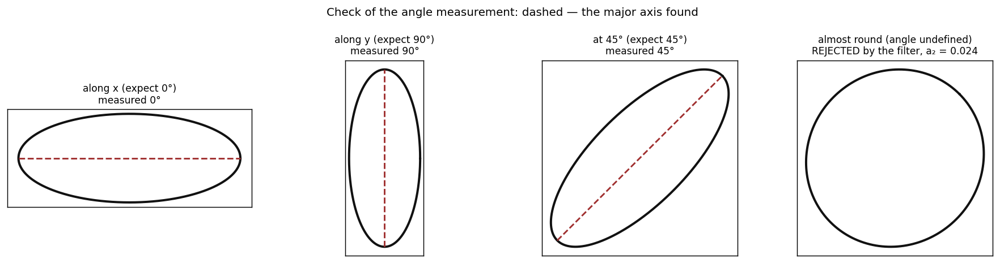

In [28]:
GATE = .10
ANG = np.linspace(0, 2*np.pi, 721)[:-1]

def ellipse(a, b, rot=0.0):
    p = np.stack([a*np.cos(ANG), b*np.sin(ANG)], 1)
    if rot:
        c_, s_ = np.cos(rot), np.sin(rot)
        p = p @ np.array([[c_, -s_], [s_, c_]]).T
    return p

CHECKS = [(2.5, 1.0, 0.0, "along x", "expect 0°"),
          (1.0, 2.5, 0.0, "along y", "expect 90°"),
          (2.5, 1.0, np.pi/4, "at 45°", "expect 45°"),
          (1.05, 1.0, np.pi/4, "almost round", "angle undefined")]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, (a, b, rot, lab, exp) in zip(axes, CHECKS):
    pts = ellipse(a, b, rot)
    ax.plot(*pts.T, color=gp.C_CURVE, lw=2.2)
    d_ = fourier_descriptor(torch.tensor(pts, dtype=torch.float32))
    ang = np.degrees(d_["phase"][2] % np.pi)
    passes = d_["amplitude"][2] >= GATE
    ok = "measured" if passes else "REJECTED by the filter, a₂ ="
    val = f"{ang:.0f}°" if passes else f"{d_['amplitude'][2]:.3f}"
    if passes:                                   # a round one has no axis — not drawn
        L = max(a, b)
        ax.plot([-L*np.cos(np.radians(ang)), L*np.cos(np.radians(ang))],
                [-L*np.sin(np.radians(ang)), L*np.sin(np.radians(ang))],
                color=gp.C_BAD, lw=1.6, ls="--")
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{lab} ({exp})\n{ok} {val}", fontsize=9.5)
fig.suptitle("Check of the angle measurement: dashed — the major axis found", fontsize=11)
plt.tight_layout(); plt.show()


The instrument returns exactly what is expected, and on the almost round curve it honestly refuses to answer.

**Now the real data.** Below is a "rose" of angles for each of the sixteen cells. This is a
**histogram, not an average**: for each curve of the cell its own angle `φ₂` is taken, the angles
are distributed over 36 sectors 10° wide, and the height of a petal is the fraction of curves that fell into the sector
(each panel is normalised to its own maximum, so between panels only the shape of the rose can be
compared, not the length of the petals). No mean angle is computed — the mean over directions is
poorly defined, and the median would hide exactly what the picture is drawn for: whether the
directions have a spread. All curves of the cell that passed the filter on `a₂` are counted: all neurons, all
models, all rungs.
Since an angle is a direction, not a vector, each measurement is plotted twice, at `φ` and at
`φ + 180°`, which makes the rose symmetric; it should be read as an "axis", not as an "arrow".

**How to read it.** A horizontal petal (right-left) means the curve is elongated **along** the objects.
A vertical one (up-down) — **across**. A uniform circle means there is no direction: elongation is there, but
it is random from neuron to neuron. The title of each panel gives the fraction of curves within the ±30° sector around the axis of the
objects and the fraction that passed the filter on `a₂`.


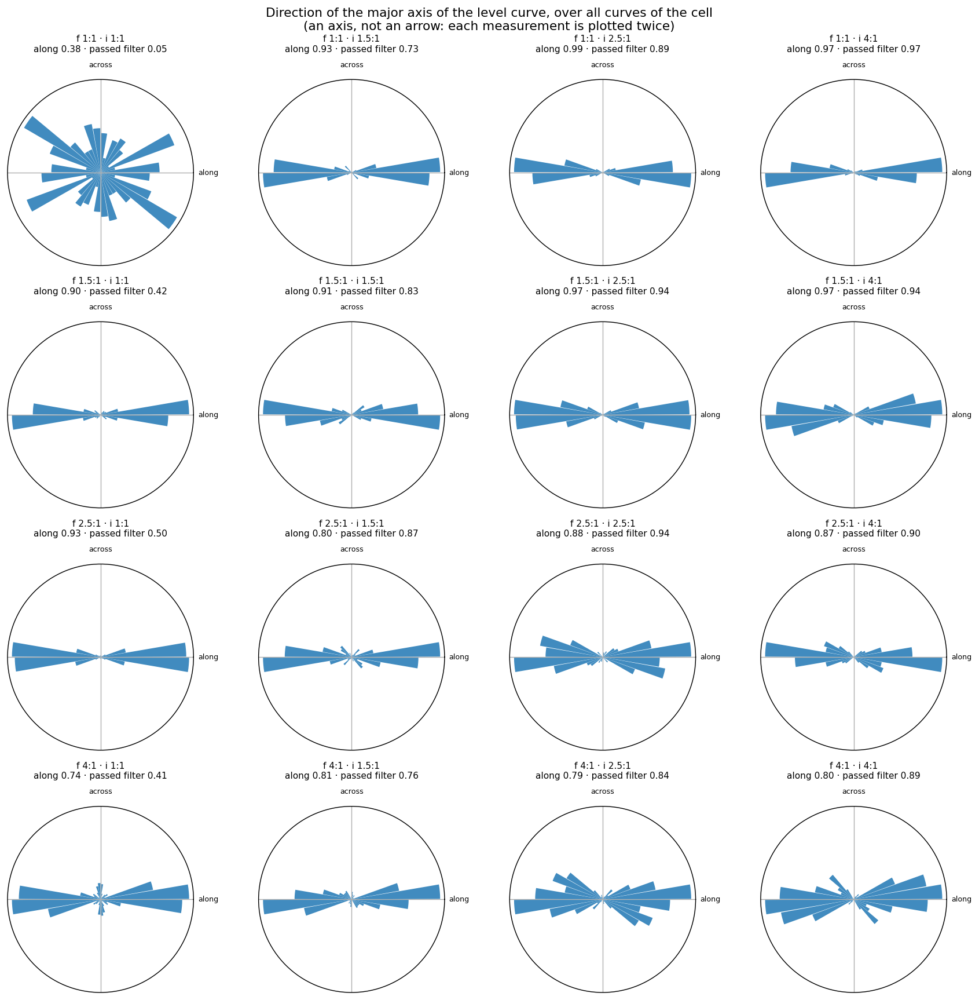

curves in total 39718, of them with a₂ ≥ 0.1: 74%

fractions by cell:
 feature  interior    n  passed  along  oblique  across
     1.0       1.0  144    0.05   0.38     0.33    0.29
     1.0       1.5 1800    0.73   0.93     0.06    0.01
     1.0       2.5 2121    0.89   0.99     0.00    0.00
     1.0       4.0 2130    0.97   0.97     0.03    0.00
     1.5       1.0 1139    0.42   0.90     0.10    0.01
     1.5       1.5 2058    0.83   0.91     0.08    0.01
     1.5       2.5 2351    0.94   0.97     0.03    0.00
     1.5       4.0 2464    0.94   0.97     0.03    0.00
     2.5       1.0 1240    0.50   0.93     0.03    0.03
     2.5       1.5 2192    0.87   0.80     0.17    0.03
     2.5       2.5 2336    0.94   0.88     0.09    0.03
     2.5       4.0 2315    0.90   0.87     0.12    0.01
     4.0       1.0  951    0.41   0.74     0.09    0.17
     4.0       1.5 1846    0.76   0.81     0.12    0.06
     4.0       2.5 1933    0.84   0.79     0.19    0.02
     4.0       4.0 2223    0.89   

In [29]:
ori = sub[sub.a2 >= GATE].copy()
ori["dir"] = np.radians(ori.angle2)

fig, axes = plt.subplots(4, 4, figsize=(13.5, 13.5),
                         subplot_kw={"projection": "polar"})
edges = np.radians(np.arange(0, 361, 10))
for ax, name in zip(axes.flat, plan_A):
    meta = cells_meta.loc[name]
    g = ori[ori.dataset_type == name]
    allg = sub[sub.dataset_type == name]
    both = np.concatenate([g["dir"].values, g["dir"].values + np.pi]) % (2*np.pi)
    h, _ = np.histogram(both, bins=edges)
    h = h / max(h.max(), 1)
    ax.bar(edges[:-1] + np.radians(5), h, width=np.radians(9.4),
           color=gp.C_FEATURE, alpha=.85, edgecolor="none")
    a = g.angle2.values
    along = float(((a < 30) | (a > 150)).mean()) if len(a) else np.nan
    ax.set_yticks([]); ax.set_xticks(np.radians([0, 90, 180, 270]))
    ax.set_xticklabels(["along", "across", "", ""], fontsize=7)
    ax.set_title(f"f {meta.feature_aspect:g}:1 · i {meta.interior_aspect:g}:1\n"
                 f"along {along:.2f} · passed filter {len(g)/max(len(allg),1):.2f}",
                 fontsize=8.5, pad=9)
fig.suptitle("Direction of the major axis of the level curve, over all curves of the cell\n"
             "(an axis, not an arrow: each measurement is plotted twice)", fontsize=12)
plt.tight_layout(); plt.show()

res = []
for name, g in ori.groupby("dataset_type"):
    a = g.angle2.values
    meta = cells_meta.loc[name]
    res.append(dict(feature=meta.feature_aspect, interior=meta.interior_aspect, n=len(g),
                    passed=len(g)/max(len(sub[sub.dataset_type == name]), 1),
                    along=float(((a < 30) | (a > 150)).mean()),
                    oblique=float((((a >= 30) & (a <= 60)) | ((a >= 120) & (a <= 150))).mean()),
                    across=float(((a > 60) & (a < 120)).mean())))
res = pd.DataFrame(res).sort_values(["feature", "interior"])
print(f"curves in total {len(sub)}, of them with a₂ ≥ {GATE}: {(sub.a2 >= GATE).mean():.0%}")
print("\nfractions by cell:")
print(res.round(2).to_string(index=False))
print("\nfraction “along” by row (feature aspect):")
print(res.groupby("feature")["along"].mean().round(2).to_string())
print("fraction “along” by column (interior aspect):")
print(res.groupby("interior")["along"].mean().round(2).to_string())


**Observations.**

- **The control worked.** In the basic cell "circle in circle" only **5%** of the curves pass the filter on `a₂`,
  and their rose is isotropic: the direction is smeared over all angles. Both objects are round,
  there is no distinguished direction — and the instrument did not invent one. In any other cell
  41–97% of the curves pass the filter.
- **Wherever there is elongation, it is along the objects.** The fraction of angles within ±30° of the x axis is
  **0.74–0.99** across all the other fifteen cells. Across (90° ± 30°) — 0.00–0.03 everywhere
  except one cell.
- **The order in the direction grows from the interior, not from the feature.** By column (aspect of the
  interior) the fraction "along" goes 0.74 → 0.86 → 0.91 → 0.90; by row (aspect of the feature) —
  0.82 → 0.94 → 0.87 → **0.79**, that is, it is smallest for the most elongated feature. A round
  interior with an elongated feature (bottom left corner) gives the most disordered rose among the
  non-empty ones: "along" 0.74, "across" 0.17.
- **Oblique directions appear in the same places** where the order falls: 0.12–0.19 in the bottom row against
  0.00–0.03 in the top one.

**Conclusion, and a limited one.** In block A **both** objects are elongated along the x axis, so "along"
does not distinguish hypotheses (a) and (b) — both predict one and the same thing. What orientation does
establish here is that the quantity itself is meaningful: the elongation of the curve is not random noise,
it has a stable direction, and this direction is set by the geometry of the pair. The hypotheses are told apart
by block B, where the interior is turned across the feature.


## 2.6 How much the shape changes along the ladder

So far it has been said that the rungs give roughly one and the same thing, and this was visible on the clouds (2.2)
and on the almost horizontal lines (2.4). But both checks are indirect: they compare **distances to the
references**, not the shapes themselves with each other. Two curves can be equally far from the feature and still
be completely different. The direct question — how much the shape of the level curve changes as we go from the
interior to the feature — has not been asked yet.

It is measured in two ways, and both are needed:

* **the accumulated change** — the shape distance between the curve of rung 0 and the curve of rung 4 of
  one and the same neuron: how far the shape has gone over the whole way. It is computed only for those neurons
  that have **both** extreme rungs, and there are 14% of them (1.5) — this must be kept in mind: the sample here is
  biased towards neurons with a wide family;
* **the step between neighbours** — the distance between the curves of neighbouring rungs: whether the shape changes
  gradually or in a jump.

**The third panel — what is compared with what.** Vertically, the same accumulated change (the median over the
cell). Horizontally, `d(feature, interior)`, the shape distance **between the objects of the
cell themselves**, that is, how much this cell poses the question at all: on the diagonal of block A the objects are similar
and this distance equals zero, in the corner "circle against 4:1" it is maximal. The meaning of the comparison is this:
if the shape of the curve were determined by which object it passes near, then, going from one
object to the other, it would have to change **by about the difference between the objects** — that
is, the points would lie along the diagonal. However far below the diagonal they are — that is how far the curve **does not
switch** from one shape to the other.

All three quantities are computed in the same units — the shape distance over six harmonics with phases — and
compared with two scales: the instrument's own error (0.010) and the step of the design's aspect
grid (0.144).


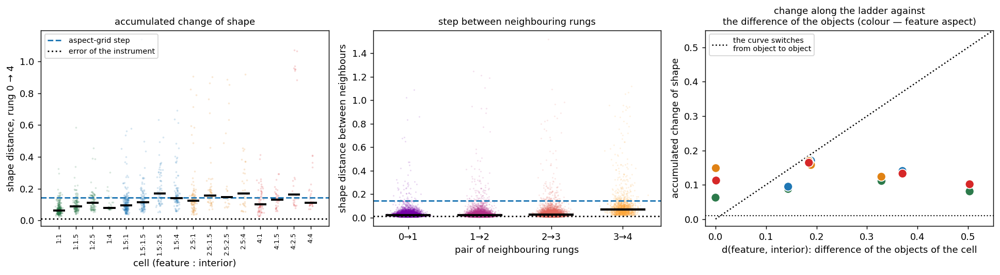

accumulated change of shape (rung 0 → 4): median 0.099, 75th percentile 0.144, n = 1558
step between neighbours: median 0.022
pair
0→1    0.021
1→2    0.019
2→3    0.023
3→4    0.068

difference of the objects, median across cells 0.187, maximum 0.503

Spearman(accumulated change, difference of the objects) = +0.068, p = 0.80, n = 16

accumulated change by cell (median) against the difference of the objects:
 feature_aspect  interior_aspect  accum  objects_shape
            1.0              1.0  0.062          0.000
            1.0              1.5  0.088          0.144
            1.0              2.5  0.111          0.329
            1.0              4.0  0.081          0.503
            1.5              1.0  0.094          0.144
            1.5              1.5  0.114          0.000
            1.5              2.5  0.170          0.189
            1.5              4.0  0.140          0.370
            2.5              1.0  0.123          0.328
            2.5              1.5  0.15

In [30]:
# the full shape vector: six harmonics with phases, as in the definition of the distance (1.2)
UC = [f"u{k}{ax}" for k in range(1, 7) for ax in ("c", "s")]
key = ["dataset_type", "model_index", "layer_id", "coord_id"]
wide = sub.pivot_table(index=key, columns="rung", values=UC)
acc, step = [], []
for idx, r in wide.iterrows():
    v = {}
    for j in range(5):
        vec = np.array([r[(u, j)] for u in UC])
        if np.isfinite(vec).all():
            v[j] = vec
    if 0 in v and 4 in v:
        acc.append(dict(dataset_type=idx[0], d=float(np.linalg.norm(v[4]-v[0])/np.sqrt(2))))
    for j in range(4):
        if j in v and j+1 in v:
            step.append(dict(dataset_type=idx[0], pair=f"{j}→{j+1}",
                             d=float(np.linalg.norm(v[j+1]-v[j])/np.sqrt(2))))
acc = pd.DataFrame(acc).merge(cells[["dataset_type", "feature_aspect", "interior_aspect"]],
                              on="dataset_type")
step = pd.DataFrame(step).merge(cells[["dataset_type", "feature_aspect", "interior_aspect"]],
                                on="dataset_type")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
order = sorted(acc.groupby(["feature_aspect", "interior_aspect"]).groups)
rng = np.random.default_rng(1)
for i, (fa, ia) in enumerate(order):
    v = acc[(acc.feature_aspect == fa) & (acc.interior_aspect == ia)].d
    axes[0].scatter(rng.normal(i, .08, len(v)), v, s=4, alpha=.18, color=COL[fa],
                    linewidths=0)
    axes[0].plot([i-.3, i+.3], [v.median()]*2, color="k", lw=2.2, zorder=4)
axes[0].axhline(.144, color=gp.C_FEATURE, ls="--", lw=1.6, label="aspect-grid step")
axes[0].axhline(.010, color=gp.C_CURVE, ls=":", lw=1.6, label="error of the instrument")
axes[0].set_xticks(range(len(order)), [f"{a:g}:{b:g}" for a, b in order], fontsize=7, rotation=90)
axes[0].set_xlabel("cell (feature : interior)")
axes[0].set_ylabel("shape distance, rung 0 → 4")
axes[0].legend(fontsize=8); axes[0].set_title("accumulated change of shape", fontsize=10)

for i, p in enumerate(["0→1", "1→2", "2→3", "3→4"]):
    v = step[step["pair"] == p].d
    axes[1].scatter(rng.normal(i, .08, len(v)), v, s=3, alpha=.14, color=ramp[i+1],
                    linewidths=0)
    axes[1].plot([i-.3, i+.3], [v.median()]*2, color="k", lw=2.4, zorder=4)
axes[1].axhline(.144, color=gp.C_FEATURE, ls="--", lw=1.6)
axes[1].axhline(.010, color=gp.C_CURVE, ls=":", lw=1.6)
axes[1].set_xticks(range(4), ["0→1", "1→2", "2→3", "3→4"])
axes[1].set_xlabel("pair of neighbouring rungs")
axes[1].set_ylabel("shape distance between neighbours")
axes[1].set_title("step between neighbouring rungs", fontsize=10)

both = acc.groupby(["feature_aspect", "interior_aspect"]).d.median().rename("accum").reset_index()
obj = (gs.shape_by_cell(gs.ladder_long(df, "value")).query("rung == 2 and block == 'A'")
       .groupby(["feature_aspect", "interior_aspect"]).objects_shape.first().reset_index())
both = both.merge(obj, on=["feature_aspect", "interior_aspect"])
axes[2].scatter(both.objects_shape, both["accum"], s=90,
                c=[COL[f] for f in both.feature_aspect], edgecolor="white", zorder=3)
axes[2].plot([0, .55], [0, .55], ls=":", color="k", lw=1.4,
             label="the curve switches\nfrom object to object")
axes[2].axhline(.010, color=gp.C_CURVE, ls=":", lw=1.2)
axes[2].set_xlabel("d(feature, interior): difference of the objects of the cell")
axes[2].set_ylabel("accumulated change of shape")
axes[2].set_xlim(-.02, .55); axes[2].set_ylim(-.02, .55); axes[2].legend(fontsize=8)
axes[2].set_title("change along the ladder against\nthe difference of the objects (colour — feature aspect)",
                  fontsize=10)
plt.tight_layout(); plt.show()

print(f"accumulated change of shape (rung 0 → 4): median {acc.d.median():.3f}, "
      f"75th percentile {acc.d.quantile(.75):.3f}, n = {len(acc)}")
print(f"step between neighbours: median {step.d.median():.3f}")
print(step.groupby('pair').d.median().round(3).to_string())
print(f"\ndifference of the objects, median across cells {obj.objects_shape.median():.3f}, "
      f"maximum {obj.objects_shape.max():.3f}")
from scipy.stats import spearmanr
rho, pv = spearmanr(both["accum"], both.objects_shape)
print(f"\nSpearman(accumulated change, difference of the objects) = {rho:+.3f}, "
      f"p = {pv:.2f}, n = {len(both)}")
print("\naccumulated change by cell (median) against the difference of the objects:")
print(both.round(3).to_string(index=False))


**Observations.**

- **The shape hardly changes along the family.** The accumulated change from the inner rung to the
  outer one: median **0.099**, 75th percentile 0.144. That is, for three neurons of four the whole
  way from the interior to the feature changes the shape by less than one step of the design's aspect grid.
- **It changes gradually, except for the last step.** Neighbouring rungs diverge by 0.021 · 0.019 ·
  0.023 · **0.068**: the first three steps are equal and small, the last is three times larger. The outer rung is
  both the rarest (10%) and the least like the others; this agrees with the fact that there the curve
  approaches the edge of the window and the region where the field has already reached the plateau.
- **The change of shape is not related in any way to how much the objects differ.** Spearman between
  the median accumulated change of a cell and `d(feature, interior)` is **+0.07** at p = 0.80
  over 16 cells. The accumulated change lies in a narrow corridor 0.062–0.170, while the difference of the
  objects varies from 0 to 0.503 — that is, eight times more. On the third panel this is seen
  directly: all points lie under the diagonal and hardly rise to the right.
- **A caveat about the sample.** The accumulated change is computed only for 14% of neurons — those that
  have both extreme rungs (1.5). This subsample is biased towards neurons with a wide
  family of curves. The step between neighbours has no such bias and gives the same answer.

**Conclusion.** If the shape of the curve were determined by which object it is currently passing near, then
on the way from the interior to the feature it would change by about the difference between them. It changes by
one and the same small amount regardless of this difference. **The family of level curves of one neuron
has one shape, rather than switching from the shape of one object to the shape of the other.**


## 2.7 What the two earlier criteria say

The descriptor has answered the question of the block. Now the structural and homological criteria, for stitching with
experiments 1, 2 and 4: they measure not shape but coincidence with the target, and their behaviour has to be
consistent with what was found. The protocol for the structural criterion is the same as above — the best neuron of a
model, then the fraction of models — so the numbers are directly comparable.

What is shown are **distributions, not lines across cells**. The reason is simple: the witness fraction is one
number obtained by cutting a distribution with a threshold, and from it one cannot tell "the target moved away from the
nulls" from "the target and the nulls lie together, and the threshold happened to fall in the middle". Cell by cell both
can be seen. The fractions themselves remain in the tables under the pictures.

The homological criterion is read **the other way round**: for it larger is better, so the criterion
working looks like the target to the RIGHT of the nulls.


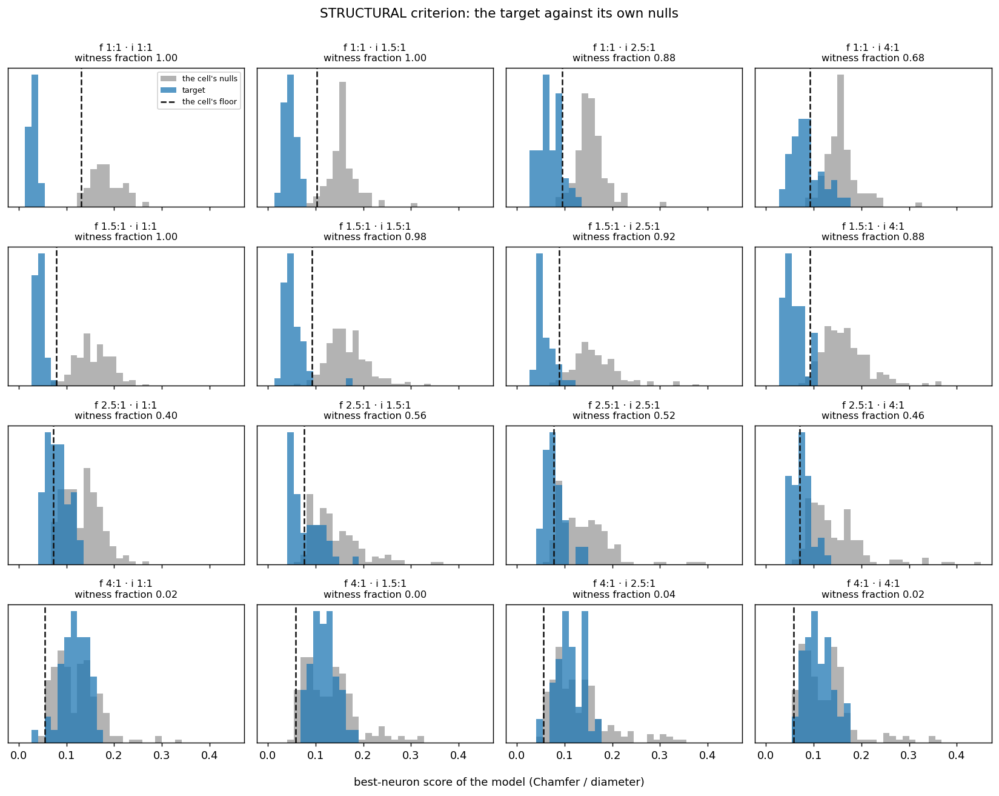

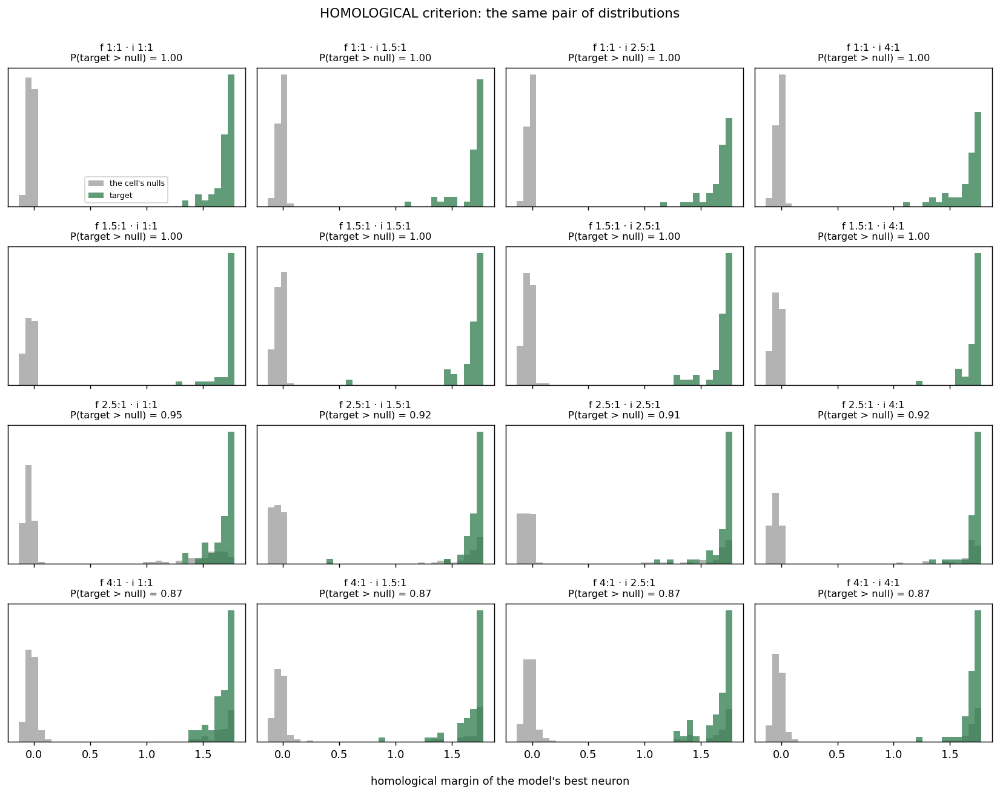

structural criterion by row (mean over the row):
                rate_floor  rate_p5
feature_aspect                     
1.0                  0.890     0.93
1.5                  0.945     0.98
2.5                  0.485     0.60
4.0                  0.020     0.03

structural criterion by cell — witness fraction:
interior_aspect   1.0   1.5   2.5   4.0
feature_aspect                         
1.0              1.00  1.00  0.88  0.68
1.5              1.00  0.98  0.92  0.88
2.5              0.40  0.56  0.52  0.46
4.0              0.02  0.00  0.04  0.02

median best-neuron score (in brackets — the floor of the cell):
  feature 1:1: i 1 → 0.030 (0.131)   i 1.5 → 0.045 (0.102)   i 2.5 → 0.065 (0.095)   i 4 → 0.079 (0.092)
  feature 1.5:1: i 1 → 0.043 (0.078)   i 1.5 → 0.049 (0.093)   i 2.5 → 0.051 (0.088)   i 4 → 0.054 (0.092)
  feature 2.5:1: i 1 → 0.081 (0.072)   i 1.5 → 0.067 (0.077)   i 2.5 → 0.076 (0.077)   i 4 → 0.072 (0.070)
  feature 4:1: i 1 → 0.121 (0.055)   i 1.5 → 0.117 (0.058)   

feature_role     null  target
feature_aspect               
1.0             0.798   0.360
1.5             0.748   0.281
2.5             0.530   0.240
4.0             0.356   0.238

for comparison — fraction of models with a neuron of the shape of the feature (descriptor, middle rung):
feature_aspect
1.0    0.655
1.5    0.844
2.5    0.176
4.0    0.005


In [31]:
Ac = cells[cells.block == "A"]
titles_A = [f"f {r.feature_aspect:g}:1 · i {r.interior_aspect:g}:1"
            for r in cells_meta.loc[plan_A].itertuples()]

gp.plot_score_panels(best, plan_A, titles_A, floors=floors, ncols=4,
                     suptitle="STRUCTURAL criterion: the target against its own nulls")
plt.show()

# homological: its best neuron is the one with the LARGEST margin
hm = (df[df.block == "A"]
      .groupby(["dataset_type", "feature_role", "feature_name", "model_path"])
      .homological_persistence_margin.max().rename("margin").reset_index())
gp.plot_margin_panels(hm, plan_A, titles_A, ncols=4,
                      suptitle="HOMOLOGICAL criterion: the same pair of distributions")
plt.show()

print("structural criterion by row (mean over the row):")
print(Ac.groupby("feature_aspect")[["rate_floor", "rate_p5"]].mean().round(3).to_string())
print("\nstructural criterion by cell — witness fraction:")
print(Ac.pivot(index="feature_aspect", columns="interior_aspect", values="rate_floor")
      .round(2).to_string())
print("\nmedian best-neuron score (in brackets — the floor of the cell):")
piv_s = Ac.pivot(index="feature_aspect", columns="interior_aspect", values="target_median")
piv_f = Ac.pivot(index="feature_aspect", columns="interior_aspect", values="floor")
for fa in piv_s.index:
    print(f"  feature {fa:g}:1: " + "   ".join(
        f"i {ia:g} → {piv_s.loc[fa, ia]:.3f} ({piv_f.loc[fa, ia]:.3f})"
        for ia in piv_s.columns))

t_all = df[(df.feature_role == "target") & (df.block == "A")]
print("\nhomological criterion by feature aspect:")
print(t_all.groupby("feature_aspect").agg(
    neuron_fraction=("homological_is_witness", "mean"),
    median_margin=("homological_persistence_margin", "median")).round(3).to_string())
print("\nfraction of EMPTY diagrams (no loop found at all), by feature aspect:")
print(df[df.block == "A"].assign(
    empty=lambda d: d.homological_persistence_margin.isna())
    .pivot_table(index="feature_aspect", columns="feature_role", values="empty")
    .round(3).to_string())

print("\nfor comparison — fraction of models with a neuron of the shape of the feature (descriptor, middle rung):")
print(m2.pivot(index="feature_aspect", columns="interior_aspect", values="f").mean(axis=1)
      .round(3).to_string())


**Observations.**

- **The structural criterion reproduces what the descriptor found.** The fraction of models with a witness
  falls along the rows **0.89 → 0.95 → 0.49 → 0.02** as the feature elongates; the fraction of models with a neuron
  of the **shape** of the feature goes 0.66 → 0.84 → 0.18 → 0.005. Two instruments, different quantities, one and the same
  break between aspects 1.5 and 2.5.
- **The floor moves towards the score.** For a round feature the floor is 0.092–0.131, for a 4:1 feature 0.055–0.058:
  an elongated target is easier to approach by chance, and the absolute score 0.106 at a 4:1 feature is
  twice WORSE than the floor, whereas 0.030 at a round one is four times better. This is exactly why
  the fraction is computed against the cell's own floor, and `τ = 0.1` does not apply here.
- **The homological criterion works in all sixteen cells.** `P(target > null)` equals
  **1.00** in the two top rows, 0.91–0.95 in the third and **0.87** in the bottom one. The distributions are
  apart: for the target the margin of the best neuron is gathered at 1.7, for the nulls at zero.
- **But it too weakens as the feature elongates, only differently.** The median margin over all neurons falls
  0.96 → 0.86 → 0.77 → 0.69, and the fraction of empty diagrams **for the nulls** falls 0.80 → 0.75 → 0.53 →
  0.36: the more elongated the target, the more often a loop is found at a null placement too. What weakens,
  therefore, is not sensitivity but specificity.
- **The fraction of neurons for which the criterion fires is indeed flat**: 0.546 · 0.562 ·
  0.575 · 0.565. Half of the neurons have a closed loop, whatever the geometry.

**Conclusion.** The three instruments are consistent and say different things about different things. A neuron always has a closed
loop, and it is distinguishable from the null one — the homological criterion. It coincides with the feature only when
the feature is round — the structural one. **Why** it does not coincide — the shape of the curve is not set by the feature — the descriptor.


## 2.8 Summary of block A

Everything is computed by one rule: the minimum over neurons within a model, then the distribution over the 50
models; the similarity threshold is the step of the design's aspect grid, 0.144. The data are the recomputed ladder over
all 10,905 neurons of the block (39,718 curves), the ladder **by the field value**.

1. **The shape of the level curve is set first of all not by the feature.** With an elongated feature almost no
   neuron in any model carries the shape of the feature: the fraction of models is 0.00–0.02 at aspect 4:1 and 0.06–0.22 at
   2.5:1, on all five rungs (2.4). The marginal effect of the elongation of the feature on the elongation of the curve is
   **0.14** with its own range of 3.0, and the series is not even monotone (2.2). But this effect is not equal to
   zero, and it is seen most cleanly where the interior is round and does not drown it out: in the first column
   of the grid the median elongation rises from **1.05** ("circle in circle") to **1.20 / 1.23 / 1.19** with a
   feature of 1.5 / 2.5 / 4:1. That is, the feature does elongate the curve — only three times more weakly than the interior and without
   a monotone continuation.
2. **There is a response to the interior, it is monotone, but weak.** The marginal effect of the interior is
   **0.46**, three times larger than the effect of the feature, and ordered (2.2). The shape of the interior is carried by 0.84–1.00
   of the models when its aspect is 1:1, and by 0.02–0.16 when it is 4:1 (2.4).
3. **The curve stays close to a circle.** This is the only one of the three references whose fraction does not
   fall to zero anywhere: 0.28–1.00 across all sixteen cells. In the cell "both 4:1", where the fraction for the feature
   and for the interior is 0.02 each, for the circle it is **0.66** (2.4). The median elongation of the curve across
   cells is 1.05–1.85 with objects 1–4 (2.2).
4. **The elongation of the curve is not random, but it too is set by the interior.** The direction of the major axis
   lies along the common axis of the objects for 0.74–0.99 of the curves; the order in the direction grows with the
   elongation of the **interior** (0.74 → 0.90) and weakens with the elongation of the **feature** (0.82 → 0.79).
   In the basic cell, where both objects are round, the rose is isotropic — a control of the instrument. (a) and
   (b) cannot be told apart by orientation in block A: the objects share one axis (2.5).
5. **The family of level curves of one neuron has ONE shape.** The accumulated change from rung
   0 to rung 4 is a median of **0.099** with a 75th percentile of 0.144, and it is **in no way related** to the
   difference of the objects of the cell: Spearman +0.07 at p = 0.80, a corridor of 0.062–0.170 against a range of the
   difference of 0–0.503 (2.6). The curve does not switch from the shape of one object to the shape of the other.
6. **The earlier criteria are consistent and add their own.** The structural one gives the same break between
   aspects 1.5 and 2.5. The homological one separates the target and the nulls in all cells
   (`P` = 0.87–1.00), but as the feature elongates it loses **specificity**: the fraction of empty diagrams for the
   nulls falls 0.80 → 0.36 (2.7).
7. **Within a model the neurons are almost interchangeable.** The best and the median neurons by score are always
   different neurons, but their curves diverge in shape by 0.025 in median, six times less than the step of the
   design (2.1).

**What block A cannot say.** In all sixteen cells the interior fits into the
circle inscribed in the feature — so a round level curve **separates the classes** everywhere, and the network
is never obliged to build another one. That is why "the shape is not set by the feature" is inseparable here from "the feature does not
require a different shape". Which of the two is true block A does not decide; this is taken apart below,
in section 5.4 (block D).

The second limitation is that **there is no ablation**, so everything said is a statement about **alignment**:
the shape of the level curves agrees with the geometry of the pair in such and such a way. That a neuron "encodes" the shape
does not follow from this and is not claimed here.


# 3. Block B. Orientation: the same question, put hard

## Setting

Block A could not tell the two hypotheses apart. In it **both objects are elongated along the x axis**, so
"the curve follows the feature" and "the curve follows the interior" predict one and the same
direction. They can be told apart only by turning the objects relative to each other — this is what block B
does.

**The grid is the same, 4 × 4**, and it is assembled from three sources:

* **nine cells are trained anew** — elongation of the feature × elongation of the interior over the series
  1.5 / 2.5 / 4, the interior turned by 90°. Only here do the objects really compete;
* **the four cells of the first column** (round interior) are taken from block A as they are: turning a
  circle changes nothing. This is a **control of the feature**: the curve has no axis from the interior, and if
  there is a direction nevertheless, the feature set it;
* **the three cells of the first row** (round feature) are taken from block A **turned by 90°**: a round
  feature is invariant under rotation, so such a cell is the ⊥ version of itself. This is a **control of the
  interior**: there is no axis from the feature, so only the interior can set a direction.

Such an assembly gives what none of the blocks gives separately: **the two edges of the grid measure the
contribution of each object on its own, and the middle what happens when they compete.**

**What is measured here.** In block A the main quantity was elongation, here it is **the direction of the
major axis of the curve**. It is the direct answer: 0° means "following the feature", 90° "following the interior".
For the three turned cells the measured angle is turned by 90° together with the dataset.

The protocol is the same: the ladder by the field value, all neurons of layers 1–4 of all 50 models, the angle is computed
only for curves with `a₂ ≥ 0.10`, the fraction that passed the filter is printed.


## 3.1 Datasets

Sixteen configurations. The first column is a round interior (taken from block A), the first row a round feature (block A, turned by 90°), the other nine are trained anew.


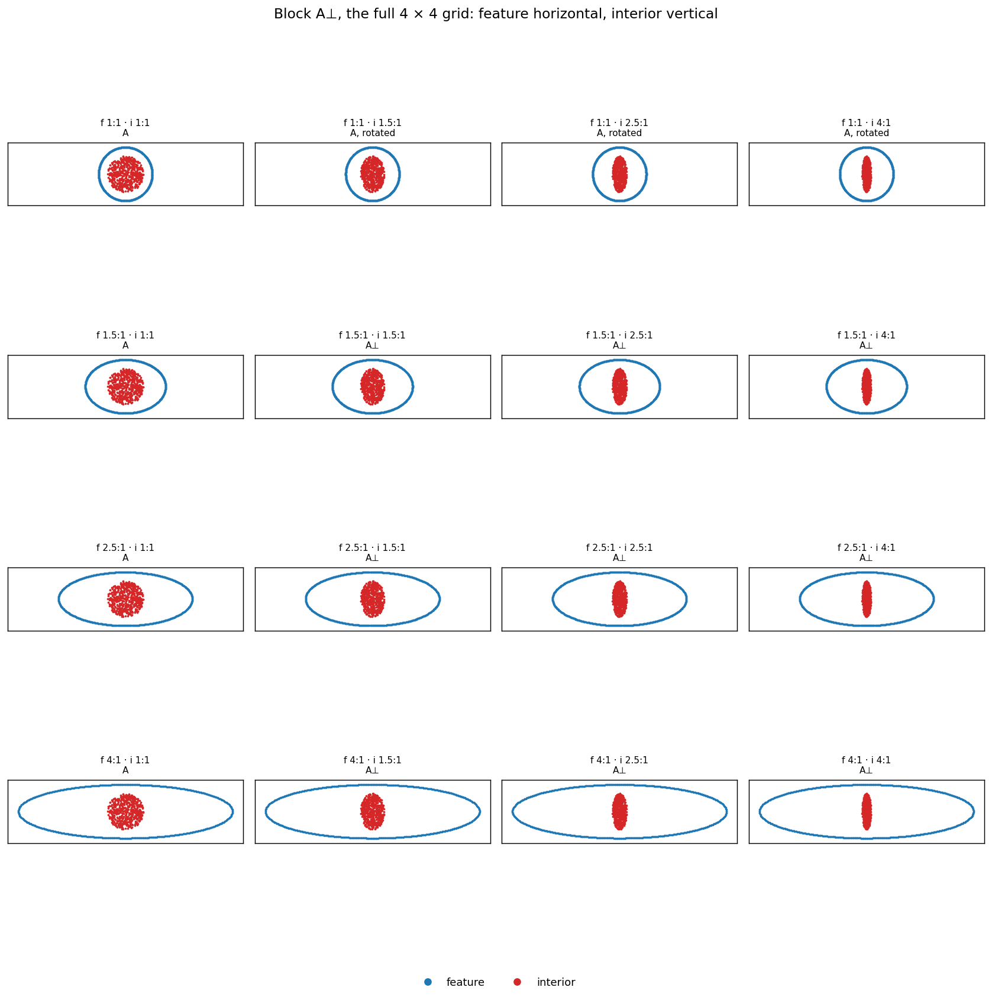

sources of the cells:
  feature 1:1  A             A, rotated    A, rotated    A, rotated  
  feature 1.5:1  A             A⊥            A⊥            A⊥          
  feature 2.5:1  A             A⊥            A⊥            A⊥          
  feature 4:1  A             A⊥            A⊥            A⊥          


In [32]:
ASP = [1.0, 1.5, 2.5, 4.0]

def perp_cell(fa, ia):
    # cell of the ⊥ grid: (name, rotation in degrees, where it is taken from)
    if fa > 1.0 and ia > 1.0:
        q = cells_meta[(cells_meta.block == "A⊥") & (cells_meta.feature_aspect == fa)
                       & (cells_meta.interior_aspect == ia)]
        return q.index[0], 0, "A⊥"
    q = cells_meta[(cells_meta.block == "A") & (cells_meta.feature_aspect == fa)
                   & (cells_meta.interior_aspect == ia)]
    return q.index[0], (90 if ia > 1.0 else 0), ("A, rotated" if ia > 1.0 else "A")

GRID = [[perp_cell(fa, ia) for ia in ASP] for fa in ASP]

def rot(P, deg):
    if not deg:
        return P
    t = np.radians(deg); c_, s_ = np.cos(t), np.sin(t)
    return np.asarray(P) @ np.array([[c_, -s_], [s_, c_]]).T

hx_all = hy_all = 0.0
for row in GRID:
    for name, deg, _ in row:
        h1, h2 = gp.cells_extent([name])
        if deg:
            h1, h2 = h2, h1
        hx_all, hy_all = max(hx_all, h1), max(hy_all, h2)

fig, axes = plt.subplots(4, 4, figsize=(13, 13))
for r, fa in enumerate(ASP):
    for c, ia in enumerate(ASP):
        ax = axes[r, c]; name, deg, src = GRID[r][c]
        Xc, yc, Ac = gs.dataset_points(name)[:3]
        Xi = rot(np.asarray(Xc[yc == 1]), deg); Af = rot(np.asarray(Ac), deg)
        ax.scatter(Xi[:, 0], Xi[:, 1], s=1.1, c=gp.C_INTERIOR, zorder=1)
        ax.scatter(Af[:, 0], Af[:, 1], s=1.1, c=gp.C_FEATURE, zorder=2)
        ax.set_xlim(-hx_all, hx_all); ax.set_ylim(-hy_all, hy_all)
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"f {fa:g}:1 · i {ia:g}:1\n{src}", fontsize=8.5)
fig.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=gp.C_FEATURE, label="feature"),
                    plt.Line2D([], [], marker="o", ls="", color=gp.C_INTERIOR,
                               label="interior")],
           loc="lower center", ncol=2, fontsize=10, frameon=False, bbox_to_anchor=(.5, -.01))
fig.suptitle("Block A⊥, the full 4 × 4 grid: feature horizontal, interior vertical",
             fontsize=13)
plt.tight_layout(rect=[0, .015, 1, 1]); plt.show()
print("sources of the cells:")
for r, fa in enumerate(ASP):
    print(f"  feature {fa:g}:1  " + "  ".join(f"{GRID[r][c][2]:12s}" for c in range(4)))


## 3.2 Where the curve points — the decisive measurement

The roses are read as in 2.5: a circular histogram of the direction of the major axis over all curves of the cell,
each measurement plotted twice (an angle is an axis, not an arrow), each panel normalised to its own
maximum. A horizontal petal means "along the **feature**", a vertical one "along the
**interior**".


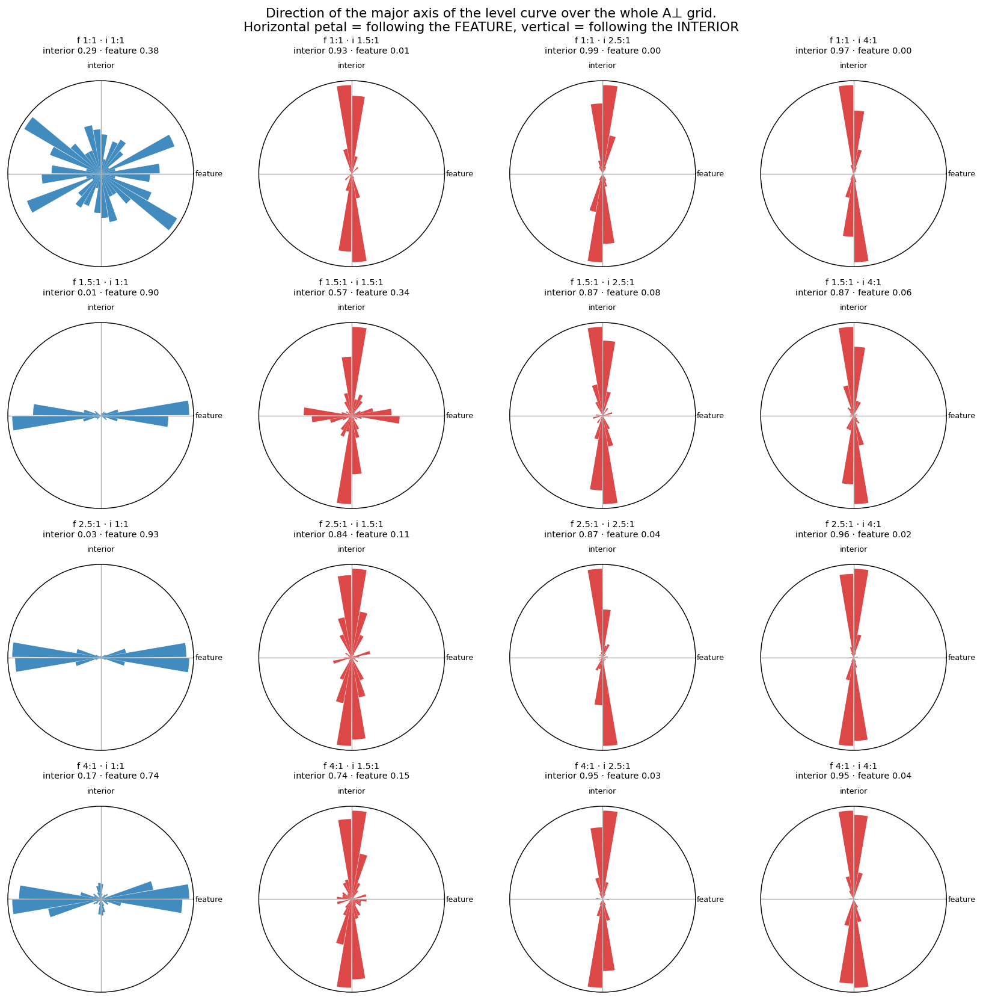

 feature  interior     source  passed  along_feature  along_interior  aspect  witness  score
     1.0       1.0          A   0.052          0.382           0.292   1.054     1.00  0.030
     1.0       1.5 A, rotated   0.728          0.008           0.929   1.303     1.00  0.045
     1.0       2.5 A, rotated   0.887          0.003           0.992   1.623     0.88  0.065
     1.0       4.0 A, rotated   0.973          0.000           0.971   1.824     0.68  0.079
     1.5       1.0          A   0.418          0.896           0.008   1.202     1.00  0.043
     1.5       1.5         A⊥   0.502          0.338           0.567   1.225     0.88  0.068
     1.5       2.5         A⊥   0.738          0.081           0.871   1.481     0.58  0.089
     1.5       4.0         A⊥   0.848          0.058           0.870   1.731     0.46  0.115
     2.5       1.0          A   0.504          0.931           0.034   1.225     0.40  0.081
     2.5       1.5         A⊥   0.576          0.108           0.838  

In [33]:
GATE = .10
fig, axes = plt.subplots(4, 4, figsize=(13, 13), subplot_kw={"projection": "polar"})
edges = np.radians(np.arange(0, 361, 10))
rows = []
for r, fa in enumerate(ASP):
    for c, ia in enumerate(ASP):
        ax = axes[r, c]; name, deg, src = GRID[r][c]
        g_all = hl[(hl.dataset_type == name) & (hl.layer_id > 0)]
        g = g_all[g_all.a2 >= GATE]
        a = (g.angle2.values + deg) % 180                 # rotation together with the dataset
        both = np.concatenate([np.radians(a), np.radians(a) + np.pi]) % (2*np.pi)
        h, _ = np.histogram(both, bins=edges); h = h / max(h.max(), 1)
        colr = gp.C_INTERIOR if ia > 1.0 else gp.C_FEATURE
        ax.bar(edges[:-1] + np.radians(5), h, width=np.radians(9.4), color=colr,
               alpha=.85, edgecolor="none")
        along = float(((a < 30) | (a > 150)).mean()) if len(a) else np.nan
        across = float(((a > 60) & (a < 120)).mean()) if len(a) else np.nan
        rows.append(dict(feature=fa, interior=ia, source=src, passed=len(g)/max(len(g_all), 1),
                         along_feature=along, along_interior=across,
                         aspect=float(g_all.aspect.median()),
                         witness=float(cells_meta.loc[name, "rate_floor"]),
                         score=float(cells_meta.loc[name, "target_median"])))
        ax.set_yticks([]); ax.set_xticks(np.radians([0, 90, 180, 270]))
        ax.set_xticklabels(["feature", "interior", "", ""], fontsize=7)
        ax.set_title(f"f {fa:g}:1 · i {ia:g}:1\ninterior {across:.2f} · feature {along:.2f}",
                     fontsize=8, pad=8)
fig.suptitle("Direction of the major axis of the level curve over the whole A⊥ grid.\n"
             "Horizontal petal = following the FEATURE, vertical = following the INTERIOR", fontsize=12)
plt.tight_layout(); plt.show()

RP = pd.DataFrame(rows)
print(RP.round(3).to_string(index=False))
core = RP[(RP.feature > 1) & (RP.interior > 1)]
# from the edge with a round interior we exclude the cell “circle in circle”: there neither
# object has an axis, and 5% of the curves pass the a2 filter
edge_f = RP[(RP.interior == 1.0) & (RP.feature > 1.0)]
edge_i = RP[(RP.feature == 1.0) & (RP.interior > 1.0)]
deg = RP[(RP.feature == 1.0) & (RP.interior == 1.0)].iloc[0]
print(f"\ndegenerate cell “circle in circle”: {deg.passed:.0%} of the curves pass the filter, "
      f"the rose is isotropic ({deg.along_feature:.2f} against {deg.along_interior:.2f})")
print(f"first column without it, interior round (control of the feature): along the feature "
      f"{edge_f.along_feature.min():.2f}–{edge_f.along_feature.max():.2f}")
print(f"first row, feature round (control of the interior): along the interior "
      f"{edge_i.along_interior.min():.2f}–{edge_i.along_interior.max():.2f}")
print(f"core 3 × 3, the objects compete: along the interior "
      f"{core.along_interior.min():.2f}–{core.along_interior.max():.2f}, along the feature "
      f"{core.along_feature.min():.2f}–{core.along_feature.max():.2f}; "
      f"the interior wins in {int((core.along_interior > core.along_feature).sum())} of {len(core)}")


**Observations.**

- **Each object on its own does set the direction.** In the first column, where the interior is
  round, the curve runs **along the feature** in 0.74–0.93 of cases. In the first row, where the feature is round,
  it runs **along the interior** in 0.93–0.99. That is, neither object is "neutral": in the
  absence of a competitor each turns the curve towards itself.
- **When they compete, the interior wins, and by a wide margin.** In the 3 × 3 core the fraction along the
  interior is **0.57–0.96** against **0.02–0.34** along the feature; the interior wins in all
  nine cells.
- **The closest score is where the interior is least elongated** (1.5:1 with a 1.5:1 feature):
  0.57 against 0.34. The more elongated the interior, the more unambiguous the answer: at 4:1 the fraction is 0.87–0.96.
- **Angular control.** In the cell "circle in circle" only 5% of the curves pass the filter on `a₂`, and the rose
  is isotropic: where there is no direction, the instrument does not invent one.
- **The fraction that passed the filter is informative in itself**: 0.41–0.50 in the column with a round
  interior and 0.73–0.97 in the others. The elongation of the curve is brought mostly by the interior,
  the feature gives a weak one.

**Conclusion.** The grid answers the question that block A could not pose, and it answers in three regimes
at once: the feature does set the direction, but only when there is no competitor; the interior always sets it;
in competition the interior wins.


## 3.3 What the models predicted

The test is on the **nine core cells** — only there do the objects compete, and only there do the
predictions of the constructions diverge. The three constructions from 2.2.3 gave close
predictions in block A and **diverge here**, because
now the objects have different axes. This is the hardest test of them in the whole experiment: a miss by a
right angle can neither be written off nor fitted away.


In [ ]:
def _angle_aspect(pts):
    desc = fourier_descriptor(torch.tensor(np.asarray(pts), dtype=torch.float32))
    return (float(np.degrees(desc["phase"][2] % np.pi)),
            float(gs.a2_to_aspect(np.array([desc["amplitude"][2]]))[0]))

rows = []
for name in sorted(cells_meta[cells_meta.block == "A⊥"].index):
    meta = cells_meta.loc[name]
    obs = RP[(RP.feature == meta.feature_aspect) & (RP.interior == meta.interior_aspect)].iloc[0]  # core
    ang_d, asp_d = _angle_aspect(sm.dilation_from_gap(name, 0.45)["curve"])
    xs, ys, F, c0 = sm.harmonic_potential(name)
    cu = sm.enclosing_level_curve(xs, ys, F, 0.40, c0)
    ang_h, asp_h = _angle_aspect(cu) if cu is not None else (np.nan, np.nan)
    ang_, r_in, r_out, centre = sm.annulus_radial(name)
    mid_line = centre + np.stack([(.5*(r_in+r_out))*np.cos(ang_),
                                  (.5*(r_in+r_out))*np.sin(ang_)], 1)
    ang_m, asp_m = _angle_aspect(mid_line)      # not 'mid': the global table of shapes
    rows.append(dict(feature=meta.feature_aspect, interior=meta.interior_aspect,
                     midline=ang_m, dilation=ang_d, potential=ang_h,
                     follows_interior_obs=float(obs.along_interior),
                     asp_dilation=asp_d, asp_potential=asp_h, asp_obs=float(obs.aspect)))
PM = pd.DataFrame(rows).sort_values(["feature", "interior"]).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
x = np.arange(len(PM))
for col, c_, mk in (("midline", "#111", "s"), ("dilation", "#e08214", "o"),
                    ("potential", "#2c7a4b", "D")):
    axes[0].plot(x, PM[col], mk, color=c_, ms=9, label=col)
axes[0].axhline(0, color=gp.C_FEATURE, lw=1.6, ls="--")
axes[0].axhline(90, color=gp.C_INTERIOR, lw=1.6, ls=":")
axes[0].text(.05, 4, "axis of the feature", fontsize=8, color=gp.C_FEATURE)
axes[0].text(.05, 83, "axis of the interior", fontsize=8, color=gp.C_INTERIOR)
axes[0].set_xticks(x, [f"{a:g}:{b:g}" for a, b in zip(PM.feature, PM.interior)], fontsize=7, rotation=90)
axes[0].set_ylabel("predicted direction, deg"); axes[0].legend(fontsize=8)
axes[0].set_title("orientation: the midline is off by 90°", fontsize=10)

axes[1].plot(x, PM.asp_obs, "o-", color="#111", lw=2.2, ms=8, label="observed")
axes[1].plot(x, PM.asp_dilation, "s--", color="#e08214", lw=1.6, ms=6, label="dilation")
axes[1].plot(x, PM.asp_potential, "D--", color="#2c7a4b", lw=1.6, ms=6, label="potential")
axes[1].set_xticks(x, [f"{a:g}:{b:g}" for a, b in zip(PM.feature, PM.interior)], fontsize=7, rotation=90)
axes[1].set_ylabel("elongation"); axes[1].legend(fontsize=8)
axes[1].set_title("magnitude: dilation overestimates, potential underestimates", fontsize=10)
fig.suptitle("Block A⊥: test of the three constructions where they diverge", fontsize=12)
plt.tight_layout(); plt.show()

print(PM.round(2).to_string(index=False))
for col in ("dilation", "potential"):
    print(f"{col}: |error| in elongation {np.abs(PM['asp_'+col] - PM.asp_obs).mean():.3f}")
U_perp = cell_uncertainty(sorted(cells_meta[cells_meta.block == "A⊥"].index))
print(f"against the uncertainty of the numbers themselves: ±{np.median(U_perp):.2f} "
      f"(bootstrap over 50 networks), range over these 9 cells "
      f"{PM.asp_obs.max() - PM.asp_obs.min():.2f}")


**Observations.**

- **The midline of the gap is off by 90°** in all nine cells: it predicts 0.1–0.2°,
  that is, "along the feature", while "along the interior" is observed. This is a refutation of the whole class
  "compromise between the shapes of the two boundaries" independent of block A, and the hardest one possible.
- **Dilation and the potential guess the orientation exactly**: 90.0° and 89.8–92.3°. Both constructions are
  local in the interior, and here this is seen directly.
- **In magnitude the same systematics as in block A persist**: dilation overestimates (1.38–2.67
  against the observed 1.23–2.20), the potential underestimates (1.01–1.52).
- **And in magnitude both miss here**: the mean error is 0.43 for dilation and 0.33 for the potential
  at an uncertainty of the numbers themselves of ±0.17 and a range over these nine cells of 0.98 — two to three times
  more than can be put down to noise. That is, both constructions get the orientation right, but the magnitude
  in the turned configuration they do not, and this has to be said plainly. Block B is harder for them than block A.

**Conclusion.** Block B confirms the division from 2.2.3 and adds a direct proof to it: the
constructions that describe the observed are local in the interior; those that average over the gap
give a wrong answer already at the level of direction.


## 3.4 What became of the witnessing

Orientation is about the shape of the curve. A separate question: what turning the interior does to the
**witnessing** itself, that is, to the structural criterion. The comparison is paired: the same feature, the same
interior, only its rotation differs.


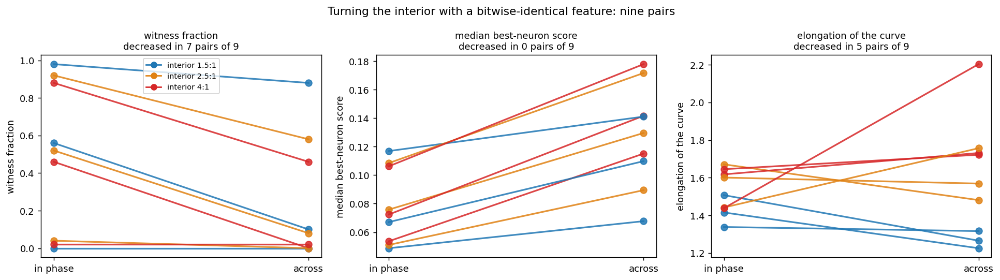

 feature  interior  witness_phase  witness_across  score_phase  score_across  asp_phase  asp_across
     1.5       1.5           0.98            0.88        0.049         0.068      1.415       1.225
     1.5       2.5           0.92            0.58        0.051         0.089      1.671       1.481
     1.5       4.0           0.88            0.46        0.054         0.115      1.617       1.731
     2.5       1.5           0.56            0.10        0.067         0.110      1.507       1.265
     2.5       2.5           0.52            0.08        0.076         0.130      1.601       1.569
     2.5       4.0           0.46            0.00        0.072         0.142      1.645       1.722
     4.0       1.5           0.00            0.00        0.117         0.141      1.338       1.316
     4.0       2.5           0.04            0.00        0.109         0.172      1.441       1.757
     4.0       4.0           0.02            0.02        0.106         0.178      1.438       2.204


In [35]:
turn_pairs = []
for fa in (1.5, 2.5, 4.0):
    for ia in (1.5, 2.5, 4.0):
        a = cells_meta[(cells_meta.block == "A") & (cells_meta.feature_aspect == fa)
                       & (cells_meta.interior_aspect == ia)].index[0]
        p = cells_meta[(cells_meta.block == "A⊥") & (cells_meta.feature_aspect == fa)
                       & (cells_meta.interior_aspect == ia)].index[0]
        ca, cp = cells_meta.loc[a], cells_meta.loc[p]
        turn_pairs.append(dict(feature=fa, interior=ia,
                          witness_phase=ca.rate_floor, witness_across=cp.rate_floor,
                          score_phase=ca.target_median, score_across=cp.target_median,
                          asp_phase=float(hl[hl.dataset_type == a].aspect.median()),
                          asp_across=float(hl[hl.dataset_type == p].aspect.median())))
PR = pd.DataFrame(turn_pairs)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (c1, c2, lab) in zip(axes, [
        ("witness_phase", "witness_across", "witness fraction"),
        ("score_phase", "score_across", "median best-neuron score"),
        ("asp_phase", "asp_across", "elongation of the curve")]):
    for _, r in PR.iterrows():
        ax.plot([0, 1], [r[c1], r[c2]], "o-", color=COL[r.interior], lw=1.8, ms=7, alpha=.85)
    ax.set_xticks([0, 1], ["in phase", "across"]); ax.set_ylabel(lab)
    ax.set_title(f"{lab}\ndecreased in {int((PR[c2] < PR[c1]).sum())} pairs of 9", fontsize=10)
axes[0].legend(handles=[plt.Line2D([], [], color=c, marker="o", label=f"interior {k:g}:1")
                        for k, c in COL.items() if k != 1.0], fontsize=8)
fig.suptitle("Turning the interior with a bitwise-identical feature: nine pairs", fontsize=12)
plt.tight_layout(); plt.show()

print(PR.round(3).to_string(index=False))
print(f"\nscore worsened in {int((PR.score_across > PR.score_phase).sum())} pairs of 9")
print(f"witness fraction fell in {int((PR.witness_across < PR.witness_phase).sum())} pairs of 9")
print(f"elongation of the curve changed in both directions: fell in "
      f"{int((PR.asp_across < PR.asp_phase).sum())}, rose in "
      f"{int((PR.asp_across > PR.asp_phase).sum())}")


**Observations.**

- **The score worsens in all nine pairs**, often twofold: 0.049 → 0.068, 0.051 → 0.089,
  0.054 → 0.115, 0.067 → 0.110, 0.076 → 0.130, 0.072 → 0.142, 0.117 → 0.141, 0.109 → 0.172,
  0.106 → 0.178. The feature meanwhile is bitwise the same.
- **The witness fraction falls in 7 pairs of 9**; in the remaining two it was already zero in phase.
  The most noticeable falls: 0.92 → 0.58, 0.88 → 0.46, 0.56 → 0.10, 0.52 → 0.08, 0.46 → 0.00.
- **And the elongation of the curve hardly changes** — it falls in 5 pairs and grows in 4. Turning the interior
  does not make the curve different in magnitude, it **turns** it.

**Conclusion, and it is central for the whole experiment.** One and the same feature circle can be made
witnessed or not **without doing anything to it**: it is enough to turn the set of the
opposite class inside it. Witnessing is a property of the **pair**, not of the feature. The mechanism
is seen in one quantity: the curve turns following the interior and stops coinciding with the
feature — while the feature itself has not changed.


## 3.5 Summary of block B

1. **The full 4 × 4 grid separates the contributions of the objects.** The edge with a round interior shows that the
   feature does set the direction (along it 0.74–0.93); the edge with a round feature that the interior sets it
   too (0.93–0.99). Both objects "know how" to turn the curve (3.2).
2. **In competition the interior wins**: in the 3 × 3 core the fraction along the interior is 0.57–0.96
   against 0.02–0.34 along the feature, in all nine cells.
3. **This refutes a whole class of models independently of block A**: the midline of the gap
   predicts a direction along the feature and is off by 90° nine times out of nine; dilation and the
   harmonic potential give 90.0° and 89.8–92.3° (3.3).
4. **The systematics of the magnitude are the same as in block A** (dilation overestimates, the potential underestimates), and both
   constructions here miss two to three times further than noise allows: 0.43 and 0.33 at an
   uncertainty of the numbers themselves of ±0.17.
5. **Turning the interior destroys witnessing with the feature unchanged**: the score is worse in 9 pairs of
   9, the witness fraction falls in 7 of 9, and the elongation of the curve meanwhile does not change systematically
   (3.4). One and the same circle can be made witnessed or not without doing anything
   to it.
6. As everywhere, these are statements about the **agreement** of quantities, not about a cause: there is no ablation.


# 4. Block C. Density of the description: a test that the effect is geometric

## Setting

Blocks A and B showed that the shape of the level curve agrees with the geometry of the pair, and proposed three
constructions that describe this agreement. All three have a common property: they are computed
**from the geometry and from nothing else**. So there is an obvious vulnerability — what if the shape of the curve
depends on something the geometry does not see?

Block C tests exactly this. Four geometries are taken from blocks A and B, and in each one varies
**how many points describe each object**, at an unchanged thousand points in total:

| points **inside** | points **on the feature** | how to read |
|---|---|---|
| **200** | 800 | the feature is described densely, the interior sparsely |
| **500** | 500 | equally — this is a cell of block A or B |
| **800** | 200 | the interior is described densely, the feature sparsely |

Further on the text always gives **the number of points inside** — 200, 500 or 800 — rather than a fraction, so as
not to have to remember in whose favour the balance is counted.

| geometry | why it is here |
|---|---|
| feature 4:1, interior round | there is no shape to carry over, only the feature works |
| feature round, interior 4:1 | the opposite, only the interior works |
| both 4:1, in phase | both pull in one direction |
| both 4:1, across | both pull in different directions — the most strained configuration |

**The key property of the design.** Within a row **the geometry is bitwise one and the same**: the same ellipses,
the same semi-axes, the same gap. Only the density of points changes. So any purely geometric
model has to predict **one and the same number** within a row. If the observed changes within a row,
the geometry is not enough — and the question is through what the density acts.


## 4.1 Datasets

Twelve configurations: four geometries (rows) × three densities (columns). Within a row the shapes coincide exactly, only the number of points on each object differs — this can be seen from how densely each colour is drawn.


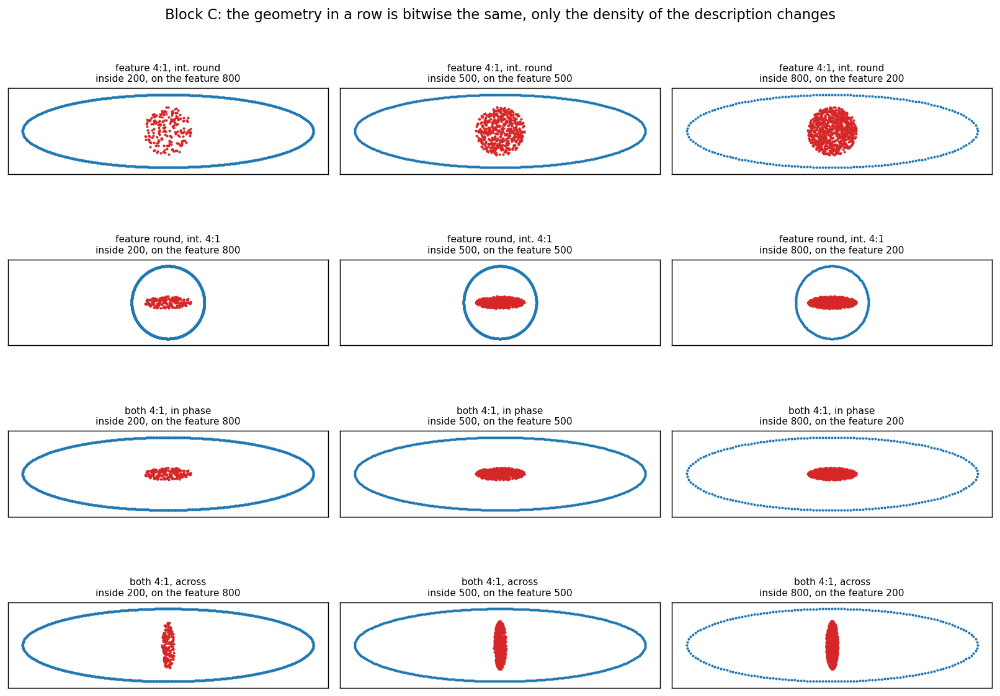

In [36]:
C_GEO = [("g5_f040_i010_s100", "feature 4:1, int. round"),
         ("g5_f010_i040_s100", "feature round, int. 4:1"),
         ("g5_f040_i040_s100", "both 4:1, in phase"),
         ("g5_f040_i040T_s100", "both 4:1, across")]
N_IN = [200, 500, 800]                      # points inside; on the feature — the rest up to 1000

def c_cell(pref, n_in):
    q = cells_meta[[n.startswith(pref) for n in cells_meta.index]]
    return q[np.isclose(q.balance, n_in/1000)].index[0]

hxC = hyC = 0.0
for pref, _ in C_GEO:
    for n_in in N_IN:
        h1, h2 = gp.cells_extent([c_cell(pref, n_in)])
        hxC, hyC = max(hxC, h1), max(hyC, h2)

fig, axes = plt.subplots(4, 3, figsize=(12.5, 9.5))
for r, (pref, lab) in enumerate(C_GEO):
    for c, n_in in enumerate(N_IN):
        ax = axes[r, c]; name = c_cell(pref, n_in)
        Xc, yc, Ac = gs.dataset_points(name)[:3]
        ax.scatter(Xc[yc == 1, 0], Xc[yc == 1, 1], s=1.6, c=gp.C_INTERIOR, zorder=1)
        ax.scatter(Ac[:, 0], Ac[:, 1], s=1.6, c=gp.C_FEATURE, zorder=2)
        ax.set_xlim(-hxC, hxC); ax.set_ylim(-hyC, hyC)
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{lab}\ninside {n_in}, on the feature {1000-n_in}", fontsize=8.5)
fig.suptitle("Block C: the geometry in a row is bitwise the same, only the density of the description changes",
             fontsize=12.5)
plt.tight_layout(); plt.show()


## 4.2 What the density does to the shape of the curve

The quantity is the same as in block A. Here it is looked at in three ways, because "the median
shifted" is too weak a statement: the shift may come from a few models, from one
rung of the ladder or from the tail of the distribution.

* **by model** — the median elongation within each of the 50 models, one point per network.
  If the shift is population-wide, the whole cloud will shift; if a few networks produce it, we will see that;
* **by rung of the ladder** — whether the whole family of level curves moves or only its edge;
* **over the distribution as a whole** — what happens to the right group (elongation above 2).


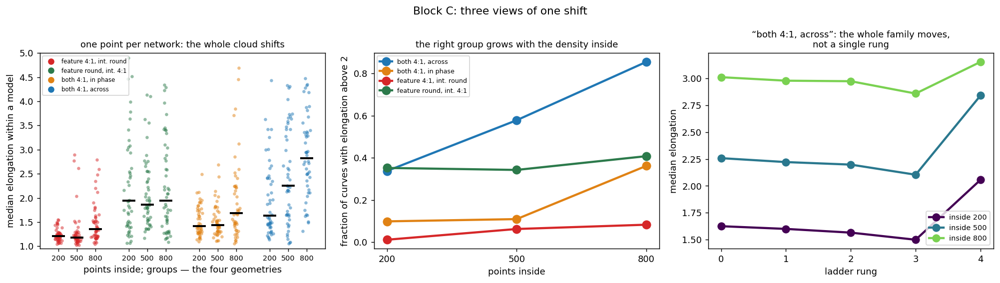

median over models [10th – 90th percentile] and the test of the shift 200 against 800:
  feature 4:1, int. round  1.21 [1.09–1.45] | 1.18 [1.08–1.52] | 1.35 [1.16–2.13]   p = 1.8e-04, models at 800 above the median at 200: 0.74
  feature round, int. 4:1  1.94 [1.23–4.47] | 1.86 [1.37–2.92] | 1.94 [1.26–3.48]   p = 7.1e-01, models at 800 above the median at 200: 0.50
  both 4:1, in phase       1.42 [1.18–1.92] | 1.44 [1.23–1.95] | 1.68 [1.18–3.18]   p = 8.9e-03, models at 800 above the median at 200: 0.74
  both 4:1, across         1.63 [1.26–3.27] | 2.25 [1.25–3.73] | 2.82 [1.65–4.19]   p = 1.7e-06, models at 800 above the median at 200: 0.92

fraction of curves above aspect 2:
inside                    200   500   800
geometry                                 
both 4:1, across         0.34  0.58  0.86
both 4:1, in phase       0.10  0.11  0.36
feature 4:1, int. round  0.01  0.06  0.08
feature round, int. 4:1  0.35  0.34  0.41


In [37]:
from scipy.stats import mannwhitneyu
GC = {lab: c for (_, lab), c in zip(C_GEO, ["#d62728", "#2c7a4b", "#e08214", "#1f77b4"])}
rowsC = []
for pref, lab in C_GEO:
    for n_in in N_IN:
        name = c_cell(pref, n_in)
        g = hl[(hl.dataset_type == name) & (hl.layer_id > 0)]
        gg = g[g.a2 >= .10]; a = gg.angle2.values
        per = g.groupby("model_index").aspect.median()
        rowsC.append(dict(geometry=lab, inside=n_in, cell=name, curves=len(g),
                          aspect=float(g.aspect.median()), r0=float(g.r0.median()),
                          per_model=per, above2=float((g.aspect > 2).mean()),
                          along=float(((a < 30) | (a > 150)).mean()) if len(a) else np.nan,
                          across=float(((a > 60) & (a < 120)).mean()) if len(a) else np.nan,
                          passed=len(gg)/max(len(g), 1),
                          witness=float(cells_meta.loc[name, "rate_floor"]),
                          score=float(cells_meta.loc[name, "target_median"]),
                          floor=float(cells_meta.loc[name, "floor"])))
CC = pd.DataFrame(rowsC)

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))
rng = np.random.default_rng(4)
xpos = 0; ticks, labels = [], []  # not 'pos': that is the name of the global table
for pref, lab in C_GEO:
    for k, n_in in enumerate(N_IN):
        v = CC[(CC.geometry == lab) & (CC.inside == n_in)].per_model.iloc[0]
        axes[0].scatter(rng.normal(xpos, .09, len(v)), v, s=13, alpha=.5, color=GC[lab],
                        linewidths=0)
        axes[0].plot([xpos-.3, xpos+.3], [v.median()]*2, color="k", lw=2.2, zorder=5)
        ticks.append(xpos); labels.append(str(n_in)); xpos += 1
    xpos += .8
axes[0].set_xticks(ticks, labels, fontsize=8)
axes[0].set_ylabel("median elongation within a model"); axes[0].set_ylim(.95, 5)
axes[0].set_xlabel("points inside; groups — the four geometries")
axes[0].set_title("one point per network: the whole cloud shifts", fontsize=10)
axes[0].legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c, label=l)
                        for l, c in GC.items()], fontsize=6.5)

hot = "both 4:1, across"
for lab, g in CC.groupby("geometry"):
    g = g.sort_values("inside")
    axes[1].plot(g.inside, g.above2, "o-", color=GC[lab], lw=2.4, ms=9, label=lab)
axes[1].set_xticks(N_IN); axes[1].set_xlabel("points inside")
axes[1].set_ylabel("fraction of curves with elongation above 2"); axes[1].legend(fontsize=7)
axes[1].set_title("the right group grows with the density inside", fontsize=10)

for n_in in N_IN:
    name = c_cell(dict((l, p) for p, l in C_GEO)[hot], n_in)
    g = hl[(hl.dataset_type == name) & (hl.layer_id > 0)]
    v = g.groupby("rung").aspect.median()
    axes[2].plot(v.index, v.values, "o-", lw=2.4, ms=8,
                 color=plt.cm.viridis((n_in-200)/600*.8), label=f"inside {n_in}")
axes[2].set_xticks(range(5)); axes[2].set_xlabel("ladder rung")
axes[2].set_ylabel("median elongation"); axes[2].legend(fontsize=8)
axes[2].set_title(f"“{hot}”: the whole family moves,\nnot a single rung", fontsize=10)
fig.suptitle("Block C: three views of one shift", fontsize=12)
plt.tight_layout(); plt.show()

print("median over models [10th – 90th percentile] and the test of the shift 200 against 800:")
for pref, lab in C_GEO:
    line = []
    for n_in in N_IN:
        v = CC[(CC.geometry == lab) & (CC.inside == n_in)].per_model.iloc[0]
        line.append(f"{v.median():.2f} [{v.quantile(.1):.2f}–{v.quantile(.9):.2f}]")
    v2 = CC[(CC.geometry == lab) & (CC.inside == 200)].per_model.iloc[0]
    v8 = CC[(CC.geometry == lab) & (CC.inside == 800)].per_model.iloc[0]
    pv = mannwhitneyu(v2, v8)[1]
    print(f"  {lab:24s} " + " | ".join(line) +
          f"   p = {pv:.1e}, models at 800 above the median at 200: {(v8 > v2.median()).mean():.2f}")
print("\nfraction of curves above aspect 2:")
print(CC.pivot(index="geometry", columns="inside", values="above2").round(2).to_string())


**Observations.**

- **The shift is population-wide, not from a few networks.** In "both 4:1, across" the median over models goes
  **1.63 → 2.25 → 2.82**, and at 800 points inside **92% of the models** lie above the median at 200
  (p = 2·10⁻⁶). In "both 4:1, in phase" and in "feature 4:1, interior round" — 74% of the models and
  p = 9·10⁻³ and 2·10⁻⁴.
- **Exactly one geometry does not react** — "feature round, interior 4:1": 1.94 → 1.86 → 1.94,
  p = 0.71, exactly half of the models above. This is not noise in the data but a meaningful exception, and C.4
  shows how it differs from the others.
- **The whole family of level curves moves**, not the edge: in "across" the median by rung goes
  1.63/1.60/1.57/1.50/2.06 at 200 points inside and 3.01/2.98/2.97/2.86/3.15 at 800. The difference
  is roughly constant along the ladder.
- **The right group grows the most.** The fraction of curves with elongation above 2 in "across" goes
  **0.34 → 0.58 → 0.86**: at 800 points inside almost all curves are elongated twofold or more. In
  "in phase" — 0.10 → 0.11 → 0.36.

**Conclusion.** The density of the description — a quantity that does not exist in the geometry at all — moves the shape of the level
curve, and moves it strongly: in the most strained geometry the median grows almost twofold, and the fraction
of strongly elongated curves two and a half times. This is a direct limitation on all three constructions
from 2.2.3: **the shape cannot be derived from the geometry alone**.


## 4.3 Direction

Shape is not only magnitude but also direction. The roses are read as in 2.5 and 3.2: a circular
histogram of the direction of the major axis over all curves of the cell, each measurement plotted twice,
each panel normalised to its own maximum.


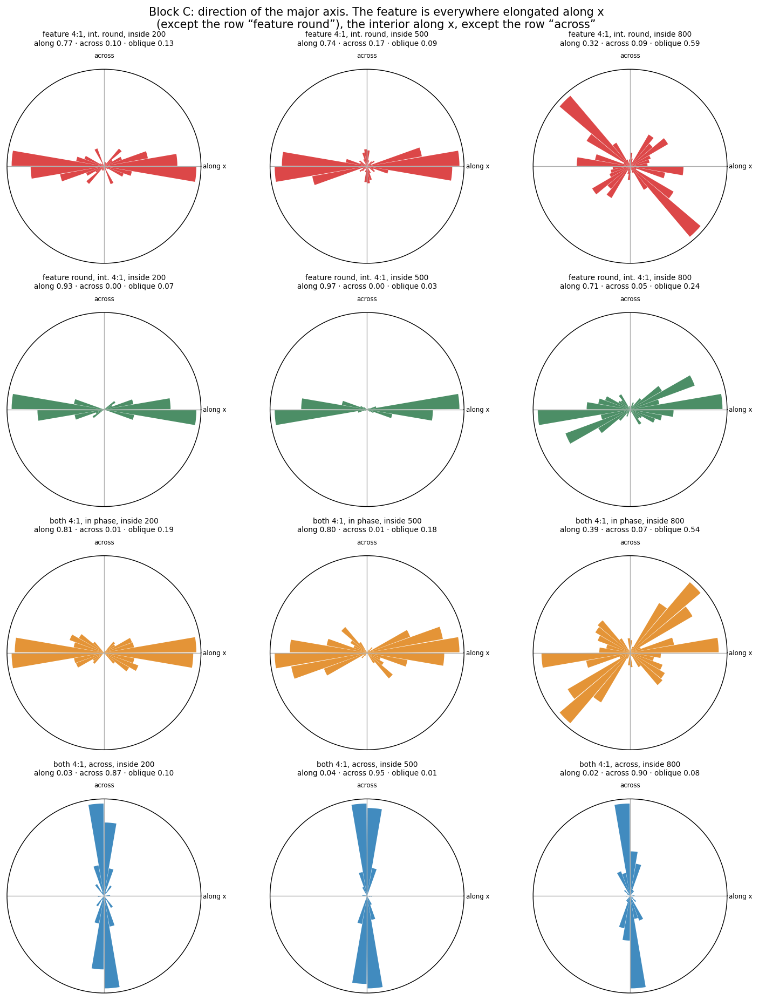

               geometry  inside  along  across  passed
feature 4:1, int. round     200  0.773   0.096   0.504
feature 4:1, int. round     500  0.740   0.170   0.412
feature 4:1, int. round     800  0.324   0.091   0.659
feature round, int. 4:1     200  0.930   0.002   0.866
feature round, int. 4:1     500  0.971   0.000   0.973
feature round, int. 4:1     800  0.712   0.046   0.900
     both 4:1, in phase     200  0.806   0.006   0.863
     both 4:1, in phase     500  0.805   0.011   0.887
     both 4:1, in phase     800  0.393   0.067   0.878
       both 4:1, across     200  0.030   0.867   0.922
       both 4:1, across     500  0.037   0.949   0.886
       both 4:1, across     800  0.022   0.899   0.997

oblique (neither along nor across):
inside                    200   500   800
geometry                                 
both 4:1, across         0.10  0.01  0.08
both 4:1, in phase       0.19  0.18  0.54
feature 4:1, int. round  0.13  0.09  0.59
feature round, int. 4:1  0.07  0.03  0

In [38]:
fig, axes = plt.subplots(4, 3, figsize=(11.5, 14.5), subplot_kw={"projection": "polar"})
edges = np.radians(np.arange(0, 361, 10))
for r, (pref, lab) in enumerate(C_GEO):
    for c, n_in in enumerate(N_IN):
        ax = axes[r, c]; name = c_cell(pref, n_in)
        g_all = hl[(hl.dataset_type == name) & (hl.layer_id > 0)]
        g = g_all[g_all.a2 >= .10]; a = g.angle2.values
        both = np.concatenate([np.radians(a), np.radians(a) + np.pi]) % (2*np.pi)
        h, _ = np.histogram(both, bins=edges); h = h / max(h.max(), 1)
        ax.bar(edges[:-1] + np.radians(5), h, width=np.radians(9.4), color=GC[lab],
               alpha=.85, edgecolor="none")
        along = float(((a < 30) | (a > 150)).mean()); across = float(((a > 60) & (a < 120)).mean())
        obl = 1 - along - across
        ax.set_yticks([]); ax.set_xticks(np.radians([0, 90, 180, 270]))
        ax.set_xticklabels(["along x", "across", "", ""], fontsize=6.5)
        ax.set_title(f"{lab}, inside {n_in}\nalong {along:.2f} · across {across:.2f} · "
                     f"oblique {obl:.2f}", fontsize=7.5, pad=7)
fig.suptitle("Block C: direction of the major axis. The feature is everywhere elongated along x\n"
             "(except the row “feature round”), the interior along x, except the row “across”",
             fontsize=11.5)
plt.tight_layout(); plt.show()

print(CC[["geometry", "inside", "along", "across", "passed"]].round(3).to_string(index=False))
print("\noblique (neither along nor across):")
CC2o = CC.assign(oblique=lambda d: 1 - d.along - d.across)
print(CC2o.pivot(index="geometry", columns="inside", values="oblique").round(2).to_string())


**Observations.**

- **In "both 4:1, across" the direction does not change at all**: the fraction across 0.87 → 0.95 → 0.90 with the
  fraction along 0.03 → 0.04 → 0.02. That is, where the density changes the **magnitude** of the elongation most,
  it does not touch its **direction**. The two characteristics of shape part ways, and this is
  important: it means the density does not act by "turning" the curve.
- **In the three geometries where both axes are horizontal, the order drops at 800 points inside**:
  the fraction along goes 0.81 → 0.81 → 0.39, 0.77 → 0.74 → 0.32, 0.93 → 0.97 → 0.71. The curves that dropped out
  go **not across** (the fraction across stays 0.02–0.09) but **into oblique directions**, and this is
  visible on the roses as four inclined petals.
- **This is not "blurring" but a quite definite direction — about 45°.** The fraction of curves in the sectors
  30–60° and 120–150° goes **0.13 → 0.09 → 0.59** (feature 4:1, interior round),
  **0.19 → 0.18 → 0.54** (both 4:1, in phase) and **0.07 → 0.03 → 0.24** (feature round, interior
  4:1). At 200 and 500 points inside there are almost no oblique ones, at 800 there are three to six times
  more. That is, the direction is not lost but **switches** to the diagonal.
- **And this holds even where both objects are elongated along one axis** ("both 4:1, in phase"): one would
  think nothing pulls the curve diagonally there, and still at 800 points inside more than half of the
  curves go off at 45°. The only geometry without the jump is "both 4:1, across"
  (0.10 → 0.01 → 0.08): there the interior holds the direction rigidly.

What generates the diagonal cannot be seen from these data. It is worth noting as **a separate phenomenon**,
common to three geometries of four and appearing exactly at a dense interior.
- **Curves with noticeable elongation meanwhile become more numerous**: the fraction that passed the filter on `a₂`
  at 800 points inside is higher than at 200 in all four geometries (by 0.02–0.16), although the course
  through 500 is not monotone. That is, at a dense interior the curves are more elongated, but their direction is
  less ordered — except in the case where the interior itself sets it rigidly.

**Conclusion.** The density acts on the magnitude of the elongation and on its order, but does not
turn the curve: the direction is still set by the objects.


## 4.4 Through what the density acts: where the field makes its transition

> **The weight of this section.** The main result of block C is the previous one: the density moves the shape at an
> unchanged geometry, and so the shape cannot be derived from the geometry. Below is an attempt to say **through
> what** it acts, and this observation is **secondary**: the quantity it rests on is
> indirect, is interpreted with caveats and is not an independent result. It should be read
> as a plausible explanation consistent with the law from 2.2.3, not as one more conclusion of the
> experiment.

The density of points cannot change the geometry — within a row it is bitwise one and the same. So it
changes something in the field itself, and the shape follows that. Below it is shown that this "something" is **the place
where the field makes the transition between the classes**.

### What the `r₀` of a described curve actually measures

Here it is important not to say more than there is, and in the first version of this section I did say more.

A neuron has a level curve at **every** value of the field, that is, one passes through every point of the
plane. "The mean radius of the level curves" is therefore a meaningless quantity — there are infinitely many of them.
Exactly **five** are described, and they are chosen by the ladder rule (1.5): the ends are the mean value of the
field **on the boundary of the interior** and **on the feature**, the interval between them is divided into four equal parts.

Hence the exact meaning of the quantity. Rung `k` is the curve on which the field has travelled **`k/4` of the way**
from its value on the interior to its value on the feature. Its radius `r₀` answers the question:
**at what distance from the centre the field travels this fraction of the way.** If the field changes sharply and close
to the interior, all five rungs gather there; if the transition is stretched out, they spread apart.

That is, the `r₀` of the rungs measures not "where the level curves are" but **where the field has its fold** — and this is exactly why
the quantity is interesting: the fold is the place where the neuron separates one class from the other, and its
position is a property of the solution, not of the labelling. The formulation from the first version of this section was
wrong, and it is corrected here.

### Two objections that have to be removed before any conclusions

**First: is this not selection?** Many neurons do not have all five rungs — the outer one is available only
for 5–17%. If different rungs are lost at different densities, "the median `r₀`" will move
by itself, without any shift of the field.

**Second: is this not composition?** Even with equal availability, the median over the pooled
sample mixes the rungs, and its shift may come from a change in the proportions.

Both objections are removed by one check — compare `r₀` **separately on each rung**. Then
like is compared with like, and neither selection nor composition has anything to do with it.


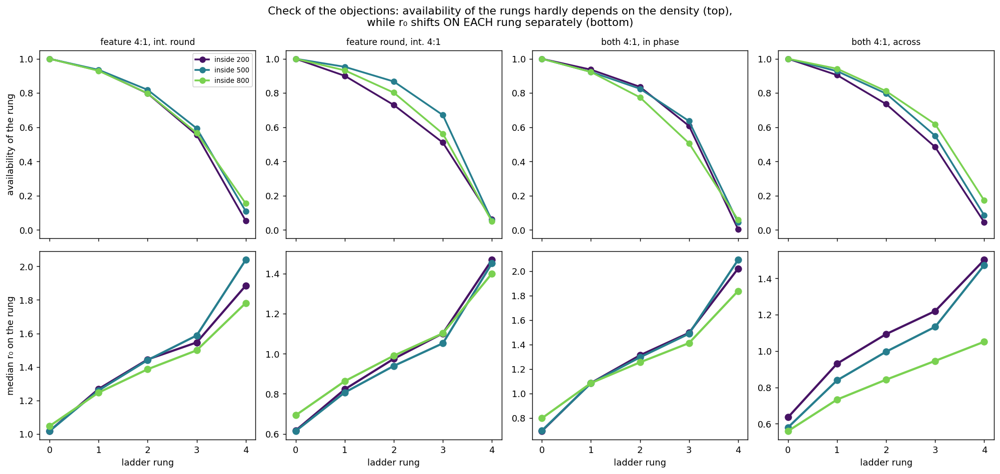

r₀ by rung (inside 200 / 500 / 800):
  feature 4:1, int. round
    inside 200: 1.018 1.269 1.445 1.546 1.885
    inside 500: 1.018 1.261 1.441 1.588 2.039
    inside 800: 1.047 1.247 1.387 1.499 1.782
  feature round, int. 4:1
    inside 200: 0.617 0.822 0.975 1.102 1.469
    inside 500: 0.614 0.806 0.939 1.052 1.452
    inside 800: 0.693 0.863 0.990 1.102 1.401
  both 4:1, in phase
    inside 200: 0.692 1.085 1.312 1.495 2.020


    inside 500: 0.696 1.083 1.295 1.488 2.091
    inside 800: 0.797 1.084 1.254 1.412 1.837
  both 4:1, across
    inside 200: 0.635 0.931 1.093 1.220 1.501
    inside 500: 0.580 0.839 0.996 1.133 1.472
    inside 800: 0.560 0.733 0.843 0.946 1.051

“both 4:1, across”: shift of r₀ on each rung -0.076 -0.198 -0.251 -0.274 -0.450 — all five in one direction
availability of the outer rung at 800 is not lower but HIGHER than at 200, so selection would work against the observed shift


In [39]:
# first the check: availability of the rungs and r0 SEPARATELY on every rung
fig, axes = plt.subplots(2, 4, figsize=(15.5, 7.4), sharex=True)
DENS = plt.cm.viridis(np.linspace(.05, .8, 3))
for c, (pref, lab) in enumerate(C_GEO):
    for n_in, col in zip(N_IN, DENS):
        name = c_cell(pref, n_in)
        g = hl[(hl.dataset_type == name) & (hl.layer_id > 0)]
        tot = g.groupby(["model_index", "layer_id", "coord_id"]).ngroups
        axes[0, c].plot(range(5), (g.groupby("rung").size()/tot).reindex(range(5)).values,
                        "o-", color=col, lw=2.0, ms=6, label=f"inside {n_in}")
        axes[1, c].plot(range(5), g.groupby("rung").r0.median().reindex(range(5)).values,
                        "o-", color=col, lw=2.4, ms=7)
    axes[0, c].set_ylim(-.05, 1.05); axes[0, c].set_title(lab, fontsize=9.5)
    axes[1, c].set_xticks(range(5)); axes[1, c].set_xlabel("ladder rung")
axes[0, 0].set_ylabel("availability of the rung"); axes[0, 0].legend(fontsize=7.5)
axes[1, 0].set_ylabel("median r₀ on the rung")
fig.suptitle("Check of the objections: availability of the rungs hardly depends on the density (top),\n"
             "while r₀ shifts ON EACH rung separately (bottom)", fontsize=12)
plt.tight_layout(); plt.show()

print("r₀ by rung (inside 200 / 500 / 800):")
for pref, lab in C_GEO:
    print(f"  {lab}")
    for n_in in N_IN:
        g = hl[(hl.dataset_type == c_cell(pref, n_in)) & (hl.layer_id > 0)]
        v = g.groupby("rung").r0.median().reindex(range(5))
        print(f"    inside {n_in}: " + " ".join(f"{x:.3f}" for x in v))
hotname = dict((l, p) for p, l in C_GEO)["both 4:1, across"]
g2 = hl[(hl.dataset_type == c_cell(hotname, 200)) & (hl.layer_id > 0)].groupby("rung").r0.median()
g8 = hl[(hl.dataset_type == c_cell(hotname, 800)) & (hl.layer_id > 0)].groupby("rung").r0.median()
print(f"\n“both 4:1, across”: shift of r₀ on each rung "
      f"{' '.join(f'{d:+.3f}' for d in (g8 - g2))} — all five in one direction")
print("availability of the outer rung at 800 is not lower but HIGHER than at 200, "
      "so selection would work against the observed shift")


**The objections are removed.**

- **The availability of the rungs hardly depends on the density**: 1.00 / 0.93 / 0.80 / 0.57 / 0.05–0.17
  in all twelve cells. The only systematic difference is the outer rung, and at
  800 points inside it is available **more often** (0.05 → 0.15 and 0.05 → 0.17). The outer rung is the most
  distant one, so selection would pull the median **outwards**, while the shift observed is **inwards**: the artefact
  would work against the effect, not in its favour.
- **The shift is present on each rung separately.** In "both 4:1, across" from 200 to 800 points
  inside: 0.635 → 0.560, 0.931 → 0.733, 1.093 → 0.843, 1.220 → 0.946, 1.501 → 1.051 — **all five
  rungs move inwards**, and the further out the rung, the more strongly. This cannot be explained by composition.
- **In the unresponsive geometry** ("feature round, interior 4:1") the rungs move in the
  opposite direction and weakly: 0.617 → 0.693, 0.822 → 0.863, 0.975 → 0.990. The elongation there did not
  change either.

So the quantity measures a real property of the field, not a property of the procedure of description. Further on one can
look at the median over all rungs as a summary — with the caveat that it has been confirmed rung
by rung.


### The chain we test

1. The density does not change the geometry — within a row it is bitwise one and the same.
2. But it does change **where the field makes its transition**: the more points inside, the closer to the
   interior the fold gathers, that is, the smaller the `r₀` of each rung.
3. And the shape of the curve, as established in 2.2.3, is determined by **how far the curve has moved away from the
   interior**: close — almost a copy of the interior, far — almost a circle.
4. So **density → position of the fold → shape**, and the density does not act on the shape directly.

Below this is seen on the curves themselves, and then checked by a number.


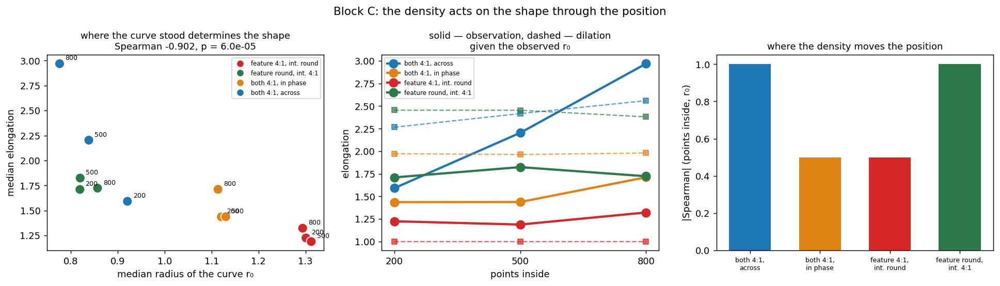

both 4:1, across         r₀ 0.921 → 0.838 → 0.776 | obs 1.59 → 2.20 → 2.97 | model 2.27 → 2.42 → 2.56
both 4:1, in phase       r₀ 1.121 → 1.130 → 1.114 | obs 1.44 → 1.44 → 1.71 | model 1.97 → 1.96 → 1.98
feature 4:1, int. round  r₀ 1.301 → 1.312 → 1.294 | obs 1.22 → 1.19 → 1.32 | model 1.00 → 1.00 → 1.00
feature round, int. 4:1  r₀ 0.819 → 0.820 → 0.857 | obs 1.71 → 1.82 → 1.72 | model 2.45 → 2.45 → 2.38

Spearman(r₀, elongation) over 12 cells: -0.902
Spearman(points inside, r₀) within geometries: both 4:1, across -1.0, both 4:1, in phase -0.5, feature 4:1, int.  -0.5, feature round, int +1.0
mean |error| of the model on block C: 0.450


In [40]:
obsC = CC.set_index("cell")[["r0", "aspect"]].rename(columns={"aspect": "aspect"})
DC = gs.dilation_model(obsC)
CC3 = CC.merge(DC[["dataset_type", "predicted_aspect", "delta"]],
               left_on="cell", right_on="dataset_type")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
axes[0].scatter(CC3.r0, CC3.aspect, s=110, c=[GC[l] for l in CC3.geometry],
                edgecolor="white", zorder=3)
for _, r in CC3.iterrows():
    axes[0].annotate(int(r.inside), (r.r0, r.aspect), fontsize=7,
                     textcoords="offset points", xytext=(6, 4))
rho, pv = spearmanr(CC3.r0, CC3.aspect)
axes[0].set_xlabel("median radius of the curve r₀"); axes[0].set_ylabel("median elongation")
axes[0].set_title(f"where the curve stood determines the shape\nSpearman {rho:+.3f}, p = {pv:.1e}",
                  fontsize=10)
axes[0].legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c, label=l)
                        for l, c in GC.items()], fontsize=6.5)

for lab, g in CC3.groupby("geometry"):
    g = g.sort_values("inside")
    axes[1].plot(g.inside, g.aspect, "o-", color=GC[lab], lw=2.4, ms=9, label=lab)
    axes[1].plot(g.inside, g.predicted_aspect, "s--", color=GC[lab], lw=1.3, ms=6, alpha=.7)
axes[1].set_xticks(N_IN); axes[1].set_xlabel("points inside"); axes[1].set_ylabel("elongation")
axes[1].legend(fontsize=6.5)
axes[1].set_title("solid — observation, dashed — dilation\ngiven the observed r₀",
                  fontsize=10)

axes[2].bar(range(4), [abs(spearmanr(g.sort_values("inside").inside,
                                     g.sort_values("inside").r0)[0])
                       for _, g in CC3.groupby("geometry")],
            color=[GC[l] for l, _ in CC3.groupby("geometry")], width=.6)
axes[2].set_xticks(range(4), [l.replace(", ", ",\n") for l, _ in CC3.groupby("geometry")],
                   fontsize=7)
axes[2].set_ylabel("|Spearman| (points inside, r₀)"); axes[2].set_ylim(0, 1.05)
axes[2].set_title("where the density moves the position", fontsize=10)
fig.suptitle("Block C: the density acts on the shape through the position", fontsize=12)
plt.tight_layout(); plt.show()

for lab, g in CC3.groupby("geometry"):
    g = g.sort_values("inside")
    print(f"{lab:24s} r₀ {' → '.join(f'{x:.3f}' for x in g.r0)} | "
          f"obs {' → '.join(f'{x:.2f}' for x in g.aspect)} | "
          f"model {' → '.join(f'{x:.2f}' for x in g.predicted_aspect)}")
print(f"\nSpearman(r₀, elongation) over 12 cells: {spearmanr(CC3.r0, CC3.aspect)[0]:+.3f}")
print("Spearman(points inside, r₀) within geometries: " + ", ".join(
    f"{l[:18]} {spearmanr(g.inside, g.r0)[0]:+.1f}" for l, g in CC3.groupby("geometry")))
print(f"mean |error| of the model on block C: "
      f"{np.abs(CC3.predicted_aspect - CC3.aspect).mean():.3f}")


**Observations.**

- **The fold shifts.** The picture shows three cells of one geometry: at 200 points inside the family
  stands at `r₀ = 0.92`, at 800 at `0.78`, that is, roughly **16% closer to the interior**.
  The shapes of the objects meanwhile are bitwise the same.
- **The position explains the shape almost entirely.** Over the twelve cells of the block
  Spearman(`r₀`, elongation) = **−0.90**: the closer the fold to the interior, the more elongated the curves.
  This is exactly what the dilation construction says, and here it is tested **within one geometry**,
  where there is nothing else to change.
- **The density moves the fold where, and only where, it moves the shape.** The rank link "points
  inside → `r₀`" equals −1.0 in "across", −0.5 in two geometries and **+1.0 in "feature round,
  interior 4:1"** — exactly in the one where the elongation **did not change** (p = 0.71 from C.2).
  The exception coinciding on two independent signs is a strong argument for the chain.
- **The model, given the observed position, reproduces the direction but not the magnitude**:
  2.27 → 2.42 → 2.56 against the observed 1.59 → 2.20 → 2.97. The position is a necessary part of the
  explanation, but not a sufficient one: the observed growth is three times steeper than predicted.
- **The mean error of the model on block C is 0.45**, noticeably worse than on block A.

**Conclusion.** The density of the description acts on the shape **not directly**: it shifts the place where the field
makes its transition — towards where there are more points — and the shape follows this position by the law
found in 2.2.3 on pure geometry. The correct formulation: **the shape is a function of where the
fold has settled**, and where it has settled is determined both by the geometry of the pair and by the distribution of the data.

**What this quantity does not say.** The `r₀` of a rung is a characteristic of **one** curve out of an
infinite family, chosen by a rule on the value of the field. It does not describe the field as a whole and is not
"the size of the level curves of a neuron"; it says only at what distance the field travels
a given fraction of the way between the classes. Everything said above is about this quantity and about no other.


## 4.5 Witnessing and score

Finally: what the density does to the structural criterion, that is, to what the experiment
was started for.


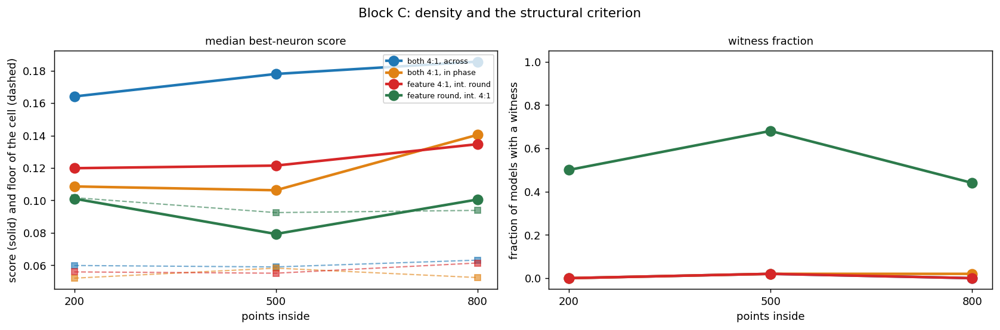

               geometry  inside  score  floor  witness
feature 4:1, int. round     200  0.120  0.056     0.00
feature 4:1, int. round     500  0.121  0.055     0.02
feature 4:1, int. round     800  0.135  0.061     0.00
feature round, int. 4:1     200  0.101  0.102     0.50
feature round, int. 4:1     500  0.079  0.092     0.68
feature round, int. 4:1     800  0.101  0.094     0.44
     both 4:1, in phase     200  0.109  0.052     0.00
     both 4:1, in phase     500  0.106  0.058     0.02
     both 4:1, in phase     800  0.140  0.052     0.02
       both 4:1, across     200  0.164  0.060     0.00
       both 4:1, across     500  0.178  0.059     0.02
       both 4:1, across     800  0.186  0.063     0.00

score at 800 points inside is worse than at 200 in 3 geometries of 4
the floor of the cell meanwhile hardly moves: range within geometries {'both 4:1, across': 0.004, 'both 4:1, in phase': 0.006, 'feature 4:1, int. round': 0.006, 'feature round, int. 4:1': 0.009}


In [41]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for lab, g in CC3.groupby("geometry"):
    g = g.sort_values("inside")
    axes[0].plot(g.inside, g.score, "o-", color=GC[lab], lw=2.4, ms=9, label=lab)
    axes[0].plot(g.inside, g.floor, "s--", color=GC[lab], lw=1.2, ms=5, alpha=.6)
axes[0].set_xticks(N_IN); axes[0].set_xlabel("points inside")
axes[0].set_ylabel("score (solid) and floor of the cell (dashed)"); axes[0].legend(fontsize=7)
axes[0].set_title("median best-neuron score", fontsize=10)
for lab, g in CC3.groupby("geometry"):
    g = g.sort_values("inside")
    axes[1].plot(g.inside, g.witness, "o-", color=GC[lab], lw=2.4, ms=9)
axes[1].set_xticks(N_IN); axes[1].set_xlabel("points inside")
axes[1].set_ylabel("fraction of models with a witness"); axes[1].set_ylim(-.05, 1.05)
axes[1].set_title("witness fraction", fontsize=10)
fig.suptitle("Block C: density and the structural criterion", fontsize=12)
plt.tight_layout(); plt.show()

print(CC3[["geometry", "inside", "score", "floor", "witness"]].round(3).to_string(index=False))
worse = sum(int(g.sort_values("inside").score.iloc[-1] > g.sort_values("inside").score.iloc[0])
            for _, g in CC3.groupby("geometry"))
print(f"\nscore at 800 points inside is worse than at 200 in {worse} geometries of 4")
print(f"the floor of the cell meanwhile hardly moves: range within geometries "
      f"{CC3.groupby('geometry').floor.apply(lambda s: s.max()-s.min()).round(3).to_dict()}")


**Observations.**

- **The score worsens as points are moved from the feature inside, in all four
  geometries**: 0.109 → 0.140,
  0.164 → 0.186, 0.120 → 0.135 and 0.101 → 0.101 (the last through a minimum of 0.079 at equal
  density). The floor of the cell meanwhile hardly moves (range 0.004–0.010), that is, the worsening
  is real, not a shift of the scale.
- **The witness fraction is zero almost everywhere**, because in three geometries of four the feature is elongated
  and there is nothing to witness. The only live one is "feature round, interior 4:1", and there the fraction
  is non-monotone: **0.50 → 0.68 → 0.44**, with a maximum at equal density.
- This maximum agrees with what was found in experiment 4: an equal number of points on the objects is
  not a neutral point but the best one for the detector.


## 4.6 Summary of block C

1. **The density of the description moves the shape of the level curve** at a bitwise identical geometry: in the most
   strained geometry the median grows **1.59 → 2.97**, the fraction of strongly elongated curves
   **0.34 → 0.86**. The shift is population-wide (92% of the models) and covers the whole family of rungs.
2. **This is a direct limitation on the constructions from 2.2.3**: the shape cannot be derived from the geometry alone.
3. **Secondary, and with caveats — on what it acts through.** The quantity that catches this is the radius
   of a rung of the ladder: rung `k` is the curve on which the field has travelled `k/4` of the way between the classes,
   and its radius says at what distance this happened. Spearman(`r₀`, elongation) = **−0.90**
   over twelve cells; the rank link "points inside → `r₀`" is negative where the elongation
   grows, and **positive exactly in the geometry where the elongation did not change**. The shift has been checked
   **on each rung separately**, so neither selection of rungs nor composition
   explains it — all the more so since the availability of the outer rung is higher at a dense interior, that is,
   the artefact would work against the effect.
4. **The direction meanwhile does not change**: in "across" the fraction of curves across stays at 0.87–0.95.
   The density changes the magnitude of the elongation and its order, but does not turn the curve.
5. **The position is not enough for the magnitude**: the model, given the observed `r₀`, gives a growth of
   2.27 → 2.56 against the observed 1.59 → 2.97.
6. **The score worsens as points are moved from the feature inside** (200 → 800 points inside) in all
   four geometries with an almost motionless
   floor; the witness fraction is largest at equal density.
7. **Diagonal directions.** At 800 points inside, in three geometries of four more than
   half of the curves go off at ≈45° (the fraction of oblique ones 0.13 → 0.59, 0.19 → 0.54, 0.07 → 0.24), including
   where both objects are elongated along one axis. A stable and unexplained phenomenon.
8. **The formulation after block C.** Firm: the shape of the level curve **is not a function of the
   geometry of the pair alone** — at a bitwise identical geometry it changes twofold depending on how the
   points are distributed. Plausible, but secondary: the density acts not on the shape directly but on where the
   field makes its transition, and the shape follows this by the law from 2.2.3. Blocks A and B measured
   the geometric half with the other one fixed.


# 5. Block D. Position: what happens when the objects stop being concentric

## Setting

All the previous blocks kept the objects **concentric**. This is convenient, and it is also a limitation: as long as the
centres coincide, the pair has no distinguished direction of displacement, and the question "where will the curve stand"
has no content — it will stand around the common centre. Block D removes this limitation.

**Twenty-three cells.** Five geometries of the pair × two directions of offset × three positions:

| geometry of the pair | what is special about it |
|---|---|
| circle in circle | neither object has a distinguished direction |
| circle in ellipse | only the feature has a direction |
| ellipse in circle | only the interior has a direction |
| ellipse in ellipse | both along one axis |
| ellipse ⊥ ellipse | the axes of the objects are perpendicular |

The directions of offset are **along** the long axis of the feature (the x axis) and **across** it (the y axis). The positions are 0%,
50% and 100% of the **largest offset this pair admits**: the interior has to stay
inside the feature with a gap. The fraction is needed because the absolute room differs sevenfold: along x with an
elongated feature the interior can be moved by 5.25, across only by 1.12. For the round pair the
directions are indistinguishable, so there are three cells there, not five.

**The interior here is half the size** of that in blocks A–C (`interior_scale = 0.5`) — otherwise there would be
nowhere to move it.

**The main quantity of the block is not shape but position.** For each described curve its
centroid is taken, and **two distances** are measured: to the centre of the feature (which is also the origin) and to the centre of the
displaced interior. This pair of numbers says everything: if the curve stayed with the feature, the first is small
and the second equals the offset; if it went after the interior, it is the other way round.

**How the aggregate is computed — here and throughout block D.** The unit of observation is **a single described
curve**: a pair (neuron, rung of the ladder). A cell has about 2,400 of them: 50 models × 20 neurons
of layers 1–4 × up to 5 rungs, minus those where no closed curve was found. Over these roughly 2,400
curves the **median** is taken — not the mean (robustness to tails) and not the extremum over models
(the extremum was used in block A, where the question was "is there at least one such neuron"; here
the question is different — "where does the family as a whole stand"). No preliminary averaging over
neurons or over models is done: the median is taken directly over all curves. Where a quantity
is looked at rung by rung, this is said explicitly.

The ratio of these two distances is `λ_pos`, "the fraction of the way travelled from the feature to the interior":
0 — the curve is at the centre of the feature, 1 — at the centre of the interior. It appears further on as a short summary,
but what is shown as the main thing is the pair of distances itself, because it is defined at zero offset too.

Shape (elongation and direction) remains a **secondary** quantity here: in block D it is mostly a
consequence of where the curve has been pressed.


## 5.1 Datasets

Twenty-three configurations: five geometries (rows) × five positions (0%, 50% and 100% along x, 50% and 100% across). For the round pair the directions are indistinguishable, so two cells are empty.


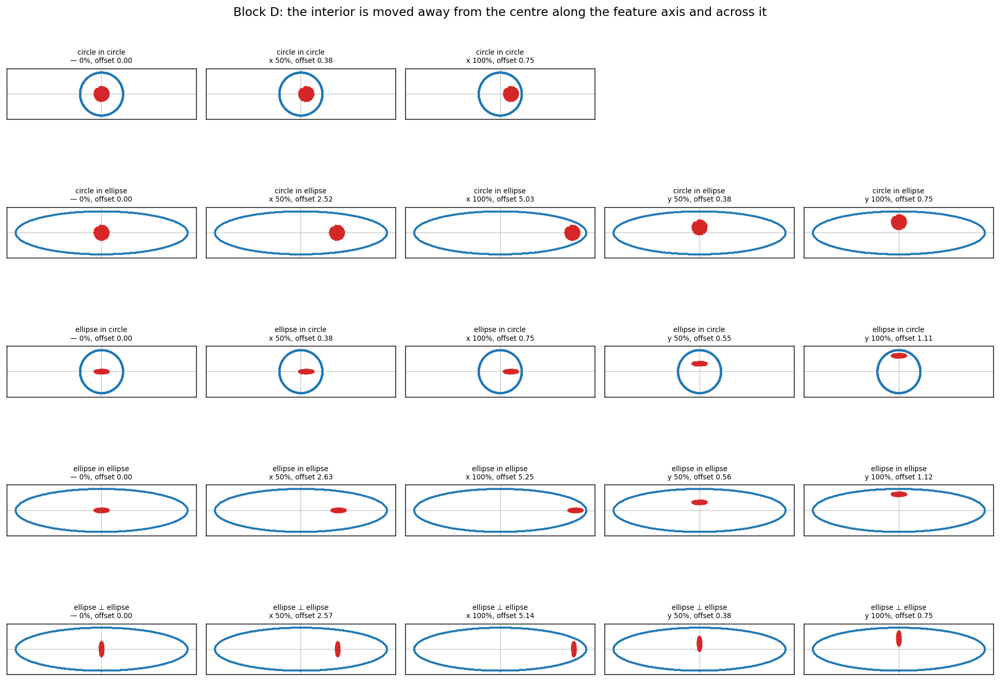

largest admissible offset by family (this is the “100 %”):
  circle in circle     x: 0.75
  circle in ellipse    x: 5.03   y: 0.75
  ellipse in circle    x: 0.75   y: 1.11
  ellipse in ellipse   x: 5.25   y: 1.12
  ellipse ⊥ ellipse    x: 5.14   y: 0.75


In [42]:
D_FAM = ["circle in circle", "circle in ellipse", "ellipse in circle", "ellipse in ellipse",
         "ellipse ⊥ ellipse"]
D_POS = [("x", "0%"), ("x", "50%"), ("x", "100%"), ("y", "50%"), ("y", "100%")]

Dm = cells_meta[cells_meta.block == "D"].copy()
Dm["pair"] = [str(l).split(",")[0].strip() for l in Dm.label]
Dm["axis"] = [str(l).split(",")[1].strip() if len(str(l).split(",")) > 2 else "-"
             for l in Dm.label]
Dm["fraction"] = [str(l).split(",")[-1].strip() for l in Dm.label]

def d_cell(fam, axis, frac):
    q = Dm[(Dm.pair == fam) & (Dm.fraction == frac)]
    if frac == "0%":
        return q.index[0] if len(q) else None
    q = q[q.axis == axis]
    return q.index[0] if len(q) else None

hxD = hyD = 0.0
for fam in D_FAM:
    for ax, fr in D_POS:
        n = d_cell(fam, ax, fr)
        if n is None:
            continue
        h1, h2 = gp.cells_extent([n])
        hxD, hyD = max(hxD, h1), max(hyD, h2)

fig, axes = plt.subplots(5, 5, figsize=(15, 11))
for r, fam in enumerate(D_FAM):
    for c, (ax_, fr) in enumerate(D_POS):
        ax = axes[r, c]; name = d_cell(fam, ax_, fr)
        if name is None:
            ax.axis("off"); continue
        Xc, yc, Ac = gs.dataset_points(name)[:3]
        ax.scatter(Xc[yc == 1, 0], Xc[yc == 1, 1], s=1.3, c=gp.C_INTERIOR, zorder=1)
        ax.scatter(Ac[:, 0], Ac[:, 1], s=1.3, c=gp.C_FEATURE, zorder=2)
        ax.axhline(0, color="#bbb", lw=.6, zorder=0); ax.axvline(0, color="#bbb", lw=.6, zorder=0)
        ax.set_xlim(-hxD, hxD); ax.set_ylim(-hyD, hyD)
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
        off = float(cells_meta.loc[name, "offset_norm"])
        ax.set_title(f"{fam}\n{ax_ if fr != '0%' else '—'} {fr}, offset {off:.2f}", fontsize=7.5)
fig.suptitle("Block D: the interior is moved away from the centre along the feature axis and across it", fontsize=13)
plt.tight_layout(); plt.show()

print("largest admissible offset by family (this is the “100 %”):")
for fam in D_FAM:
    line = []
    for ax_ in ("x", "y"):
        n = d_cell(fam, ax_, "100%")
        if n is not None:
            line.append(f"{ax_}: {float(cells_meta.loc[n, 'offset_norm']):.2f}")
    print(f"  {fam:20s} " + "   ".join(line))


## 5.2 Does the curve follow the interior

Ten panels: five geometries of the pair × two directions of offset. In each — **two distances from the
centroid of the curve**: to the centre of the interior (solid) and to the centre of the feature (dashed), plus a grey
line "the distance between the centres themselves", that is, the size of the offset.

It reads like this: if the solid line lies low while the dashed one goes up together with the grey one — **the curve went after the
interior**. If the other way round, the dashed one low and the solid one rising along the grey one — **the curve
stayed with the feature**.

Each point is the median over all roughly 2,400 curves of the cell (50 models × 20 neurons of layers 1–4 ×
up to 5 rungs), as described in the setting.


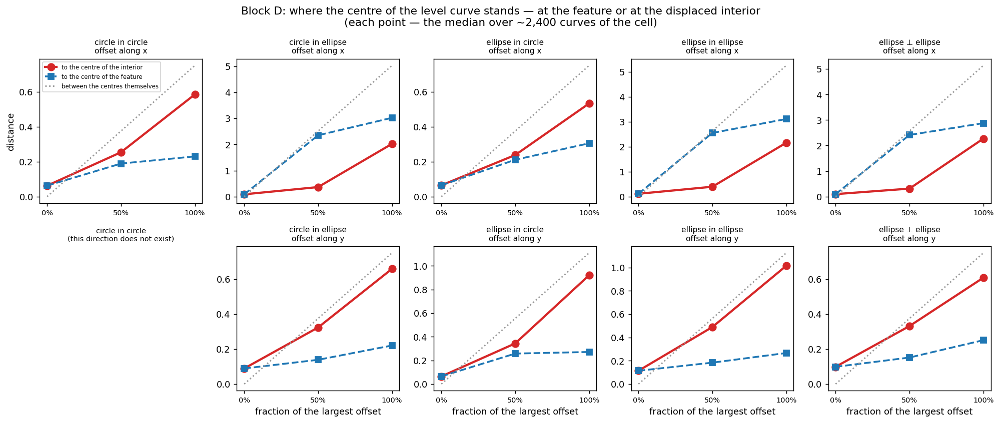

              pair axis fraction  offset  to_interior  to_feature   lam
  circle in circle    x       0%   0.000        0.063       0.063   NaN
  circle in circle    x      50%   0.375        0.254       0.189 0.324
  circle in circle    x     100%   0.750        0.584       0.230 0.221
  circle in circle    y       0%   0.000        0.063       0.063   NaN
 circle in ellipse    x       0%   0.000        0.089       0.089   NaN
 circle in ellipse    x      50%   2.516        0.366       2.352 0.854
 circle in ellipse    x     100%   5.031        2.025       3.024 0.598
 circle in ellipse    y       0%   0.000        0.089       0.089   NaN
 circle in ellipse    y      50%   0.375        0.324       0.139 0.137
 circle in ellipse    y     100%   0.750        0.659       0.220 0.122
 ellipse in circle    x       0%   0.000        0.065       0.065   NaN
 ellipse in circle    x      50%   0.375        0.238       0.211 0.366
 ellipse in circle    x     100%   0.750        0.533       0.30

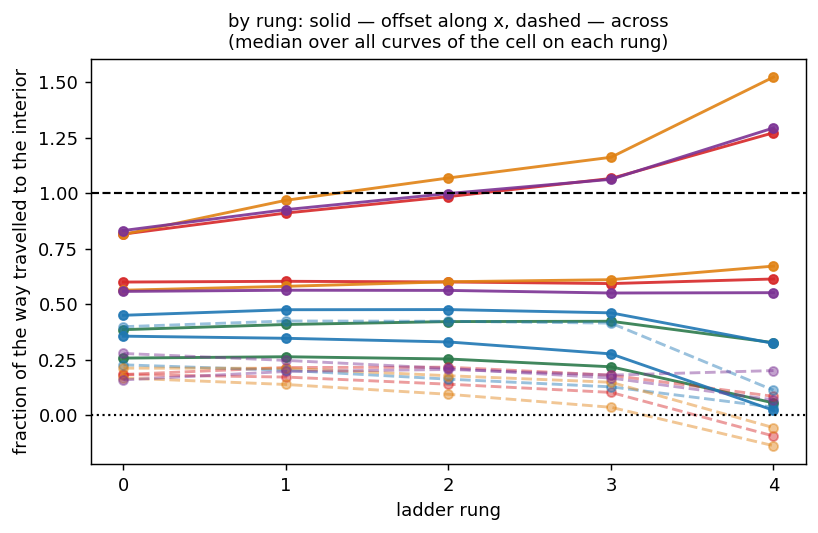

In [43]:
rowsD = []
for fam in D_FAM:
    for ax_, fr in D_POS:
        name = d_cell(fam, ax_, fr)
        if name is None or fr == "0%":
            continue
        m = cells_meta.loc[name]
        off = np.array([float(CO.loc[name, "offset_x"]), float(CO.loc[name, "offset_y"])])
        nrm = float(np.hypot(*off)); u = off/nrm
        g = hl[(hl.dataset_type == name) & (hl.layer_id > 0)]
        lam = (g.cx*u[0] + g.cy*u[1])/nrm
        gg = g[g.a2 >= .10]; a = gg.angle2.values
        rowsD.append(dict(pair=fam, axis=ax_, fraction=fr, offset=nrm, cell=name,
                          lam=float(lam.median()),
                          lam_by_rung=lam.groupby(g.rung).median().reindex(range(5)).values,
                          aspect=float(g.aspect.median()),
                          along=float(((a < 30) | (a > 150)).mean()) if len(a) else np.nan,
                          across=float(((a > 60) & (a < 120)).mean()) if len(a) else np.nan,
                          score=float(m.target_median), floor=float(m.floor), witness=float(m.rate_floor)))
DD = pd.DataFrame(rowsD)
FC = dict(zip(D_FAM, ["#2c7a4b", "#d62728", "#1f77b4", "#e08214", "#7b3294"]))

def d_pair(name):
    m = CO.loc[name]
    c = np.array([float(m.offset_x), float(m.offset_y)])
    g = hl[(hl.dataset_type == name) & (hl.layer_id > 0)]
    return (float(np.hypot(g.cx - c[0], g.cy - c[1]).median()),   # to the interior
            float(np.hypot(g.cx, g.cy).median()),                 # to the feature
            float(np.hypot(*c)))

fig, axes = plt.subplots(2, 5, figsize=(15.5, 6.6))
FR = [0.0, 0.5, 1.0]; FRL = ["0%", "50%", "100%"]
for r, axis in enumerate(("x", "y")):
    for c, fam in enumerate(D_FAM):
        ax = axes[r, c]
        names = [d_cell(fam, axis, fl) for fl in FRL]
        if any(n is None for n in names):
            ax.axis("off")
            ax.set_title(f"{fam}\n(this direction does not exist)", fontsize=8); continue
        vals = [d_pair(n) for n in names]
        ax.plot(FR, [v[0] for v in vals], "o-", color=gp.C_INTERIOR, lw=2.4, ms=8,
                label="to the centre of the interior")
        ax.plot(FR, [v[1] for v in vals], "s--", color=gp.C_FEATURE, lw=2.0, ms=7,
                label="to the centre of the feature")
        ax.plot(FR, [v[2] for v in vals], color="#999", lw=1.6, ls=":",
                label="between the centres themselves")
        ax.set_xticks(FR, FRL, fontsize=8)
        ax.set_title(f"{fam}\noffset along {axis}", fontsize=8.5)
        if c == 0:
            ax.set_ylabel("distance")
        if r == 1:
            ax.set_xlabel("fraction of the largest offset")
axes[0, 0].legend(fontsize=6.5)
fig.suptitle("Block D: where the centre of the level curve stands — at the feature or at the displaced interior\n"
             "(each point — the median over ~2,400 curves of the cell)", fontsize=12)
plt.tight_layout(); plt.show()

rows = []
for fam in D_FAM:
    for axis in ("x", "y"):
        for fl in FRL:
            n = d_cell(fam, axis, fl)
            if n is None:
                continue
            di, df, sh = d_pair(n)
            rows.append(dict(pair=fam, axis=axis, fraction=fl, offset=sh,
                             to_interior=di, to_feature=df,
                             lam=np.nan if sh == 0 else (sh - di)/sh))
DIST = pd.DataFrame(rows).drop_duplicates(subset=["pair", "axis", "fraction"])
print(DIST.round(3).to_string(index=False))

print("\na short summary by the same number that was earlier called λ_pos "
      "(fraction of the way travelled from the feature to the interior):")
WIDE = ["circle in ellipse", "ellipse in ellipse", "ellipse ⊥ ellipse"]   # feature 4:1
for frac in ("50%", "100%"):
    g = DIST[(DIST.axis == "x") & (DIST.fraction == frac) & (DIST.pair.isin(WIDE))]
    h = DIST[(DIST.axis == "x") & (DIST.fraction == frac) & (~DIST.pair.isin(WIDE))]
    print(f"  along x at {frac:>4}: {g.lam.min():.2f}…{g.lam.max():.2f} where the feature is elongated; "
          f"{h.lam.min():.2f}…{h.lam.max():.2f} where it is round")
y = DIST[(DIST.axis == "y") & (DIST.fraction != "0%")]
print(f"  across, any offset: {y.lam.min():.2f}…{y.lam.max():.2f}")

fig, ax = plt.subplots(figsize=(6.4, 4.2))
for r_, row in DD.iterrows():
    ax.plot(range(5), row.lam_by_rung, "o-", color=FC[row.pair], lw=1.6, ms=5,
            alpha=.9 if row.axis == "x" else .45, ls="-" if row.axis == "x" else "--")
ax.axhline(1, color="k", ls="--", lw=1.2); ax.axhline(0, color="k", ls=":", lw=1.2)
ax.set_xticks(range(5)); ax.set_xlabel("ladder rung")
ax.set_ylabel("fraction of the way travelled to the interior")
ax.set_title("by rung: solid — offset along x, dashed — across\n"
             "(median over all curves of the cell on each rung)", fontsize=10)
plt.tight_layout(); plt.show()


**Observations.** All numbers are medians over roughly 2,400 curves of the cell.

- **Along the long axis of an elongated feature the curve almost catches up with the interior.** At an offset of half
  the admissible one, the centre of the curve stands at **0.31–0.40** from the centre of the interior and at **2.35–2.55** from the centre
  of the feature, while the centres themselves have moved 2.5–2.6 apart. That is, the curve has travelled **85–88%** of the way.
- **At the maximal offset it stops keeping up**: the distances become 2.03–2.27 to the
  interior and 2.88–3.11 to the feature at an offset of 5.0–5.3 — **56–60%** travelled. The interior is
  pressed against the end of the feature, and the curve gets stuck roughly halfway.
- **Across, it hardly follows.** "Ellipse in ellipse", maximal offset across: the centres have moved apart
  by 1.13, and the curve stands at **1.01** from the interior and only **0.27** from the feature — **10%** travelled.
  Over all transverse cells — 0.10–0.38.
- **Where the feature is not elongated, the following is weak along x too**: the round pair travels 0.32 and
  0.22 of the way, "ellipse in circle" 0.37 and 0.29. The point is not the direction as such but whether there is
  room in that direction: a round feature has none either along or across.
- **At zero offset both quantities are equal and small** (0.06–0.11) — the curves stand at the common centre, as
  they should. This is a reference point, not a result.
- **The whole family follows the interior**, but the course over the rungs in the two directions is
  **opposite**. With an offset along x the outer rungs follow **more readily**: the fraction of the way travelled
  grows from 0.82 on rung 0 to 1.0–1.5 on rung 4, that is, the far curves even overshoot. With an offset
  across it is the other way round: towards the outer rung the following **fades away**. Along the
  axis of the feature there is enough room further from the centre too; across, the far curves run into the wall and stay
  with the feature.

**Conclusion.** The separating curve follows the interior **as far as the feature allows it**.
This is the first block where the feature shows itself as a limiter directly and in one quantity: where it
leaves room, the following is almost complete; where it does not, there is almost none.


## 5.3 What becomes of the shape meanwhile

Shape is a secondary quantity here, but it behaves unexpectedly. First elongation, then direction.

**For direction it is important to look at the roses, not at the fractions**, because the fractions "along" and "across"
are two numbers out of three (the third, the oblique one, is usually forgotten), and from them one cannot tell "the direction
disappeared" from "the direction changed". The roses show the whole distribution at once.

**What is in the grid of roses.** A row is a family of pairs, four columns:

1. **for comparison** — the same geometry with a **full-size** interior and no offset, that is,
   a cell from blocks A, B or C. It is needed to separate the effect of reducing the interior from the
   effect of the offset;
2. **0%** — the interior is already halved but not shifted;
3. **50%** and 4. **100%** — the same, shifted.

The dataset itself is drawn in the corner of each panel. The rose is built over all curves of the cell that passed the filter
`a₂ ≥ 0.10`; the caption gives the fraction that passed and the median elongation.


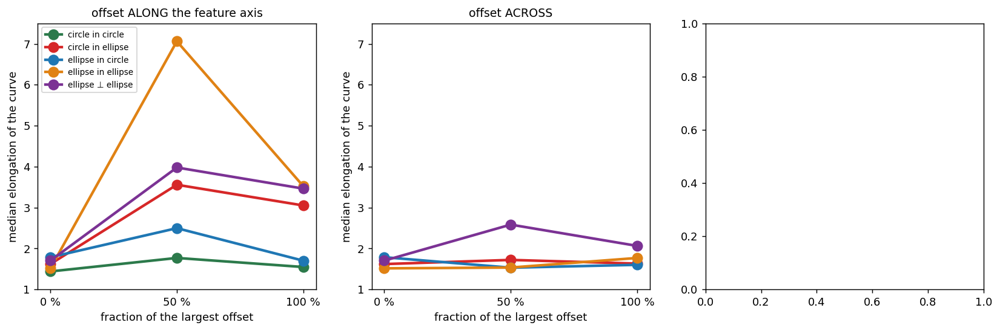

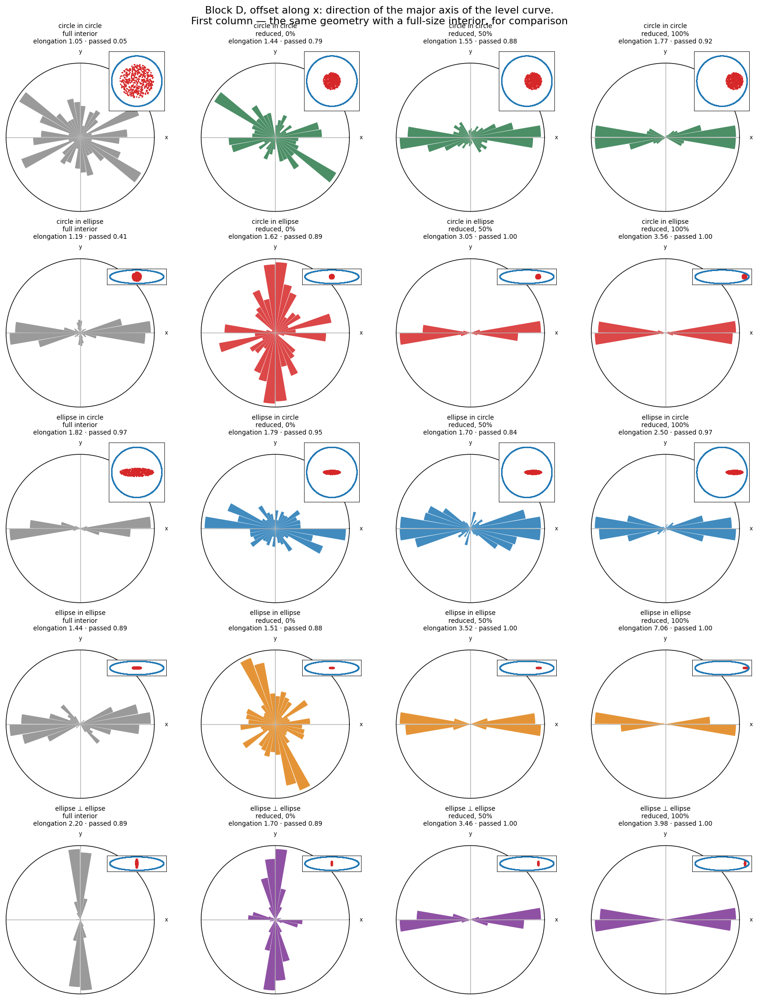

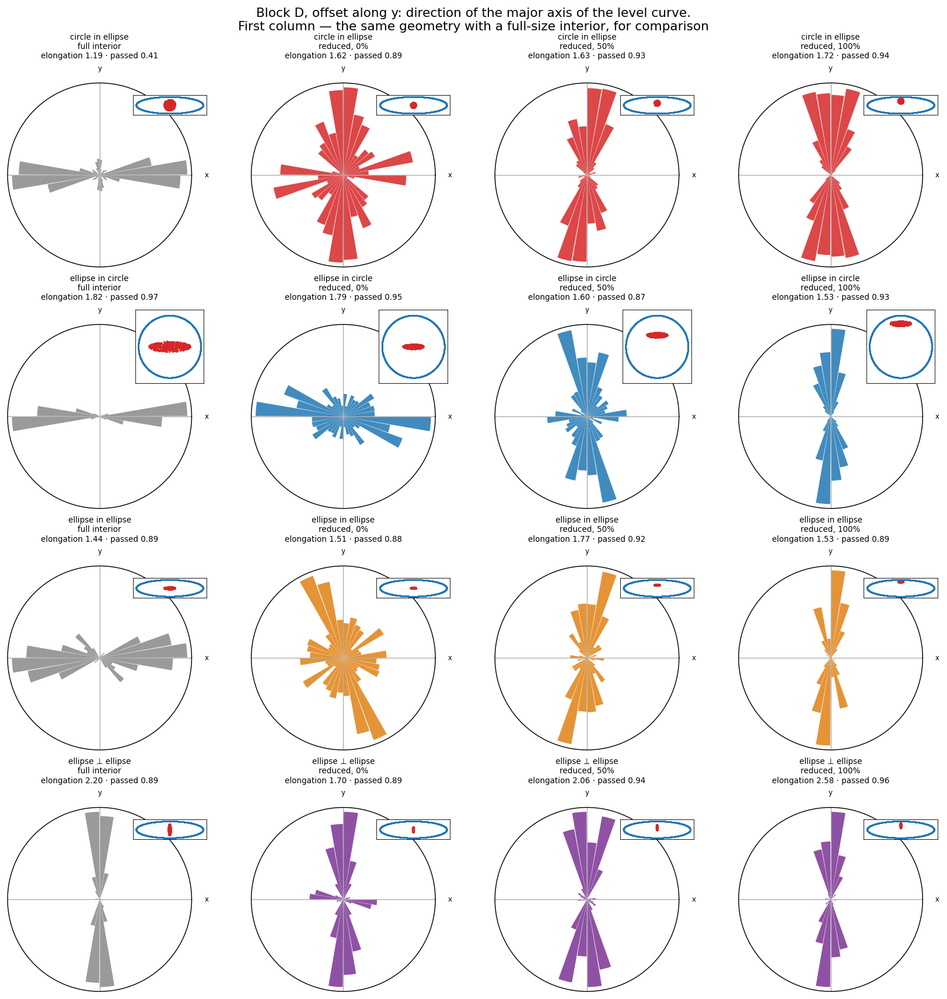

what the reduction of the interior alone does (no offset):
  circle in circle     full: elongation 1.05, along 0.38, across 0.29, passed 0.05  →  reduced: 1.44, 0.38, 0.23, 0.79
  circle in ellipse    full: elongation 1.19, along 0.74, across 0.17, passed 0.41  →  reduced: 1.62, 0.26, 0.52, 0.89
  ellipse in circle    full: elongation 1.82, along 0.97, across 0.00, passed 0.97  →  reduced: 1.79, 0.54, 0.20, 0.95
  ellipse in ellipse   full: elongation 1.44, along 0.80, across 0.01, passed 0.89  →  reduced: 1.51, 0.29, 0.48, 0.88
  ellipse ⊥ ellipse    full: elongation 2.20, along 0.04, across 0.95, passed 0.89  →  reduced: 1.70, 0.22, 0.74, 0.89


In [44]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))
for ax, axis, ttl in [(axes[0], "x", "offset ALONG the feature axis"),
                      (axes[1], "y", "offset ACROSS")]:
    for fam in D_FAM:
        n0 = d_cell(fam, axis, "0%")
        g = DD[(DD.pair == fam) & (DD.axis == axis)].sort_values("fraction")
        if not len(g):
            continue
        a0 = float(hl[(hl.dataset_type == n0) & (hl.layer_id > 0)].aspect.median())
        ax.plot([0, .5, 1.], [a0] + list(g.aspect), "o-", color=FC[fam], lw=2.4, ms=9,
                label=fam)
    ax.set_xticks([0, .5, 1.], ["0 %", "50 %", "100 %"])
    ax.set_xlabel("fraction of the largest offset"); ax.set_ylabel("median elongation of the curve")
    ax.set_ylim(1, 7.5); ax.set_title(ttl, fontsize=10.5)
axes[0].legend(fontsize=7.5)

FULL = {"circle in circle": "g5_f010_i010_s100_o+0000+0000",
        "circle in ellipse": "g5_f040_i010_s100_o+0000+0000",
        "ellipse in circle": "g5_f010_i040_s100_o+0000+0000",
        "ellipse in ellipse": "g5_f040_i040_s100_o+0000+0000",
        "ellipse ⊥ ellipse": "g5_f040_i040T_s100_o+0000+0000"}

def rose_panel(ax, name, title, colour):
    g_all = hl[(hl.dataset_type == name) & (hl.layer_id > 0)]
    g = g_all[g_all.a2 >= .10]; a = g.angle2.values
    both = np.concatenate([np.radians(a), np.radians(a) + np.pi]) % (2*np.pi)
    edges = np.radians(np.arange(0, 361, 10))
    h, _ = np.histogram(both, bins=edges); h = h/max(h.max(), 1)
    ax.bar(edges[:-1] + np.radians(5), h, width=np.radians(9.4), color=colour,
           alpha=.85, edgecolor="none")
    ax.set_yticks([]); ax.set_xticks(np.radians([0, 90, 180, 270]))
    ax.set_xticklabels(["x", "y", "", ""], fontsize=6.5)
    ax.set_title(f"{title}\nelongation {g_all.aspect.median():.2f} · "
                 f"passed {len(g)/max(len(g_all),1):.2f}", fontsize=7.5, pad=6)
    ins = ax.inset_axes([.68, .68, .40, .40])
    Xc, yc, Ac = gs.dataset_points(name)[:3]
    ins.scatter(Xc[yc == 1, 0], Xc[yc == 1, 1], s=.5, c=gp.C_INTERIOR, zorder=1)
    ins.scatter(Ac[:, 0], Ac[:, 1], s=.5, c=gp.C_FEATURE, zorder=2)
    hx3, hy3 = gp.cells_extent([name])
    ins.set_xlim(-hx3, hx3); ins.set_ylim(-hy3, hy3); ins.set_aspect("equal")
    ins.set_xticks([]); ins.set_yticks([])
    for sp in ins.spines.values():
        sp.set_linewidth(.5)

for axis, fams in (("x", D_FAM), ("y", [f for f in D_FAM if f != "circle in circle"])):
    fig, axes = plt.subplots(len(fams), 4, figsize=(13, 3.35*len(fams)),
                             subplot_kw={"projection": "polar"})
    axes = np.atleast_2d(axes)
    for r, fam in enumerate(fams):
        full = [n for n in cells_meta.index if n.startswith(FULL[fam])][0]
        panels = [(full, "full interior")] + [
            (d_cell(fam, axis, fl), f"reduced, {fl}") for fl in ("0%", "50%", "100%")]
        for c, (name, ttl) in enumerate(panels):
            rose_panel(axes[r, c], name, f"{fam}\n{ttl}",
                       FC[fam] if c else "#888")
    fig.suptitle(f"Block D, offset along {axis}: direction of the major axis of the level curve.\n"
                 "First column — the same geometry with a full-size interior, "
                 "for comparison", fontsize=12)
    plt.tight_layout(); plt.show()

print("what the reduction of the interior alone does (no offset):")
for fam in D_FAM:
    full = [n for n in cells_meta.index if n.startswith(FULL[fam])][0]
    small = d_cell(fam, "x", "0%")
    out = []
    for n in (full, small):
        g_all = hl[(hl.dataset_type == n) & (hl.layer_id > 0)]
        g = g_all[g_all.a2 >= .10]; a = g.angle2.values
        out.append((float(g_all.aspect.median()),
                    float(((a < 30) | (a > 150)).mean()), float(((a > 60) & (a < 120)).mean()),
                    len(g)/max(len(g_all), 1)))
    f_, s_ = out
    print(f"  {fam:20s} full: elongation {f_[0]:.2f}, along {f_[1]:.2f}, across {f_[2]:.2f}, "
          f"passed {f_[3]:.2f}  →  reduced: {s_[0]:.2f}, {s_[1]:.2f}, {s_[2]:.2f}, {s_[3]:.2f}")


**Observations.** Elongation is the median over all roughly 2,400 curves of the cell; the fractions of directions are
over those of them that passed the filter `a₂ ≥ 0.10`.

**On elongation.**

- **An offset along the axis of the feature sharply elongates the curve**: 1.62 → 3.05 → 3.56, 1.51 → 3.52 → **7.06**,
  1.70 → 3.46 → 3.98. These are the most elongated curves of the whole experiment — four to five times stronger
  than anything in blocks A, B and C.
- **An offset across does almost nothing** where the objects are elongated along x: 1.62 → 1.63 → 1.72
  and 1.51 → 1.77 → 1.53. The exception is "ellipse ⊥ ellipse" (1.70 → 2.06 → 2.58), where the interior
  is itself elongated along y and the offset goes along it.

**On direction — and here the grid of roses shows what the fractions did not.**

- **Halving the interior by itself is already a strong intervention, not a neutral preparation.**
  At zero offset, compared with the full-size interior: in "circle in ellipse" the direction
  **flips** from horizontal to vertical (along 0.74 → 0.26, across 0.17 → 0.52),
  in "ellipse in ellipse" likewise (0.80 → 0.29 and 0.01 → 0.48). In "circle in circle" the elongation grows
  1.05 → 1.44, and the fraction of curves whose direction is defined at all jumps **0.05 → 0.79**.
  A small interior leaves the curve a lot of room, and it stops being round.
- **In "ellipse ⊥ ellipse" the vertical direction survives the reduction**: 0.95 → 0.74 across.
  That is, it was not the reduction that turned the curves — it only weakened the order.
- **It is the offset that turns them.** In the same "ellipse ⊥ ellipse", after an offset along x the fraction of curves along
  x becomes 0.99 with the fraction across 0.00: the interior is still elongated across, but the curves
  run along. The direction is no longer set by the shape of the objects but by where the pair has been pulled apart.
- **This is the general rule of the block**: with an offset along x the fraction of curves along x is **0.65–1.00**, with an offset
  along y the fraction of curves along y is **0.58–0.93**. Chance would give 0.33 in both cases. (These two
  numbers refer to **different** cells and therefore do not add up: one should compare panel with
  panel, not the fractions with each other.)

**Conclusion.** In block D the shape stops being an independent quantity: it becomes a consequence of
position. Wherever the curve was shifted, that is where it elongated, and the more strongly, the further the shift. And
the preparation of the block — the reduction of the interior — by itself changes the picture so much that the zero
cell of block D cannot be considered "the same as in block A": it is the one to take as the point of reference.


## 5.4 The only place where geometry forces elongation

In all the previous blocks a round level curve separated the classes, and so all the observed
elongation was the network's choice, not a necessity (2.2.3). Block D is the only place where this
stops being true.

The check is the same as in 2.2.3: does a circle exist that contains the interior and lies inside
the feature, **with its centre fixed at the centre of the feature**. With a free centre such a circle exists in
all 56 cells; with a fixed one, not everywhere.


In [ ]:
GEOD = gs.separating_geometry().set_index("dataset_type")
DD2 = DD.copy()
DD2["concentric_circle"] = [bool(GEOD.loc[n, "circle_fits_concentric"]) for n in DD2.cell]
DD2["margin"] = [float(GEOD.loc[n, "circle_margin_concentric"]) for n in DD2.cell]

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))
ok = DD2[DD2.concentric_circle]; bad = DD2[~DD2.concentric_circle]
axes[0].scatter(ok.margin, ok.aspect, s=90, color="#2c7a4b", edgecolor="white",
                label="the concentric circle separates", zorder=3)
axes[0].scatter(bad.margin, bad.aspect, s=90, color="#a03030", edgecolor="white",
                label="does not separate", zorder=3)
axes[0].axvline(0, color="k", lw=1.4)
axes[0].set_xlabel("margin of the concentric circle"); axes[0].set_ylabel("elongation of the curve")
axes[0].legend(fontsize=7.5)
axes[0].set_title("elongation explodes exactly where\nthe round solution disappears", fontsize=10)

alld = pd.read_csv("analysis/results/experiments/exp5_geometry/shape_models.csv")
alld["concentric"] = [bool(GEOD.loc[n, "circle_fits_concentric"]) for n in alld.dataset_type]
axes[1].hist(alld[alld.concentric].observed, bins=np.linspace(1, 7.5, 30), color="#2c7a4b",
             alpha=.8, label=f"separates (n = {int(alld.concentric.sum())})")
axes[1].hist(alld[~alld.concentric].observed, bins=np.linspace(1, 7.5, 30), color="#a03030",
             alpha=.85, label=f"does not separate (n = {int((~alld.concentric).sum())})")
axes[1].set_xlabel("median elongation of the curve of the cell"); axes[1].set_ylabel("cells")
axes[1].legend(fontsize=8)
axes[1].set_title("all 56 cells of the experiment", fontsize=10)

for col, lab, c_ in (("dilation", "dilation", "#e08214"), ("harmonic", "potential", "#2c7a4b"),
                     ("midline", "midline", "#111")):
    axes[2].scatter(alld[alld.block == "D"][col], alld[alld.block == "D"].observed, s=55,
                    color=c_, alpha=.85, label=lab, zorder=3)
axes[2].plot([1, 7.5], [1, 7.5], ls=":", color="k", lw=1.3)
axes[2].set_xlabel("predicted"); axes[2].set_ylabel("observed"); axes[2].legend(fontsize=8)
axes[2].set_title("block D: all three constructions miss", fontsize=10)
fig.suptitle("Block D: where geometry forces elongation for the first time", fontsize=12.5)
plt.tight_layout(); plt.show()

print(f"the concentric circle does not separate in {int((~alld.concentric).sum())} cells of "
      f"{len(alld)} — here they are by name:")
for n in alld[~alld.concentric].dataset_type:
    print(f"  {n}   “{cells_meta.loc[n, 'label']}”   margin "
          f"{float(GEOD.loc[n, 'circle_margin_concentric']):+.2f}   elongation "
          f"{float(alld[alld.dataset_type == n].observed.iloc[0]):.2f}")
print(f"\nmedian elongation: where it separates — "
      f"{alld[alld.concentric].observed.median():.2f}; where not — {alld[~alld.concentric].observed.median():.2f}")
from scipy.stats import spearmanr
for col, lab in (("dilation", "dilation"), ("harmonic", "potential"), ("midline", "midline")):
    g = alld[alld.block == "D"]
    print(f"  {lab:16s} Spearman {spearmanr(g[col], g.observed)[0]:+.3f}, "
          f"|error| {np.abs(g[col]-g.observed).mean():.2f}")
U_D = cell_uncertainty(sorted(cells_meta[cells_meta.block == "D"].index))
print(f"  uncertainty of the numbers themselves ±{np.median(U_D):.2f}; range over the block "
      f"{alld[alld.block=='D'].observed.max() - alld[alld.block=='D'].observed.min():.2f}; "
      f"in the extreme cell observed "
      f"{alld[alld.block=='D'].observed.max():.2f}, the best construction gives "
      f"{alld.loc[alld[alld.block=='D'].observed.idxmax(), ['dilation','harmonic','midline']].min():.2f}")


**Observations.**

- **The concentric circle stops separating in exactly six cells of 56**, and here they are:
  "circle in ellipse, x, 50%" and "x, 100%", "ellipse in ellipse, x, 50%" and "x, 100%",
  "ellipse ⊥ ellipse, x, 50%" and "x, 100%". All six have one thing in common: **an elongated feature plus an offset
  along its long axis**. Not a single cell with an offset across and not a single one with a round feature gets in
  here. These are exactly the cells where the elongation is 3.05–7.06: the median over them is **3.54** against
  **1.60** over the other fifty, and the ranges do not overlap.
- **The threshold is seen directly**: on the left panel the elongation shoots up exactly when the margin passes through
  zero. As long as the round solution is available, the curves are in the range 1.4–2.6; as soon as it disappears,
  3.0–7.1.
- **All three constructions miss here, and in different ways.** Dilation gives Spearman +0.15 and an error of
  1.01, the potential +0.54 and 1.12, the midline **+0.61**, that is, it unexpectedly turns out to be
  the best in ordering. The reason is understandable: the midline follows the feature, and in block D
  the elongated feature really does become the main thing, because it is hit.
- **The misses here cannot be put down to noise**: errors of 1.01, 1.12 and 1.03 at an uncertainty of the numbers themselves
  of ±0.21, and in the extreme cell **7.06** is observed where the best of the constructions gives **1.55**.
  Block D is impassable for the geometric constructions.

**Conclusion.** Block D contains the only cells of the experiment where the elongation is **forced**
by geometry rather than chosen by the network. This makes them both the most informative and the hardest: where
there is no round solution, none of our constructions works.


## 5.5 What becomes of the witnessing

Finally: how the offset affects the structural criterion.


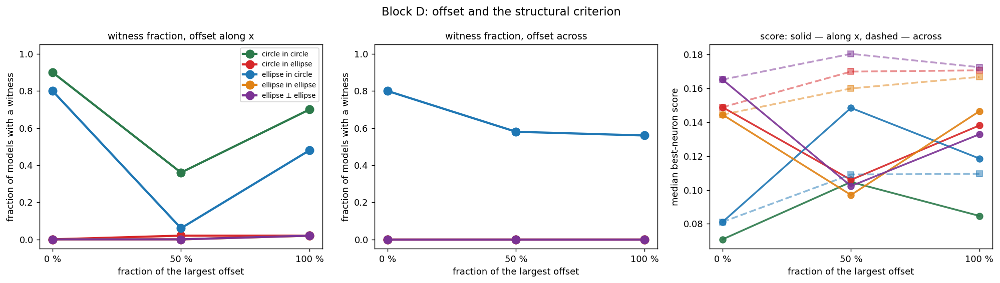

              pair axis fraction  score  floor  witness
  circle in circle    x      50%  0.085  0.107     0.70
  circle in circle    x     100%  0.105  0.096     0.36
 circle in ellipse    x      50%  0.138  0.045     0.02
 circle in ellipse    x     100%  0.106  0.043     0.02
 circle in ellipse    y      50%  0.171  0.059     0.00
 circle in ellipse    y     100%  0.170  0.058     0.00
 ellipse in circle    x      50%  0.119  0.111     0.48
 ellipse in circle    x     100%  0.148  0.108     0.06
 ellipse in circle    y      50%  0.110  0.122     0.56
 ellipse in circle    y     100%  0.109  0.117     0.58
ellipse in ellipse    x      50%  0.146  0.050     0.02
ellipse in ellipse    x     100%  0.097  0.048     0.00
ellipse in ellipse    y      50%  0.167  0.058     0.00
ellipse in ellipse    y     100%  0.160  0.056     0.00
 ellipse ⊥ ellipse    x      50%  0.133  0.052     0.02
 ellipse ⊥ ellipse    x     100%  0.102  0.038     0.00
 ellipse ⊥ ellipse    y      50%  0.172  0.058  

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))
for ax, axis, ttl in [(axes[0], "x", "witness fraction, offset along x"),
                      (axes[1], "y", "witness fraction, offset across")]:
    for fam in D_FAM:
        n0 = d_cell(fam, axis, "0%")
        g = DD[(DD.pair == fam) & (DD.axis == axis)].sort_values("fraction")
        if not len(g):
            continue
        w0 = float(cells_meta.loc[n0, "rate_floor"])
        ax.plot([0, .5, 1.], [w0] + list(g.witness), "o-", color=FC[fam], lw=2.4, ms=9, label=fam)
    ax.set_xticks([0, .5, 1.], ["0 %", "50 %", "100 %"]); ax.set_ylim(-.05, 1.05)
    ax.set_xlabel("fraction of the largest offset"); ax.set_ylabel("fraction of models with a witness")
    ax.set_title(ttl, fontsize=10.5)
axes[0].legend(fontsize=7.5)

for fam in D_FAM:
    for axis, mk in (("x", "o-"), ("y", "s--")):
        n0 = d_cell(fam, axis, "0%")
        g = DD[(DD.pair == fam) & (DD.axis == axis)].sort_values("fraction")
        if not len(g):
            continue
        s0 = float(cells_meta.loc[n0, "target_median"])
        axes[2].plot([0, .5, 1.], [s0] + list(g.score), mk, color=FC[fam], lw=2.0, ms=7,
                     alpha=.9 if axis == "x" else .5)
axes[2].set_xticks([0, .5, 1.], ["0 %", "50 %", "100 %"])
axes[2].set_xlabel("fraction of the largest offset"); axes[2].set_ylabel("median best-neuron score")
axes[2].set_title("score: solid — along x, dashed — across", fontsize=10)
fig.suptitle("Block D: offset and the structural criterion", fontsize=12.5)
plt.tight_layout(); plt.show()

print(DD[["pair", "axis", "fraction", "score", "floor", "witness"]].round(3).to_string(index=False))


**Observations.**

- **Where there were witnesses, the offset kills them.** The round pair: 0.90 → 0.70 → 0.36. "Ellipse in
  circle" along x: 0.80 → 0.48 → 0.06. The feature meanwhile did not change — only the interior moved.
- **Across, it kills more weakly**: for "ellipse in circle" 0.80 → 0.56 → 0.58, that is, it hardly falls.
  Again the same asymmetry: across, the curve does not follow the interior, and so it does not leave the feature either.
- **Where there were no witnesses, the offset changes nothing** — the three families with an elongated feature
  stand at 0.00–0.02 at any offset.
- **The score meanwhile behaves oppositely in the two halves.** For a round feature it worsens
  (0.071 → 0.105, 0.081 → 0.148), for an elongated one it **improves** (0.149 → 0.106, 0.144 → 0.097,
  0.165 → 0.102). The second is explainable: with an offset along x the curve elongates and becomes similar
  to the elongated feature, that is, it comes closer to it. But the floor of the cell falls together with the score
  (0.057 → 0.043), so the witness fraction stays zero: it is not only the curves that came closer, but also
  the nulls.

**Conclusion.** The offset of the interior destroys witnessing in exactly the same way as its rotation in block B, and
through the same mechanism: the curve goes after the interior and stops coinciding with the unchanged
feature.


## 5.6 Summary of block D

1. **The curve follows the displaced interior as far as the feature allows.** Along the
   long axis of an elongated feature, at a half offset the centre of the curve stands at 0.31–0.40 from the centre of the
   interior with the centres 2.5–2.6 apart — **85–88%** of the way travelled; at the maximal
   offset **56–60%**; across — **10–38%** at any offset; for a round feature weakly in both directions
   (22–37%). The whole family of rungs follows the interior, not a single curve.
2. **The shape becomes a consequence of position.** An offset along the axis of the feature gives the most elongated curves
   of the whole experiment (up to **7.06**), an offset across almost nothing (1.53–1.77). The curve elongates
   **along the direction of the offset**, including against the shape of both objects: in "ellipse ⊥ ellipse"
   the interior is elongated across, yet after an offset along x 0.99 of the curves run along x.
3. **The preparation of the block itself changes the picture.** Halving the interior at zero
   offset flips the direction in two families of five and raises fourfold to fifteenfold
   the fraction of curves with a defined direction. That is why the reference point in block D is its
   own zero cell, not the cell of the same name in block A.
4. **This is the only place in the experiment where elongation is forced by geometry.**
   The concentric circle stops separating in 6 cells of 56 — all of them in block D, and exactly
   they have an elongation of 3.05–7.06 against 1.60 in the other fifty.
5. **All three geometric constructions fail here** (+0.15, +0.54, +0.61 in
   ordering, errors of 1.01–1.12 at an uncertainty of the numbers themselves of **±0.21**; in the extreme cell
   7.06 against 1.55). And the best
   unexpectedly turns out to be the midline — the very one that was worst in block A: when the feature
   really is hit, following it becomes the right thing.
6. **The offset destroys witnessing in the same way as the rotation in block B**: 0.90 → 0.36 and 0.80 → 0.06 with
   an unchanged feature. The score at an elongated feature improves meanwhile, but the floor falls together with it,
   so the witness fraction does not grow.
7. As everywhere, these are statements about the **agreement** of quantities: there is no ablation, causes are not discussed.


---


# 6. Synthesis

The four blocks measured four different quantities, on different grids. Here they are brought together:
first what has been measured, then what adds up from it, then what does not.


## 6.1 What has been measured

| block | main quantity | result |
|---|---|---|
| **A** (16 cells) | elongation of the curve | the median across cells **1.05–1.85** with objects from 1 to 4; it is moved by the interior (marginal effect 0.46, monotone), not by the feature (0.14, non-monotone) |
| **A** | the fraction of shape passed on | about **41%** of the elongation of the interior passes through the curve; the observed shape lies between the circle and the shape of the interior in 27 cells of 27 |
| **A** | distribution | not one mode: above elongation 2 lives a separate **population** (weight up to 34%), confirmed by four independent checks |
| **B** (16 cells) | direction of the major axis | with a round interior the curve runs **along the feature** (0.74–0.93); with a round feature **along the interior** (0.93–0.99); when the axes of the objects compete, **the interior wins 9 times out of 9** (0.57–0.96 against 0.02–0.34) |
| **B** | paired comparison | turning the interior with a **bitwise identical feature** worsens the score in 9 pairs of 9 and drops the witness fraction in 7 of 9 |
| **C** (12 cells) | elongation at an unchanged geometry | moving points from the feature inside moves the median **1.59 → 2.97**, the shift is population-wide (92% of the models) |
| **D** (23 cells) | position of the centre of the curve | along the long axis of an elongated feature the curve travels **85–88%** of the way to the displaced interior at an offset of half the admissible one and **56–60%** at an offset of the whole admissible one; across — **10–38%** at any offset |
| **D** | elongation | an offset along the axis of the feature gives the most elongated curves of the experiment (up to **7.06**); the curve elongates **along the direction of the offset** |

Plus two measurements common to all the blocks:

* **witnessing is destroyed with the feature unchanged** — twice and in two different ways: by turning
  the interior (block B) and by shifting it (block D);
* **a round level curve separates the classes in 50 cells of 56**, so almost all the observed
  elongation is the network's choice, not a necessity. The six exceptions are in block D.


## 6.2 Three quantities turned out to be three different questions

When starting the experiment, it was natural to think that "the shape of the level curve" is one quantity. This
turned out not to be so: **elongation, direction and position behave differently and answer
different questions**, and they must not be confused.

* **Elongation** is the most inert. It is compressed: the curve carries only about 41% of the elongation of the
  interior, and the shape of the feature moves it weakly (marginal effect 0.14 against 0.46). In block C it is
  moved even by something that is not geometry — the density of points.
* **Direction** is the cleanest. It is neither compressed nor blurred: each object on its own
  turns the curve towards itself almost completely (0.74–0.93 along the feature with a round
  interior, 0.93–0.99 along the interior with a round feature), and when the axes compete, the answer is
  unambiguous — the interior. It is direction that gave the only measurement of the whole experiment
  where a model's miss cannot be put down to calibration: the midline of the gap is off by **90°**
  nine times out of nine.
* **Position** is the most "obedient": the curve follows the interior as far as the feature
  allows it, and this is seen as a continuous quantity, not as a "yes/no".

Hence a practical consequence for the programme: **the structural criterion sees only the first of the three**.
It measures the distance from the curve to the feature, that is, it mixes shape, size and position into one number.
Everything we learned in blocks B and D is invisible in this number — and that is exactly why it falls so sharply
when the pair is turned or pulled apart.


## 6.3 The cross-cutting pattern

All four blocks fit into one statement, and it is the very one that was named at the beginning of the
notebook:

> **The feature sets the bounds of the possible, and the interior is what is chosen within those bounds.**

Let us take it apart piece by piece, because each half rests on its own measurements.

**"The interior chooses" — four independent confirmations.**

1. The shape of the curve follows the shape of the interior more strongly than the shape of the feature (block A: marginal
   effects 0.46 against 0.14).
2. When the axes of the objects collide, the direction of the curve is set by the interior — in all nine
   cells (block B).
3. The position of the curve follows the position of the interior (block D: 85–88% of the way at an offset of
   half the admissible one along the long axis of an elongated feature).
4. All this is destroyed if **only** the interior is touched, leaving the feature bitwise as it was
   (blocks B and D).

**"The feature sets the bounds" — three confirmations, and all three "by contradiction".**

1. As long as a round curve separates the classes, the shape of the feature explains almost nothing: the aspect of the midline
   of the gap, which obediently follows both objects, gives a rank correlation of **+0.12** with the
   observed (block A).
2. As soon as the feature starts to get in the way — in the six cells of block D where the concentric circle
   stops separating — the elongation jumps to **3.05–7.06** against 1.60 in the other
   fifty. The ceiling is silent until it is hit, and becomes decisive once it is.
3. Following the interior is limited **by exactly how much room the feature has left**: along its
   long axis the curve travels 85–88% of the way at an offset of half the admissible one and 56–60% at an
   offset of the whole admissible one — the more tightly the interior is pressed against the end of the feature, the harder it is to keep up with
   it; across, where there is no room, 10–38% at any offset.

**But "bounds" does not mean "silence": the feature acts within them too.** Its voice is heard where
the interior does not drown it out — at the edge of the grid with a round interior. There the curve elongates
following the feature (the median elongation **1.05** for the pair "circle in circle" against **1.19–1.23** as
soon as the feature is elongated) and turns along it (0.74–0.93 of the curves). The correct formulation is
therefore not "the feature has no influence" but **"the influence of the feature is weaker and loses in a direct collision"**:
0.14 against 0.46 in elongation and 0.02–0.34 against 0.57–0.96 in direction.

**What this formula lacks — and this is a result too.** The curve is not a copy of the interior even
where nothing gets in the way: it is systematically rounder (it passes on 41% of the elongation). So between
"the interior chooses" and "the curve is the interior" there is something else — a smoothing that none
of the tested constructions reproduces quantitatively.


## 6.4 What did not add up

Four places where the experiment gives no answer, and all four are worth naming explicitly.

**No geometric construction describes the observed in full.** Five have been tested
(the midline of the gap, the maximum-gap curve, the uniform measure on admissible curves,
dilation of the interior, the equilibrium potential of the pair; details are in Section 10.9 of the paper).
The best is the potential, with a mean error of 0.12 at an uncertainty of the predicted numbers themselves of ±0.09.
But **none gives both halves
of the effect of the feature**: the rise of elongation at a round interior is reproduced only by
the potential, the fall at an elongated one only by dilation. And in block D all three fail.

**Geometry is in principle not enough.** Block C showed that at a bitwise identical geometry
the shape changes almost twofold depending on how the points are distributed. So the right formulation is not
"shape as a function of geometry" but "shape as a function of geometry **and** data", and the second argument
the experiment did not study.

**"Freedom" remained untested.** The natural hypothesis — that the influence of the interior is the
stronger, the less room the curve has — is not refuted but **untested**: in this design all
measures of freedom are coupled with the elongation of the interior at +0.68…+0.79, because the grid elongates the
interior at a fixed major semi-axis. An axis is needed that changes the **size** of the interior at an
unchanged **shape**.

**Two unexplained phenomena.** The diagonal directions in block C (at 800 points inside more than
half of the curves go off at ≈45° in three geometries of four) and the failure of all models in block D.


## 6.5 What this does to experiments 1 and 2

Experiments 1 and 2 measured in a configuration where the feature and the interior are **both round and
concentric**. Now it can be seen what is special about this point.

* There "the curve follows the feature" and "the curve follows the interior" give **one and the same
  picture**, because round concentric objects have one and the same shape, one and the same
  position and no direction. The hypotheses could not be told apart not through an oversight but
  in principle.
* As soon as the objects are separated, the interior wins — in shape, in direction and in
  position. So what in experiments 1 and 2 was read as "the neuron witnesses the
  circle" is, in their configuration, indistinguishable from "the neuron encircles the disk".
* And this is not nitpicking: witnessing can be **switched off with the feature bitwise unchanged** —
  it is enough to turn the interior (witness fraction 0.92 → 0.58) or to shift it (0.80 → 0.06).

**The defensible formulation after experiment 5.** It is about one instrument here —
the **structural** criterion — and about it one can say precisely: it answers not about the feature by itself but
about the **gap** between the feature and the interior, taken as a whole, as an "annulus", not as its outer
boundary. A topological feature enters its answer exactly insofar as it forms this gap;
in experiments 1 and 2 it formed it completely — that is why everything agreed there.
Which characteristics of the gap determine the answer — the shapes of the two boundaries, their relative
position, relative sizes, the densities of points on them — experiment 5 does not find out; it
shows only that one outer boundary is not enough.


---


# 7. Results and conclusions

The final statements. Each comes with the numbers it rests on and the boundary beyond which it
stops being true.

## The main thing

> **The separating level curve of a neuron is chosen by the interior within the bounds set by the feature.**

This is the only statement that is confirmed by all four blocks, each on its own
quantity, and refuted by none.

## Established

**1. The shape of the level curve is moved more strongly by the interior than by the feature.** The marginal effect of the elongation
of the interior on the elongation of the curve is **0.46** and monotone; the effect of the feature is **0.14** and not
monotone (block A, 16 cells, ~40,000 curves).
*Boundary:* this is a comparison of two effects, not a statement that the feature does not act — see point 2.
Besides, the axis "elongation of the feature" is not pure: along it the area of the feature also grows fourfold, so
part of its effect may be an effect of relative size.

**2. The direction of the curve is set by both objects; when the axes collide, the interior wins.**
Each object on its own turns the curve towards itself: with a round interior it runs
**along the feature** in 0.74–0.93 of cases and elongates following it — the median elongation rises
from **1.05** for the pair "circle in circle" to **1.19–1.23** as soon as the feature is elongated; with a round feature
the curve runs along the interior in 0.93–0.99. When, however, the axes of the objects are turned relative to each
other, the curve runs along the interior in **0.57–0.96** of cases against **0.02–0.34** along the feature —
in all nine such cells (block B).
*Boundary:* "wins" is said of a direct collision of axes and of nothing more; where the
interior is round, the effect of the feature is seen cleanly and it is real — it is just small in magnitude (0.14
against 0.46 in elongation). Measured at aspects 1.5–4; with a weakly elongated interior
the separation is weakest (0.57 against 0.34).

**3. The position of the level curve follows the position of the interior as far as the feature
allows.** The offset is measured everywhere as a fraction of **the largest one this pair admits**. Along the
long axis of an elongated feature, where there is room, the curve travels **85–88%** of the way to the displaced
interior at an offset of half the admissible one and **56–60%** at an offset of the whole admissible one:
the more tightly the interior is pressed against the end of the feature, the harder it is to keep up with it. Across, where there is no
room, the curve travels **10–38%** at any offset (block D, 23 cells).
*Boundary:* the interior in block D is half the size, and this reduction itself is a noticeable intervention:
it flips the direction in two families of five.

**4. Witnessing is destroyed with the feature held fixed.** Turning the interior with a bitwise identical
feature worsens the score in 9 pairs of 9 and drops the witness fraction in 7 of 9 (0.92 → 0.58,
0.56 → 0.10); shifting the interior does the same (0.90 → 0.36, 0.80 → 0.06).
*Boundary:* "is destroyed" here means a drop in the fraction of models with a witness, measured against the
cell's own floor; it is not a statement about what happens inside the network.

**5. The curve is systematically rounder than what it follows.** About **41%** of the elongation of the interior
passes through it (median over the concentric cells, range 0.10–0.78), and the observed
shape lies between the circle and the shape of the interior **in 27 cells of 27**.
*Boundary:* the fraction 0.41 is measured but not derived from any geometric construction.

**6. The shape is not a function of the geometry alone.** At a **bitwise identical** geometry, moving
points from the feature inside moves the median elongation **1.59 → 2.97**; the shift is population-wide — 92%
of the models (block C, 12 cells).
*Boundary:* the strong effect is observed in one geometry of four; in two it is half as strong, in
one it is absent.

**7. Almost all the observed elongation is a choice, not a necessity.** A round level curve
separates the classes in **50 cells of 56**. The six exceptions are all in block D, all with an offset along the
long axis of an elongated feature, and exactly they have an elongation of **3.05–7.06** against **1.60** for the other
fifty.
*Boundary:* "separates" was checked for a circle centred at the centre of the feature; with a free centre
such a circle exists in all 56 cells.

**8. The best geometric description is the equilibrium potential of the pair**, with a mean error of **0.12** in
elongation — at an uncertainty of the predicted numbers themselves of **±0.09** — and zero fitted
shape parameters. Five
constructions were tested and compared on the same data (Section 10.9 of the paper).
*Boundary:* no construction reproduces both halves of the effect of the feature, and in block D
all of them fail.

## What this means for the programme

**The structural criterion answers about the gap, not about the feature.** The caveat about which
instrument is meant is essential: the programme has four criteria, and here it is only about
the **structural** one — the one that measures the distance from the level curve to the feature. Experiment 5 shows
that its answer is determined not by the outer boundary of the pair but by **the whole gap between the feature and the
interior** — the "annulus" as a whole. A topological feature gets into this answer exactly
insofar as it forms the gap: in experiments 1 and 2 it formed it completely
(the objects are round and concentric), and that is why their results remain true — but they can no longer be read as
"the neuron sees a circle": in that configuration this is indistinguishable from "the neuron encircles a
disk".

We deliberately do not use the formulation "alignment with the boundary between the classes": it is easy to
confuse with the separating surface of the whole network, `f(x) = 0.5`, whereas we are talking about the level curves of individual
neurons, and they stand all across the gap, not on one surface.

**Which characteristics of the gap determine the answer is not established.** The candidates, each of
which experiment 5 touches but none of which it isolates: the shapes of the two boundaries (blocks A and B),
the relative position of the boundaries (block D), their relative sizes (not tested, see the open
questions), the densities of points on the boundaries (block C — density does enter). All that has been established is that
one outer boundary is not enough.

**Witnessing is a property of the pair.** This has been shown twice and in two different ways: one and the same
circle can be made witnessed or not by turning (block B) or shifting (block D)
the set of the opposite class inside it.

**There is no ablation here**, so everything said is about the **agreement** of measured quantities. Not one
statement above says that a neuron "encodes" or "computes" anything.

## What remains open

1. **No construction describes the observed in full** — neither in block A (both halves of the effect of the
   feature), nor, all the more, in block D.
2. **The role of relative size is untested.** The hypothesis "the influence of the interior is the stronger, the
   less freedom" is not refuted but untestable on this grid: all measures of freedom are coupled with the
   elongation of the interior at +0.68…+0.79. An axis `interior_scale` at an unchanged shape is needed —
   four or five cells per shape of the pair.
3. **Diagonal directions in block C**: at 800 points inside more than half of the curves go off
   at ≈45° in three geometries of four, including the one where both objects are elongated along one axis.
4. **The second half of the function is the data.** Block C showed that the shape also depends on the distribution of
   points; how exactly, the experiment did not study.
